# Blocco 2 — Analisi per macro-capacità

Questo notebook riorganizza i risultati già prodotti dai notebook precedenti in tre sezioni:

1. **Classificazione**, aggregata sui sei task classificatori;
2. **Similarità numerica**, approfondita sul task STS-B;
3. **Generazione testuale**, analizzata separatamente con BLEU, ROUGE, BERTScore e valutazione soggettiva A/B.

Il notebook non genera presentazioni, copertine o slide. Produce soltanto:

- tabelle mostrate nel notebook;
- file CSV di supporto;
- grafici PNG relativi alle singole analisi.

Le celle marcate come **alternative** sono esperimenti grafici aggiuntivi. Possono essere eliminate senza compromettere le analisi principali.

In [588]:
# CELLA 1 — Importa le librerie, individua automaticamente la root del progetto,
# definisce modelli, task, colori e cartelle di output del Blocco 2.

from pathlib import Path
from importlib.util import find_spec
import importlib
import json
import os
import subprocess
import sys
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from matplotlib import colors as mcolors
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle
from IPython.display import display
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import cohen_kappa_score


PROJECT_MARKER = (
    Path("data")
    / "metrics"
    / "primary_task_scores.csv"
)


def is_project_root(candidate: Path) -> bool:
    """Restituisce True quando la cartella contiene il marcatore del progetto."""

    try:
        candidate = Path(candidate).expanduser().resolve()
    except OSError:
        return False

    return (
        candidate.is_dir()
        and (candidate / PROJECT_MARKER).is_file()
    )


def search_nearby_project_roots(
    start_directory: Path,
    maximum_depth: int = 4,
) -> list[Path]:
    """
    Cerca root candidate nelle sottocartelle vicine
    senza scandire tutto il disco.
    """

    start_directory = (
        Path(start_directory)
        .expanduser()
        .resolve()
    )

    excluded_names = {
        ".git",
        ".idea",
        ".ipynb_checkpoints",
        "__pycache__",
        "node_modules",
        "venv",
        ".venv",
        "env",
        ".env",
        "site-packages",
        "dist",
        "build",
    }

    roots = []

    for current_root, directory_names, file_names in os.walk(
        start_directory
    ):
        current_path = Path(current_root)

        try:
            depth = len(
                current_path
                .relative_to(start_directory)
                .parts
            )
        except ValueError:
            continue

        directory_names[:] = [
            name
            for name in directory_names
            if name not in excluded_names
        ]

        if depth >= maximum_depth:
            directory_names[:] = []

        if (
            current_path.name == "metrics"
            and current_path.parent.name == "data"
            and "primary_task_scores.csv" in file_names
        ):
            candidate = (
                current_path
                .parent
                .parent
                .resolve()
            )

            if is_project_root(candidate):
                roots.append(candidate)

    return list(dict.fromkeys(roots))


def find_project_root() -> tuple[Path, str]:
    """
    Individua la root tramite variabile d'ambiente,
    cartelle superiori o ricerca locale.
    """

    environment_value = os.environ.get(
        "SOASEC_PROJECT_ROOT"
    )

    if environment_value:
        environment_candidate = Path(
            environment_value
        )

        if is_project_root(environment_candidate):
            return (
                environment_candidate
                .expanduser()
                .resolve(),
                "variabile d'ambiente SOASEC_PROJECT_ROOT",
            )

        warnings.warn(
            "SOASEC_PROJECT_ROOT è impostata ma non punta "
            "a una root valida. Procedo con la ricerca automatica."
        )

    current_directory = Path.cwd().resolve()

    for candidate in [
        current_directory,
        *current_directory.parents,
    ]:
        if is_project_root(candidate):
            return (
                candidate,
                "cartella corrente o cartella superiore",
            )

    roots = []
    search_bases = [
        current_directory,
    ]

    if current_directory.parent != current_directory:
        search_bases.append(
            current_directory.parent
        )

    for search_base in search_bases:
        roots.extend(
            search_nearby_project_roots(
                start_directory=search_base,
                maximum_depth=4,
            )
        )

    roots = list(dict.fromkeys(roots))

    if len(roots) == 1:
        return (
            roots[0],
            "ricerca nelle sottocartelle vicine",
        )

    if len(roots) > 1:
        formatted_roots = "\n".join(
            f"- {root}"
            for root in roots
        )

        raise RuntimeError(
            "Sono state trovate più possibili root del progetto:\n"
            f"{formatted_roots}\n\n"
            "Imposta SOASEC_PROJECT_ROOT oppure avvia Jupyter "
            "dalla root corretta."
        )

    raise FileNotFoundError(
        "Impossibile individuare automaticamente la root "
        "del progetto.\n\n"
        f"Cartella corrente: {current_directory}\n"
        f"Marcatore cercato: {PROJECT_MARKER}"
    )


PROJECT_ROOT, PROJECT_ROOT_SOURCE = (
    find_project_root()
)

METRICS_DIR = (
    PROJECT_ROOT
    / "data"
    / "metrics"
)

BLOCK_2_TABLES_DIR = (
    PROJECT_ROOT
    / "data"
    / "final_tables"
    / "block_2"
)

BLOCK_2_PLOTS_DIR = (
    PROJECT_ROOT
    / "data"
    / "visualizations"
    / "block_2"
)

CLASSIFICATION_PLOTS_DIR = (
    BLOCK_2_PLOTS_DIR
    / "01_classification"
)

CLASSIFICATION_ALT_DIR = (
    CLASSIFICATION_PLOTS_DIR
    / "alternatives"
)

NUMERIC_PLOTS_DIR = (
    BLOCK_2_PLOTS_DIR
    / "02_numeric_similarity"
)

NUMERIC_ALT_DIR = (
    NUMERIC_PLOTS_DIR
    / "alternatives"
)

GENERATION_PLOTS_DIR = (
    BLOCK_2_PLOTS_DIR
    / "03_generation"
)

GENERATION_ALT_DIR = (
    GENERATION_PLOTS_DIR
    / "alternatives"
)

SUMMARY_PLOTS_DIR = (
    BLOCK_2_PLOTS_DIR
    / "04_summary"
)


for directory in [
    BLOCK_2_TABLES_DIR,
    BLOCK_2_PLOTS_DIR,
    CLASSIFICATION_PLOTS_DIR,
    CLASSIFICATION_ALT_DIR,
    NUMERIC_PLOTS_DIR,
    NUMERIC_ALT_DIR,
    GENERATION_PLOTS_DIR,
    GENERATION_ALT_DIR,
    SUMMARY_PLOTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


MODEL_ORDER = [
    "base",
    "regulation",
    "positive_legends",
    "negative_legends",
    "negative_to_correction",
]

MODEL_DISPLAY_NAMES = {
    "base": "Base",
    "regulation": "Regulation",
    "positive_legends": "Positive Legends",
    "negative_legends": "Negative Legends",
    "negative_to_correction": "Negative → Correction",
}

MODEL_SHORT_NAMES = {
    "base": "Base",
    "regulation": "Regulation",
    "positive_legends": "Positive",
    "negative_legends": "Negative",
    "negative_to_correction": "Neg. → Corr.",
}

MODEL_COLORS = {
    "base": "#667085",
    "regulation": "#2878D0",
    "positive_legends": "#2E9B65",
    "negative_legends": "#D94A4A",
    "negative_to_correction": "#8E5CC7",
}

MODEL_ORDER_MAP = {
    model_name: model_index
    for model_index, model_name in enumerate(
        MODEL_ORDER
    )
}


CLASSIFICATION_TASKS = [
    "sst2_style",
    "paraphrase_style",
    "qqp_style",
    "mnli_style",
    "rte_style",
    "bias_detection",
]

STSB_TASK = "stsb_style"

GENERATION_TASK = (
    "grounded_answer_generation"
)

GLUE_TASKS = (
    CLASSIFICATION_TASKS
    + [
        STSB_TASK
    ]
)

ALL_TASKS = (
    GLUE_TASKS
    + [
        GENERATION_TASK
    ]
)

TASK_DISPLAY_NAMES = {
    "sst2_style": "SST-2",
    "paraphrase_style": "Paraphrase",
    "qqp_style": "QQP",
    "mnli_style": "MNLI",
    "rte_style": "RTE",
    "bias_detection": "Bias Detection",
    "stsb_style": "STS-B",
    "grounded_answer_generation": "Generation",
}

TASK_ORDER_MAP = {
    task_name: task_index
    for task_index, task_name in enumerate(
        ALL_TASKS
    )
}


EXPECTED_EXAMPLES_PER_TASK = 20

EXPECTED_CLASSIFICATION_ROWS = (
    len(MODEL_ORDER)
    * len(CLASSIFICATION_TASKS)
    * EXPECTED_EXAMPLES_PER_TASK
)

EXPECTED_STSB_ROWS = (
    len(MODEL_ORDER)
    * EXPECTED_EXAMPLES_PER_TASK
)

EXPECTED_GENERATION_ROWS = (
    len(MODEL_ORDER)
    * EXPECTED_EXAMPLES_PER_TASK
)

RANKING_TOLERANCE = 1e-12

AUTO_INSTALL_OPTIONAL_DEPENDENCIES = True

GENERATED_FIGURES = []


plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
})


print("=" * 96)

print(
    "ROOT PROGETTO:",
    PROJECT_ROOT,
)

print(
    "INDIVIDUAZIONE:",
    PROJECT_ROOT_SOURCE,
)

print(
    "METRICHE:",
    METRICS_DIR,
)

print(
    "OUTPUT GRAFICI:",
    BLOCK_2_PLOTS_DIR,
)

print(
    "OUTPUT TABELLE:",
    BLOCK_2_TABLES_DIR,
)

print("=" * 96)

ROOT PROGETTO: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project
INDIVIDUAZIONE: cartella corrente o cartella superiore
METRICHE: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\metrics
OUTPUT GRAFICI: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_2
OUTPUT TABELLE: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\final_tables\block_2


## Preparazione e validazione degli input

Questa sezione carica esclusivamente gli output già prodotti dai notebook precedenti.

Il Blocco 2 utilizza:

- i primary score dei sette task GLUE-style;
- le 600 predizioni classificatorie;
- le 100 predizioni STS-B;
- le 100 risposte generative con metriche per esempio;
- le metriche generative aggregate per modello.

Nessuna presentazione viene generata. Le cartelle di output conterranno soltanto grafici e tabelle.

In [589]:
# CELLA 3 — Definisce i file di input, carica i CSV e valida modelli,
# task, colonne obbligatorie e numerosità attese.

INPUT_PATHS = {
    "primary_task_scores": (
        METRICS_DIR
        / "primary_task_scores.csv"
    ),

    "classification_results": (
        METRICS_DIR
        / "classification_results_by_example.csv"
    ),

    "stsb_results": (
        METRICS_DIR
        / "stsb_results_by_example.csv"
    ),

    "generation_by_example": (
        METRICS_DIR
        / "generation_metrics_by_example.csv"
    ),

    "generation_by_model": (
        METRICS_DIR
        / "generation_metrics_by_model.csv"
    ),
}


missing_input_files = [
    str(path)
    for path in INPUT_PATHS.values()
    if not path.exists()
]


if missing_input_files:
    raise FileNotFoundError(
        "Mancano alcuni file obbligatori:\n- "
        + "\n- ".join(
            missing_input_files
        )
    )


primary_task_scores_df = pd.read_csv(
    INPUT_PATHS[
        "primary_task_scores"
    ]
)

classification_results_df = pd.read_csv(
    INPUT_PATHS[
        "classification_results"
    ]
)

stsb_results_df = pd.read_csv(
    INPUT_PATHS[
        "stsb_results"
    ]
)

generation_by_example_df = pd.read_csv(
    INPUT_PATHS[
        "generation_by_example"
    ]
)

generation_by_model_df = pd.read_csv(
    INPUT_PATHS[
        "generation_by_model"
    ]
)


DATAFRAMES = {
    "primary_task_scores": (
        primary_task_scores_df
    ),

    "classification_results": (
        classification_results_df
    ),

    "stsb_results": (
        stsb_results_df
    ),

    "generation_by_example": (
        generation_by_example_df
    ),

    "generation_by_model": (
        generation_by_model_df
    ),
}


REQUIRED_COLUMNS = {
    "primary_task_scores": {
        "model_name",
        "task_name",
        "primary_score",
    },

    "classification_results": {
        "model_name",
        "task_name",
        "example_id",
        "y_true",
        "y_pred",
    },

    "stsb_results": {
        "model_name",
        "example_id",
        "y_true",
        "y_pred",
    },

    "generation_by_example": {
        "model_name",
        "example_id",
        "bertscore_f1",
    },

    "generation_by_model": {
        "model_name",
        "mean_sentence_bleu",
        "corpus_bleu",
        "mean_rouge1_f1",
        "mean_rouge2_f1",
        "mean_rougeL_f1",
        "mean_bertscore_precision",
        "mean_bertscore_recall",
        "mean_bertscore_f1",
    },
}


for (
    dataframe_name,
    required_columns,
) in REQUIRED_COLUMNS.items():
    missing_columns = (
        required_columns
        - set(
            DATAFRAMES[
                dataframe_name
            ].columns
        )
    )

    if missing_columns:
        raise RuntimeError(
            f"{dataframe_name}: colonne mancanti "
            f"{sorted(missing_columns)}"
        )


for dataframe_name, dataframe in DATAFRAMES.items():
    dataframe[
        "model_name"
    ] = (
        dataframe[
            "model_name"
        ]
        .astype(str)
        .str.strip()
    )

    actual_models = set(
        dataframe[
            "model_name"
        ]
    )

    missing_models = (
        set(MODEL_ORDER)
        - actual_models
    )

    unexpected_models = (
        actual_models
        - set(MODEL_ORDER)
    )

    if missing_models:
        raise RuntimeError(
            f"{dataframe_name}: modelli mancanti "
            f"{sorted(missing_models)}"
        )

    if unexpected_models:
        raise RuntimeError(
            f"{dataframe_name}: modelli inattesi "
            f"{sorted(unexpected_models)}"
        )


for dataframe in [
    primary_task_scores_df,
    classification_results_df,
]:
    dataframe[
        "task_name"
    ] = (
        dataframe[
            "task_name"
        ]
        .astype(str)
        .str.strip()
    )


primary_expected_index = (
    pd.MultiIndex.from_product(
        [
            MODEL_ORDER,
            GLUE_TASKS,
        ],
        names=[
            "model_name",
            "task_name",
        ],
    )
)


primary_counts = (
    primary_task_scores_df
    .groupby(
        [
            "model_name",
            "task_name",
        ]
    )
    .size()
    .reindex(
        primary_expected_index,
        fill_value=0,
    )
)


if not (
    primary_counts
    == 1
).all():
    raise RuntimeError(
        "primary_task_scores.csv deve contenere "
        "una sola riga per modello-task:\n"
        + primary_counts.to_string()
    )


classification_results_df[
    "is_correct"
] = (
    classification_results_df[
        "y_true"
    ].astype(str)
    ==
    classification_results_df[
        "y_pred"
    ].astype(str)
)


classification_expected_index = (
    pd.MultiIndex.from_product(
        [
            MODEL_ORDER,
            CLASSIFICATION_TASKS,
        ],
        names=[
            "model_name",
            "task_name",
        ],
    )
)


classification_counts = (
    classification_results_df
    .groupby(
        [
            "model_name",
            "task_name",
        ]
    )
    .size()
    .reindex(
        classification_expected_index,
        fill_value=0,
    )
)


if not (
    classification_counts
    == EXPECTED_EXAMPLES_PER_TASK
).all():
    raise RuntimeError(
        "Numero inatteso di esempi classificatori "
        "per modello-task:\n"
        + classification_counts.to_string()
    )


stsb_results_df[
    "y_true"
] = pd.to_numeric(
    stsb_results_df[
        "y_true"
    ],
    errors="raise",
)

stsb_results_df[
    "y_pred"
] = pd.to_numeric(
    stsb_results_df[
        "y_pred"
    ],
    errors="raise",
)

stsb_results_df[
    "signed_error"
] = (
    stsb_results_df[
        "y_pred"
    ]
    - stsb_results_df[
        "y_true"
    ]
)

stsb_results_df[
    "absolute_error"
] = (
    stsb_results_df[
        "signed_error"
    ].abs()
)


generation_by_example_df[
    "bertscore_f1"
] = pd.to_numeric(
    generation_by_example_df[
        "bertscore_f1"
    ],
    errors="raise",
)


for (
    dataframe_name,
    dataframe,
    expected_rows,
) in [
    (
        "classification_results",
        classification_results_df,
        EXPECTED_CLASSIFICATION_ROWS,
    ),

    (
        "stsb_results",
        stsb_results_df,
        EXPECTED_STSB_ROWS,
    ),

    (
        "generation_by_example",
        generation_by_example_df,
        EXPECTED_GENERATION_ROWS,
    ),
]:
    if len(dataframe) != expected_rows:
        raise RuntimeError(
            f"{dataframe_name}: attese {expected_rows} righe, "
            f"trovate {len(dataframe)}."
        )


for dataframe_name, dataframe in [
    (
        "stsb_results",
        stsb_results_df,
    ),

    (
        "generation_by_example",
        generation_by_example_df,
    ),
]:
    model_counts = (
        dataframe
        .groupby(
            "model_name"
        )
        .size()
        .reindex(
            MODEL_ORDER
        )
    )

    if not (
        model_counts
        == EXPECTED_EXAMPLES_PER_TASK
    ).all():
        raise RuntimeError(
            f"{dataframe_name}: numerosità inattesa "
            "per modello:\n"
            + model_counts.to_string()
        )


print(
    "Input caricati e validati correttamente."
)

print(
    "Predizioni classificatorie:",
    len(
        classification_results_df
    ),
)

print(
    "Predizioni STS-B:",
    len(
        stsb_results_df
    ),
)

print(
    "Risposte generative:",
    len(
        generation_by_example_df
    ),
)

Input caricati e validati correttamente.
Predizioni classificatorie: 600
Predizioni STS-B: 100
Risposte generative: 100


## Baseline grafica condivisa

Le visualizzazioni principali usano una baseline unica:

- ordine fisso dei cinque modelli;
- colori già adottati nel Blocco 1;
- matrici con intestazione scura, riga del modello colorata e migliore risultato evidenziato;
- grafici a barre con pannelli leggeri, barre arrotondate, gradiente verticale e valori piccoli in grassetto;
- denominazioni leggibili dei modelli e dei task.

In [590]:
# CELLA 5 — Definisce tutte le funzioni grafiche condivise.
# Queste funzioni costituiscono la baseline visiva del Blocco 2.

TABLE_HEADER_COLOR = "#172033"
GRID_COLOR = "#D9DEE5"
TEXT_COLOR = "#172033"
MUTED_TEXT_COLOR = "#667085"


def sort_models(
    dataframe: pd.DataFrame,
) -> pd.DataFrame:
    """Ordina un dataframe secondo MODEL_ORDER."""

    sorted_dataframe = dataframe.copy()

    sorted_dataframe[
        "_model_order"
    ] = (
        sorted_dataframe[
            "model_name"
        ]
        .map(
            MODEL_ORDER_MAP
        )
    )

    return (
        sorted_dataframe
        .sort_values(
            "_model_order"
        )
        .drop(
            columns="_model_order"
        )
        .reset_index(
            drop=True
        )
    )


def mix_color(
    first_color: str,
    second_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """Miscela due colori RGB."""

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    first_rgb = np.asarray(
        mcolors.to_rgb(
            first_color
        )
    )

    second_rgb = np.asarray(
        mcolors.to_rgb(
            second_color
        )
    )

    return tuple(
        first_rgb
        * (
            1.0
            - amount
        )
        + second_rgb
        * amount
    )


def darken_color(
    color: str,
    amount: float = 0.35,
) -> tuple[float, float, float]:
    """Restituisce una versione più scura del colore indicato."""

    rgb_color = np.asarray(
        mcolors.to_rgb(
            color
        )
    )

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    return tuple(
        rgb_color
        * (
            1.0
            - amount
        )
    )


def format_number(
    value: float,
    decimals: int = 2,
) -> str:
    """
    Formatta valori interi senza decimali
    e gli altri con precisione controllata.
    """

    if pd.isna(
        value
    ):
        return "—"

    numeric_value = float(
        value
    )

    if np.isclose(
        numeric_value,
        round(
            numeric_value
        ),
        atol=1e-10,
        rtol=0.0,
    ):
        return str(
            int(
                round(
                    numeric_value
                )
            )
        )

    return (
        f"{numeric_value:.{decimals}f}"
    )


def format_percentage(
    value: float,
    decimals: int = 0,
) -> str:
    """Converte una frazione in percentuale."""

    if pd.isna(
        value
    ):
        return "—"

    return (
        f"{float(value) * 100:.{decimals}f}%"
    )


def save_figure(
    figure: plt.Figure,
    output_path: Path,
):
    """
    Salva un singolo grafico PNG,
    lo mostra nel notebook e libera memoria.
    """

    output_path = Path(
        output_path
    )

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    figure.savefig(
        output_path,
        dpi=220,
        bbox_inches="tight",
        facecolor=figure.get_facecolor(),
    )

    GENERATED_FIGURES.append(
        output_path
    )

    plt.show()
    plt.close(
        figure
    )


def style_axis(
    axis: plt.Axes,
    grid_axis: str = "y",
):
    """
    Applica griglia, tick e spine
    coerenti con la baseline.
    """

    axis.set_facecolor(
        "white"
    )

    axis.grid(
        axis=grid_axis,
        color=GRID_COLOR,
        linewidth=0.8,
        alpha=0.72,
    )

    axis.set_axisbelow(
        True
    )

    axis.tick_params(
        length=0,
        colors="#475467",
    )

    for spine in axis.spines.values():
        spine.set_visible(
            False
        )


def get_best_models(
    series: pd.Series,
    direction: str,
) -> set[str]:
    """
    Individua i modelli migliori
    preservando eventuali parità.
    """

    numeric_series = pd.to_numeric(
        series,
        errors="coerce",
    ).dropna()

    if numeric_series.empty:
        return set()

    if direction == "higher":
        target = (
            numeric_series.max()
        )

        comparison_values = (
            numeric_series
        )

    elif direction == "lower":
        target = (
            numeric_series.min()
        )

        comparison_values = (
            numeric_series
        )

    elif direction == "zero":
        target = (
            numeric_series
            .abs()
            .min()
        )

        comparison_values = (
            numeric_series.abs()
        )

    else:
        raise ValueError(
            f"Direzione non supportata: {direction}"
        )

    mask = np.isclose(
        comparison_values,
        target,
        atol=RANKING_TOLERANCE,
        rtol=0.0,
    )

    return set(
        numeric_series.index[
            mask
        ]
    )


def add_model_legend(
    figure: plt.Figure,
    y_position: float = 0.015,
):
    """Aggiunge la legenda compatta dei cinque modelli."""

    handles = [
        Patch(
            facecolor=MODEL_COLORS[
                model_name
            ],
            edgecolor="none",
            label=MODEL_DISPLAY_NAMES[
                model_name
            ],
        )
        for model_name in MODEL_ORDER
    ]

    figure.legend(
        handles=handles,
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            y_position,
        ),
        ncol=len(
            MODEL_ORDER
        ),
        frameon=False,
        fontsize=9.5,
        handlelength=1.5,
        columnspacing=1.35,
    )


def draw_gradient_bar(
    axis: plt.Axes,
    center_x: float,
    value: float,
    width: float,
    model_color: str,
    is_best: bool,
    zorder: int = 4,
):
    """
    Disegna una barra arrotondata con gradiente
    e bordo rinforzato sul best model.
    """

    numeric_value = float(
        value
    )

    bar_bottom = min(
        0.0,
        numeric_value,
    )

    bar_top = max(
        0.0,
        numeric_value,
    )

    bar_height = (
        bar_top
        - bar_bottom
    )

    if np.isclose(
        bar_height,
        0.0,
    ):
        bar_height = 1e-6

    left_x = (
        center_x
        - width
        / 2
    )

    dark_color = mix_color(
        model_color,
        "#111827",
        0.16,
    )

    light_color = mix_color(
        model_color,
        "#FFFFFF",
        0.11,
    )

    rounded_clip = FancyBboxPatch(
        (
            left_x,
            bar_bottom,
        ),
        width,
        bar_height,
        boxstyle=(
            "round,pad=0.002,"
            "rounding_size=0.025"
        ),
        facecolor="none",
        edgecolor="none",
        zorder=zorder,
    )

    axis.add_patch(
        rounded_clip
    )

    gradient_resolution = 180

    bottom_rgb = np.asarray(
        mcolors.to_rgb(
            dark_color
        )
    )

    top_rgb = np.asarray(
        mcolors.to_rgb(
            light_color
        )
    )

    interpolation = np.linspace(
        0.0,
        1.0,
        gradient_resolution,
    )[
        :,
        None,
    ]

    gradient_rgb = (
        bottom_rgb[
            None,
            :
        ]
        * (
            1.0
            - interpolation
        )
        + top_rgb[
            None,
            :
        ]
        * interpolation
    )

    gradient_image = np.zeros(
        (
            gradient_resolution,
            1,
            4,
        ),
        dtype=float,
    )

    gradient_image[
        :,
        0,
        :3,
    ] = gradient_rgb

    gradient_image[
        :,
        0,
        3,
    ] = 1.0

    image = axis.imshow(
        gradient_image,
        extent=(
            left_x,
            left_x
            + width,
            bar_bottom,
            bar_top,
        ),
        origin="lower",
        aspect="auto",
        interpolation="bicubic",
        zorder=zorder,
    )

    image.set_clip_path(
        rounded_clip
    )

    border_color = (
        darken_color(
            model_color,
            0.42,
        )
        if is_best
        else mix_color(
            model_color,
            "#FFFFFF",
            0.20,
        )
    )

    border_patch = FancyBboxPatch(
        (
            left_x,
            bar_bottom,
        ),
        width,
        bar_height,
        boxstyle=(
            "round,pad=0.002,"
            "rounding_size=0.025"
        ),
        facecolor="none",
        edgecolor=border_color,
        linewidth=(
            2.4
            if is_best
            else 0.8
        ),
        zorder=zorder
        + 1,
    )

    if is_best:
        border_patch.set_path_effects([
            pe.SimplePatchShadow(
                offset=(
                    0.7,
                    -0.7,
                ),
                alpha=0.13,
            ),
            pe.Normal(),
        ])

    axis.add_patch(
        border_patch
    )


def calculate_plot_limits(
    values: np.ndarray,
    requested_limits: (
        tuple[float, float]
        | None
    ) = None,
) -> tuple[float, float]:
    """
    Calcola limiti leggibili per grafici
    con valori positivi o negativi.
    """

    if requested_limits is not None:
        return requested_limits

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        ~np.isnan(
            values
        )
    ]

    if not len(
        values
    ):
        return (
            0.0,
            1.0,
        )

    minimum_value = float(
        values.min()
    )

    maximum_value = float(
        values.max()
    )

    if minimum_value >= 0:
        return (
            0.0,
            max(
                0.02,
                maximum_value
                * 1.22,
            ),
        )

    absolute_limit = (
        max(
            abs(
                minimum_value
            ),
            abs(
                maximum_value
            ),
            0.02,
        )
        * 1.22
    )

    return (
        -absolute_limit,
        absolute_limit,
    )


def plot_grouped_metric_bars(
    dataframe: pd.DataFrame,
    metric_specs: list[dict],
    title: str,
    y_label: str,
    output_path: Path,
    y_limits: (
        tuple[float, float]
        | None
    ) = None,
):
    """
    Genera barre raggruppate nello stile
    approvato nel Blocco 1.
    """

    matrix = (
        dataframe
        .set_index(
            "model_name"
        )
        .reindex(
            MODEL_ORDER
        )
    )

    metric_keys = [
        metric_spec[
            "key"
        ]
        for metric_spec in metric_specs
    ]

    all_values = (
        matrix[
            metric_keys
        ]
        .to_numpy(
            dtype=float
        )
    )

    (
        y_minimum,
        y_maximum,
    ) = calculate_plot_limits(
        all_values,
        y_limits,
    )

    figure, axis = plt.subplots(
        figsize=(
            13.5,
            6.3,
        )
    )

    figure.patch.set_facecolor(
        "white"
    )

    number_of_models = len(
        MODEL_ORDER
    )

    number_of_metrics = len(
        metric_specs
    )

    x_positions = np.arange(
        number_of_metrics
    )

    total_group_width = 0.76

    bar_width = (
        total_group_width
        / number_of_models
    )

    for (
        metric_index,
        metric_spec,
    ) in enumerate(
        metric_specs
    ):
        is_primary = (
            metric_spec.get(
                "primary",
                False,
            )
        )

        panel = FancyBboxPatch(
            (
                metric_index
                - 0.46,
                y_minimum,
            ),
            0.92,
            y_maximum
            - y_minimum,
            boxstyle=(
                "round,pad=0.012,"
                "rounding_size=0.035"
            ),
            facecolor=(
                "#EEF4FA"
                if is_primary
                else (
                    "#F7F8FA"
                    if metric_index
                    % 2
                    == 0
                    else "#FBFBFC"
                )
            ),
            edgecolor=(
                "#B8CEE6"
                if is_primary
                else "#E3E7EC"
            ),
            linewidth=(
                1.25
                if is_primary
                else 0.75
            ),
            zorder=0,
        )

        axis.add_patch(
            panel
        )

        metric_series = (
            matrix[
                metric_spec[
                    "key"
                ]
            ]
            .astype(
                float
            )
        )

        best_models = get_best_models(
            metric_series,
            metric_spec.get(
                "direction",
                "higher",
            ),
        )

        for (
            model_index,
            model_name,
        ) in enumerate(
            MODEL_ORDER
        ):
            value = float(
                metric_series.loc[
                    model_name
                ]
            )

            center_x = (
                metric_index
                + (
                    model_index
                    - (
                        number_of_models
                        - 1
                    )
                    / 2
                )
                * bar_width
            )

            draw_gradient_bar(
                axis=axis,
                center_x=center_x,
                value=value,
                width=(
                    bar_width
                    * 0.86
                ),
                model_color=MODEL_COLORS[
                    model_name
                ],
                is_best=(
                    model_name
                    in best_models
                ),
                zorder=4,
            )

            padding = (
                y_maximum
                - y_minimum
            ) * 0.014

            text_y = (
                value
                + padding
                if value >= 0
                else value
                - padding
            )

            vertical_alignment = (
                "bottom"
                if value >= 0
                else "top"
            )

            formatter = (
                metric_spec.get(
                    "formatter"
                )
            )

            text_value = (
                formatter(
                    value
                )
                if formatter
                is not None
                else format_number(
                    value,
                    2,
                )
            )

            axis.text(
                center_x,
                text_y,
                text_value,
                ha="center",
                va=vertical_alignment,
                fontsize=5.5,
                fontweight="bold",
                color=darken_color(
                    MODEL_COLORS[
                        model_name
                    ],
                    0.37,
                ),
                zorder=7,
                clip_on=False,
            )

    if (
        y_minimum
        < 0
        < y_maximum
    ):
        axis.axhline(
            0,
            color="#98A2B3",
            linewidth=1.1,
            zorder=2,
        )

    axis.set_title(
        title,
        color=TEXT_COLOR,
        pad=16,
    )

    axis.set_ylabel(
        y_label,
        color="#475467",
    )

    axis.set_xticks(
        x_positions
    )

    axis.set_xticklabels(
        [
            metric_spec[
                "label"
            ]
            for metric_spec
            in metric_specs
        ],
        fontsize=10,
        fontweight="medium",
        color=TEXT_COLOR,
    )

    axis.set_xlim(
        -0.55,
        number_of_metrics
        - 0.45,
    )

    axis.set_ylim(
        y_minimum,
        y_maximum,
    )

    style_axis(
        axis,
        grid_axis="y",
    )

    add_model_legend(
        figure,
        y_position=0.005,
    )

    figure.subplots_adjust(
        left=0.075,
        right=0.985,
        top=0.90,
        bottom=0.19,
    )

    save_figure(
        figure,
        output_path,
    )


def plot_metric_matrix(
    dataframe: pd.DataFrame,
    metric_specs: list[dict],
    title: str,
    output_path: Path,
    fixed_limits: (
        tuple[float, float]
        | None
    ) = None,
):
    """
    Genera una matrice compatta con valori
    originali e best model evidenziato.
    """

    matrix = (
        dataframe
        .set_index(
            "model_name"
        )
        .reindex(
            MODEL_ORDER
        )
    )

    number_of_rows = len(
        MODEL_ORDER
    )

    number_of_columns = len(
        metric_specs
    )

    figure_width = max(
        10.5,
        2.25
        + number_of_columns
        * 1.85,
    )

    figure, axis = plt.subplots(
        figsize=(
            figure_width,
            5.7,
        )
    )

    figure.patch.set_facecolor(
        "white"
    )

    axis.set_xlim(
        0,
        number_of_columns
        + 1,
    )

    axis.set_ylim(
        0,
        number_of_rows
        + 1,
    )

    axis.axis(
        "off"
    )

    axis.add_patch(
        Rectangle(
            (
                0,
                number_of_rows,
            ),
            number_of_columns
            + 1,
            1,
            facecolor=TABLE_HEADER_COLOR,
            edgecolor="white",
            linewidth=1.5,
        )
    )

    axis.text(
        0.5,
        number_of_rows
        + 0.5,
        "MODELLO",
        ha="center",
        va="center",
        fontsize=10.5,
        fontweight="bold",
        color="white",
    )

    for (
        column_index,
        metric_spec,
    ) in enumerate(
        metric_specs,
        start=1,
    ):
        axis.text(
            column_index
            + 0.5,
            number_of_rows
            + 0.5,
            metric_spec[
                "label"
            ],
            ha="center",
            va="center",
            fontsize=10.0,
            fontweight="bold",
            color="white",
            linespacing=1.04,
        )

    for (
        row_index,
        model_name,
    ) in enumerate(
        MODEL_ORDER
    ):
        y_position = (
            number_of_rows
            - row_index
            - 1
        )

        model_color = (
            MODEL_COLORS[
                model_name
            ]
        )

        axis.add_patch(
            Rectangle(
                (
                    0,
                    y_position,
                ),
                1,
                1,
                facecolor=model_color,
                edgecolor="white",
                linewidth=1.5,
            )
        )

        axis.text(
            0.5,
            y_position
            + 0.5,
            MODEL_DISPLAY_NAMES[
                model_name
            ],
            ha="center",
            va="center",
            fontsize=9.4,
            fontweight="bold",
            color="white",
            wrap=True,
        )

        for (
            column_index,
            metric_spec,
        ) in enumerate(
            metric_specs,
            start=1,
        ):
            metric_key = (
                metric_spec[
                    "key"
                ]
            )

            direction = (
                metric_spec.get(
                    "direction",
                    "higher",
                )
            )

            value = float(
                matrix.loc[
                    model_name,
                    metric_key,
                ]
            )

            metric_series = (
                matrix[
                    metric_key
                ]
                .astype(
                    float
                )
            )

            if fixed_limits is None:
                minimum = float(
                    metric_series.min()
                )

                maximum = float(
                    metric_series.max()
                )

            else:
                (
                    minimum,
                    maximum,
                ) = fixed_limits

            if np.isclose(
                minimum,
                maximum,
            ):
                intensity = 0.55

            elif direction == "higher":
                intensity = (
                    value
                    - minimum
                ) / (
                    maximum
                    - minimum
                )

            elif direction == "lower":
                intensity = (
                    maximum
                    - value
                ) / (
                    maximum
                    - minimum
                )

            elif direction == "zero":
                max_absolute = max(
                    abs(
                        minimum
                    ),
                    abs(
                        maximum
                    ),
                    1e-12,
                )

                intensity = (
                    1.0
                    - abs(
                        value
                    )
                    / max_absolute
                )

            else:
                raise ValueError(
                    f"Direzione non supportata: {direction}"
                )

            intensity = float(
                np.clip(
                    intensity,
                    0.0,
                    1.0,
                )
            )

            facecolor = mix_color(
                "#FFFFFF",
                model_color,
                0.10
                + 0.70
                * intensity,
            )

            best_models = (
                get_best_models(
                    metric_series,
                    direction,
                )
            )

            is_best = (
                model_name
                in best_models
            )

            axis.add_patch(
                Rectangle(
                    (
                        column_index,
                        y_position,
                    ),
                    1,
                    1,
                    facecolor=facecolor,
                    edgecolor=(
                        darken_color(
                            model_color,
                            0.48,
                        )
                        if is_best
                        else "white"
                    ),
                    linewidth=(
                        2.6
                        if is_best
                        else 1.5
                    ),
                )
            )

            formatter = (
                metric_spec.get(
                    "formatter"
                )
            )

            text_value = (
                formatter(
                    value
                )
                if formatter
                is not None
                else format_number(
                    value,
                    3,
                )
            )

            axis.text(
                column_index
                + 0.5,
                y_position
                + 0.5,
                text_value,
                ha="center",
                va="center",
                fontsize=10.7,
                fontweight="bold",
                color=(
                    "white"
                    if intensity
                    >= 0.72
                    else TEXT_COLOR
                ),
            )

    figure.suptitle(
        title,
        fontsize=16,
        fontweight="bold",
        color=TEXT_COLOR,
        y=0.98,
    )

    figure.subplots_adjust(
        left=0.025,
        right=0.99,
        top=0.87,
        bottom=0.04,
    )

    save_figure(
        figure,
        output_path,
    )


def plot_pairwise_count_matrix(
    matrix_df: pd.DataFrame,
    title: str,
    value_label: str,
    output_path: Path,
):
    """
    Genera una matrice pairwise mantenendo
    colori e ordine dei modelli.
    """

    matrix_df = matrix_df.reindex(
        index=MODEL_ORDER,
        columns=MODEL_ORDER,
    )

    values = matrix_df.to_numpy(
        dtype=float
    )

    maximum_value = max(
        float(
            np.nanmax(
                values
            )
        ),
        1.0,
    )

    number_of_models = len(
        MODEL_ORDER
    )

    figure, axis = plt.subplots(
        figsize=(
            8.8,
            7.2,
        )
    )

    figure.patch.set_facecolor(
        "white"
    )

    axis.set_xlim(
        0,
        number_of_models
        + 1,
    )

    axis.set_ylim(
        0,
        number_of_models
        + 1,
    )

    axis.axis(
        "off"
    )

    axis.add_patch(
        Rectangle(
            (
                0,
                number_of_models,
            ),
            number_of_models
            + 1,
            1,
            facecolor=TABLE_HEADER_COLOR,
            edgecolor="white",
            linewidth=1.5,
        )
    )

    axis.text(
        0.5,
        number_of_models
        + 0.5,
        "RIGA / COLONNA",
        ha="center",
        va="center",
        fontsize=9.5,
        fontweight="bold",
        color="white",
    )

    for (
        column_index,
        model_name,
    ) in enumerate(
        MODEL_ORDER,
        start=1,
    ):
        axis.add_patch(
            Rectangle(
                (
                    column_index,
                    number_of_models,
                ),
                1,
                1,
                facecolor=MODEL_COLORS[
                    model_name
                ],
                edgecolor="white",
                linewidth=1.5,
            )
        )

        axis.text(
            column_index
            + 0.5,
            number_of_models
            + 0.5,
            MODEL_SHORT_NAMES[
                model_name
            ],
            ha="center",
            va="center",
            fontsize=8.5,
            fontweight="bold",
            color="white",
        )

    for (
        row_index,
        row_model,
    ) in enumerate(
        MODEL_ORDER
    ):
        y_position = (
            number_of_models
            - row_index
            - 1
        )

        row_color = (
            MODEL_COLORS[
                row_model
            ]
        )

        axis.add_patch(
            Rectangle(
                (
                    0,
                    y_position,
                ),
                1,
                1,
                facecolor=row_color,
                edgecolor="white",
                linewidth=1.5,
            )
        )

        axis.text(
            0.5,
            y_position
            + 0.5,
            MODEL_SHORT_NAMES[
                row_model
            ],
            ha="center",
            va="center",
            fontsize=8.7,
            fontweight="bold",
            color="white",
        )

        for (
            column_index,
            column_model,
        ) in enumerate(
            MODEL_ORDER,
            start=1,
        ):
            value = float(
                matrix_df.loc[
                    row_model,
                    column_model,
                ]
            )

            if (
                row_model
                == column_model
            ):
                facecolor = (
                    "#EEF1F4"
                )

                text_value = "—"

                text_color = (
                    MUTED_TEXT_COLOR
                )

            else:
                intensity = (
                    value
                    / maximum_value
                )

                facecolor = mix_color(
                    "#FFFFFF",
                    row_color,
                    0.10
                    + 0.70
                    * intensity,
                )

                text_value = format_number(
                    value,
                    0,
                )

                text_color = (
                    "white"
                    if intensity
                    >= 0.72
                    else TEXT_COLOR
                )

            axis.add_patch(
                Rectangle(
                    (
                        column_index,
                        y_position,
                    ),
                    1,
                    1,
                    facecolor=facecolor,
                    edgecolor="white",
                    linewidth=1.5,
                )
            )

            axis.text(
                column_index
                + 0.5,
                y_position
                + 0.5,
                text_value,
                ha="center",
                va="center",
                fontsize=11,
                fontweight="bold",
                color=text_color,
            )

    figure.suptitle(
        title,
        fontsize=16,
        fontweight="bold",
        color=TEXT_COLOR,
        y=0.98,
    )

    figure.text(
        0.5,
        0.025,
        value_label,
        ha="center",
        va="center",
        fontsize=10,
        color=MUTED_TEXT_COLOR,
    )

    figure.subplots_adjust(
        left=0.04,
        right=0.98,
        top=0.88,
        bottom=0.08,
    )

    save_figure(
        figure,
        output_path,
    )

In [591]:
# CELLA 6 — Costruisce i ranking task-level, gestisce le parità
# e assegna 5–1 punti preservando 15 punti complessivi per task.

def rank_models_for_task(
    task_dataframe: pd.DataFrame,
    score_column: str = "primary_score",
    tolerance: float = RANKING_TOLERANCE,
) -> pd.DataFrame:
    """
    Ordina i cinque modelli e assegna la media
    dei punti in caso di parità.
    """

    ranked = task_dataframe.copy()

    ranked[
        "_model_order"
    ] = (
        ranked[
            "model_name"
        ]
        .map(
            MODEL_ORDER_MAP
        )
    )

    ranked = (
        ranked
        .sort_values(
            [
                score_column,
                "_model_order",
            ],
            ascending=[
                False,
                True,
            ],
        )
        .drop(
            columns="_model_order"
        )
        .reset_index(
            drop=True
        )
    )

    result_rows = []

    current_index = 0
    current_position = 1

    number_of_models = len(
        ranked
    )

    while current_index < number_of_models:
        reference_score = float(
            ranked.loc[
                current_index,
                score_column,
            ]
        )

        tie_indices = [
            current_index
        ]

        next_index = (
            current_index
            + 1
        )

        while next_index < number_of_models:
            next_score = float(
                ranked.loc[
                    next_index,
                    score_column,
                ]
            )

            if np.isclose(
                reference_score,
                next_score,
                atol=tolerance,
                rtol=0.0,
            ):
                tie_indices.append(
                    next_index
                )

                next_index += 1

            else:
                break

        occupied_positions = list(
            range(
                current_position,
                current_position
                + len(
                    tie_indices
                ),
            )
        )

        occupied_points = [
            number_of_models
            + 1
            - position
            for position in occupied_positions
        ]

        average_points = float(
            np.mean(
                occupied_points
            )
        )

        average_rank = float(
            np.mean(
                occupied_positions
            )
        )

        rank_end = int(
            occupied_positions[
                -1
            ]
        )

        for row_index in tie_indices:
            row_data = (
                ranked.loc[
                    row_index
                ]
                .to_dict()
            )

            row_data.update({
                "rank": int(
                    current_position
                ),

                "rank_end": (
                    rank_end
                ),

                "average_rank": (
                    average_rank
                ),

                "points": (
                    average_points
                ),

                "tie_size": len(
                    tie_indices
                ),

                "ranking_status": (
                    "tie"
                    if len(
                        tie_indices
                    )
                    > 1
                    else "unique_position"
                ),
            })

            result_rows.append(
                row_data
            )

        current_index = (
            next_index
        )

        current_position += len(
            tie_indices
        )

    return pd.DataFrame(
        result_rows
    )


def aggregate_task_rankings(
    task_rankings: pd.DataFrame,
    included_tasks: list[str],
) -> pd.DataFrame:
    """
    Aggrega punti e posizioni
    su un insieme di task.
    """

    filtered = task_rankings[
        task_rankings[
            "task_name"
        ].isin(
            included_tasks
        )
    ].copy()

    summary = (
        filtered
        .groupby(
            "model_name",
            as_index=False,
        )
        .agg(
            total_points=(
                "points",
                "sum",
            ),

            average_points=(
                "points",
                "mean",
            ),

            average_rank=(
                "average_rank",
                "mean",
            ),

            median_rank=(
                "average_rank",
                "median",
            ),

            rank_standard_deviation=(
                "average_rank",
                lambda values: float(
                    np.std(
                        values,
                        ddof=0,
                    )
                ),
            ),

            first_places=(
                "rank",
                lambda values: int(
                    (
                        values
                        == 1
                    ).sum()
                ),
            ),

            top_2_finishes=(
                "rank",
                lambda values: int(
                    (
                        values
                        <= 2
                    ).sum()
                ),
            ),

            last_places=(
                "rank_end",
                lambda values: int(
                    (
                        values
                        == len(
                            MODEL_ORDER
                        )
                    ).sum()
                ),
            ),
        )
    )

    summary = sort_models(
        summary
    )

    return summary


automatic_primary_scores_df = (
    primary_task_scores_df[
        [
            "model_name",
            "task_name",
            "primary_score",
        ]
    ]
    .copy()
)


if (
    "primary_metric_name"
    in primary_task_scores_df.columns
):
    automatic_primary_scores_df[
        "primary_metric_name"
    ] = (
        primary_task_scores_df[
            "primary_metric_name"
        ]
    )

else:
    automatic_primary_scores_df[
        "primary_metric_name"
    ] = "primary_score"


generation_primary_scores_df = (
    generation_by_model_df[
        [
            "model_name",
            "mean_bertscore_f1",
        ]
    ]
    .rename(
        columns={
            "mean_bertscore_f1": (
                "primary_score"
            )
        }
    )
)


generation_primary_scores_df[
    "task_name"
] = GENERATION_TASK

generation_primary_scores_df[
    "primary_metric_name"
] = "mean_bertscore_f1"


automatic_primary_scores_df = pd.concat(
    [
        automatic_primary_scores_df,

        generation_primary_scores_df[
            [
                "model_name",
                "task_name",
                "primary_metric_name",
                "primary_score",
            ]
        ],
    ],
    ignore_index=True,
)


ranking_parts = []


for task_name in ALL_TASKS:
    task_data = (
        automatic_primary_scores_df[
            automatic_primary_scores_df[
                "task_name"
            ]
            == task_name
        ]
        .copy()
    )

    if len(
        task_data
    ) != len(
        MODEL_ORDER
    ):
        raise RuntimeError(
            f"{task_name}: attesi cinque primary score, "
            f"trovati {len(task_data)}."
        )

    ranking_parts.append(
        rank_models_for_task(
            task_data
        )
    )


task_rankings_automatic_df = pd.concat(
    ranking_parts,
    ignore_index=True,
)


points_by_task = (
    task_rankings_automatic_df
    .groupby(
        "task_name"
    )[
        "points"
    ]
    .sum()
)


invalid_task_point_mask = ~np.isclose(
    points_by_task.to_numpy(
        dtype=float
    ),
    15.0,
    atol=RANKING_TOLERANCE,
    rtol=0.0,
)


invalid_task_point_totals = (
    points_by_task.loc[
        invalid_task_point_mask
    ]
)


if not invalid_task_point_totals.empty:
    raise RuntimeError(
        "La gestione delle parità non conserva "
        "15 punti complessivi per task:\n"
        + invalid_task_point_totals.to_string()
    )


print(
    "Ranking task-level costruito correttamente."
)


display(
    task_rankings_automatic_df[
        [
            "task_name",
            "model_name",
            "primary_score",
            "average_rank",
            "points",
            "tie_size",
        ]
    ]
    .round(
        4
    )
)

Ranking task-level costruito correttamente.


,task_name,model_name,primary_score,average_rank,points,tie_size
0,sst2_style,negative_to_correction,0.8500,1.0,5.0,1
1,sst2_style,positive_legends,0.8000,2.0,4.0,1
2,sst2_style,base,0.6500,3.0,3.0,1
3,sst2_style,regulation,0.6000,4.5,1.5,2
4,sst2_style,negative_legends,0.6000,4.5,1.5,2
5,paraphrase_style,positive_legends,1.0000,1.5,4.5,2
6,paraphrase_style,negative_legends,1.0000,1.5,4.5,2
7,paraphrase_style,base,0.9512,4.0,2.0,3
8,paraphrase_style,regulation,0.9512,4.0,2.0,3
9,paraphrase_style,negative_to_correction,0.9512,4.0,2.0,3


# Sezione 1 — Classificazione

La classificazione è l’unica vera macro-capacità multi-task del benchmark.

Vengono aggregati:

- `sst2_style`;
- `paraphrase_style`;
- `qqp_style`;
- `mnli_style`;
- `rte_style`;
- `bias_detection`.

Ogni modello produce complessivamente 120 decisioni classificatorie.

Le analisi principali rispondono a tre domande:

1. quale modello classifica correttamente più esempi;
2. quale modello ottiene i piazzamenti migliori sui sei task;
3. quale modello mantiene il comportamento più stabile tra task differenti.

In [592]:
# CELLA 8 — Aggrega esclusivamente i risultati classificatori direttamente
# confrontabili sui sei task.
#
# Per ogni modello vengono calcolati:
# - numero complessivo di predizioni corrette su 120;
# - numero complessivo di predizioni errate su 120;
# - accuracy aggregata sui 120 esempi.
#
# Non vengono calcolati punti, rank o posizioni.

classification_summary_df = (
    classification_results_df
    .groupby(
        "model_name",
        as_index=False,
    )
    .agg(
        total_examples=(
            "is_correct",
            "size",
        ),

        total_correct=(
            "is_correct",
            "sum",
        ),
    )
)


classification_summary_df[
    "total_errors"
] = (
    classification_summary_df[
        "total_examples"
    ]
    - classification_summary_df[
        "total_correct"
    ]
)


classification_summary_df[
    "overall_accuracy"
] = (
    classification_summary_df[
        "total_correct"
    ]
    / classification_summary_df[
        "total_examples"
    ]
)


classification_summary_df = sort_models(
    classification_summary_df
)


# Controllo esplicito:
# ogni modello deve avere 6 task × 20 esempi = 120 predizioni.
if not (
    classification_summary_df[
        "total_examples"
    ]
    == (
        len(
            CLASSIFICATION_TASKS
        )
        * EXPECTED_EXAMPLES_PER_TASK
    )
).all():
    raise RuntimeError(
        "Il numero complessivo di esempi classificatori "
        "non coincide con 120 per ciascun modello."
    )


display(
    classification_summary_df[
        [
            "model_name",
            "total_correct",
            "total_errors",
            "overall_accuracy",
        ]
    ]
    .round(
        {
            "overall_accuracy": 4,
        }
    )
)

,model_name,total_correct,total_errors,overall_accuracy
0,base,80,40,0.6667
1,regulation,80,40,0.6667
2,positive_legends,90,30,0.7500
3,negative_legends,84,36,0.7000
4,negative_to_correction,90,30,0.7500


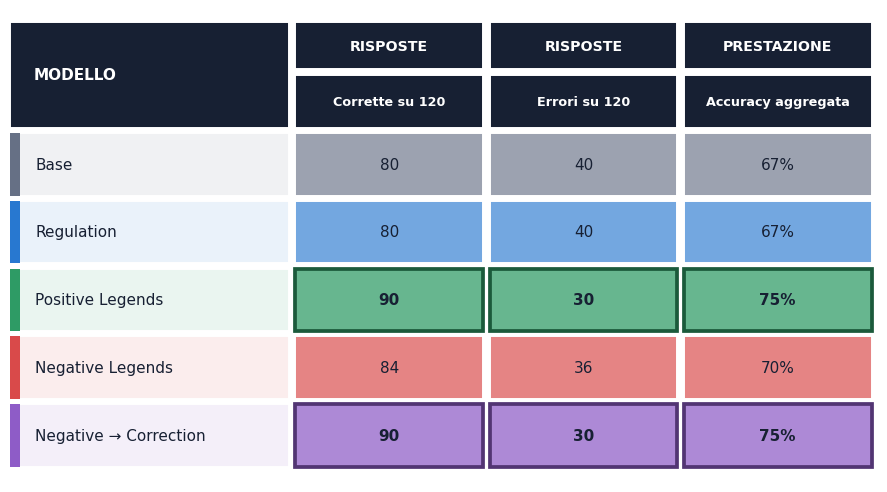

In [593]:
# CELLA 9 — Genera la matrice aggregata della classificazione
# utilizzando lo stesso template grafico della matrice principale
# approvata nel Blocco 1.
#
# Caratteristiche:
# - colonna modello chiara con banda verticale colorata;
# - intestazione su due livelli;
# - celle separate da spazi bianchi;
# - intensità cromatica basata su limiti assoluti;
# - bordo scuro e testo bold soltanto sui risultati migliori;
# - nessun titolo incorporato nel PNG.

from matplotlib import colors as mcolors
from matplotlib.patches import Rectangle


def classification_blend_colors(
    background_color: str,
    foreground_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """
    Miscela il colore del modello con il bianco.

    amount:
    - 0 produce il bianco;
    - 1 produce il colore pieno del modello.
    """

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    background_rgb = np.asarray(
        mcolors.to_rgb(
            background_color
        )
    )

    foreground_rgb = np.asarray(
        mcolors.to_rgb(
            foreground_color
        )
    )

    return tuple(
        background_rgb
        * (
            1.0
            - amount
        )
        + foreground_rgb
        * amount
    )


def classification_get_contrast_text_color(
    background_color,
) -> str:
    """
    Restituisce blu scuro oppure bianco
    in funzione della luminosità della cella.
    """

    red, green, blue = mcolors.to_rgb(
        background_color
    )

    relative_luminance = (
        0.2126
        * red
        + 0.7152
        * green
        + 0.0722
        * blue
    )

    if relative_luminance >= 0.58:
        return "#172033"

    return "white"


def normalize_classification_value_for_color(
    value: float,
    direction: str,
    lower_limit: float,
    upper_limit: float,
) -> float:
    """
    Converte il valore nell'intensità cromatica 0–1
    utilizzando una scala assoluta.

    higher:
        valore basso  -> cella chiara
        valore alto   -> cella intensa

    lower:
        valore basso  -> cella intensa
        valore alto   -> cella chiara
    """

    if pd.isna(
        value
    ):
        return np.nan

    if upper_limit <= lower_limit:
        raise ValueError(
            "upper_limit deve essere maggiore di lower_limit."
        )

    normalized_value = (
        float(
            value
        )
        - lower_limit
    ) / (
        upper_limit
        - lower_limit
    )

    normalized_value = float(
        np.clip(
            normalized_value,
            0.0,
            1.0,
        )
    )

    if direction == "lower":
        normalized_value = (
            1.0
            - normalized_value
        )

    elif direction != "higher":
        raise ValueError(
            f"Direzione non supportata: {direction}"
        )

    return normalized_value


def plot_classification_aggregate_matrix(
    dataframe: pd.DataFrame,
    output_path: Path,
):
    """
    Crea la matrice aggregata della classificazione
    replicando la geometria della baseline del Blocco 1.
    """

    metric_columns = [
        "total_correct",
        "total_errors",
        "overall_accuracy",
    ]


    matrix_dataframe = (
        dataframe
        .set_index(
            "model_name"
        )
        .reindex(
            index=MODEL_ORDER
        )[
            metric_columns
        ]
        .copy()
    )


    column_top_names = {
        "total_correct": "RISPOSTE",
        "total_errors": "RISPOSTE",
        "overall_accuracy": "PRESTAZIONE",
    }


    column_bottom_names = {
        "total_correct": "Corrette su 120",
        "total_errors": "Errori su 120",
        "overall_accuracy": "Accuracy aggregata",
    }


    metric_directions = {
        "total_correct": "higher",
        "total_errors": "lower",
        "overall_accuracy": "higher",
    }


    absolute_color_limits = {
        "total_correct": (
            0.0,
            120.0,
        ),

        "total_errors": (
            0.0,
            120.0,
        ),

        "overall_accuracy": (
            0.0,
            1.0,
        ),
    }


    metric_formatters = {
        "total_correct": (
            lambda value:
            str(
                int(
                    round(
                        value
                    )
                )
            )
        ),

        "total_errors": (
            lambda value:
            str(
                int(
                    round(
                        value
                    )
                )
            )
        ),

        "overall_accuracy": (
            lambda value:
            f"{value * 100:.0f}%"
        ),
    }


    raw_values = (
        matrix_dataframe
        .to_numpy(
            dtype=float
        )
    )

    number_of_models = len(
        matrix_dataframe.index
    )

    number_of_metrics = len(
        matrix_dataframe.columns
    )


    normalized_values = np.full_like(
        raw_values,
        np.nan,
        dtype=float,
    )


    for column_index, column_name in enumerate(
        matrix_dataframe.columns
    ):
        lower_limit, upper_limit = (
            absolute_color_limits[
                column_name
            ]
        )

        direction = (
            metric_directions[
                column_name
            ]
        )

        for row_index in range(
            number_of_models
        ):
            normalized_values[
                row_index,
                column_index,
            ] = (
                normalize_classification_value_for_color(
                    value=raw_values[
                        row_index,
                        column_index,
                    ],

                    direction=direction,

                    lower_limit=lower_limit,

                    upper_limit=upper_limit,
                )
            )


    # =================================================================
    # DIMENSIONI, RIPRESE DAL TEMPLATE ORIGINALE
    # =================================================================

    model_column_width = 3.60
    metric_column_width = 2.45

    horizontal_gap = 0.08
    vertical_gap = 0.07

    row_height = 0.88

    top_header_height = 0.68
    bottom_header_height = 0.76

    complete_header_height = (
        top_header_height
        + bottom_header_height
    )

    bottom_margin = 0.20
    top_margin = 0.10


    total_width = (
        model_column_width
        + number_of_metrics
        * metric_column_width
    )


    total_height = (
        bottom_margin
        + number_of_models
        * row_height
        + complete_header_height
        + top_margin
    )


    figure, axis = plt.subplots(
        figsize=(
            max(
                11.2,
                total_width,
            ),
            max(
                6.0,
                total_height,
            ),
        )
    )


    figure.patch.set_facecolor(
        "white"
    )

    axis.set_facecolor(
        "white"
    )

    axis.set_xlim(
        0,
        total_width,
    )

    axis.set_ylim(
        0,
        total_height,
    )

    axis.axis(
        "off"
    )


    rows_bottom = (
        bottom_margin
    )

    header_bottom = (
        rows_bottom
        + number_of_models
        * row_height
    )

    bottom_header_bottom = (
        header_bottom
    )

    top_header_bottom = (
        bottom_header_bottom
        + bottom_header_height
    )


    header_color = "#172033"


    # =================================================================
    # INTESTAZIONE DELLA COLONNA MODELLO
    # =================================================================

    axis.add_patch(
        Rectangle(
            xy=(
                0,
                header_bottom,
            ),

            width=(
                model_column_width
                - horizontal_gap
            ),

            height=(
                complete_header_height
                - vertical_gap
            ),

            facecolor=header_color,

            edgecolor="white",

            linewidth=1.4,
        )
    )


    axis.text(
        0.30,

        header_bottom
        + (
            complete_header_height
            - vertical_gap
        )
        / 2,

        "MODELLO",

        ha="left",

        va="center",

        fontsize=11,

        fontweight="bold",

        color="white",
    )


    # =================================================================
    # INTESTAZIONI DELLE METRICHE
    # =================================================================

    for column_index, column_name in enumerate(
        matrix_dataframe.columns
    ):
        cell_x = (
            model_column_width
            + column_index
            * metric_column_width
        )

        cell_width = (
            metric_column_width
            - horizontal_gap
        )


        axis.add_patch(
            Rectangle(
                xy=(
                    cell_x,
                    top_header_bottom,
                ),

                width=cell_width,

                height=(
                    top_header_height
                    - vertical_gap
                ),

                facecolor=header_color,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,

            top_header_bottom
            + (
                top_header_height
                - vertical_gap
            )
            / 2,

            column_top_names[
                column_name
            ],

            ha="center",

            va="center",

            fontsize=10.2,

            fontweight="bold",

            color="white",
        )


        axis.add_patch(
            Rectangle(
                xy=(
                    cell_x,
                    bottom_header_bottom,
                ),

                width=cell_width,

                height=(
                    bottom_header_height
                    - vertical_gap
                ),

                facecolor=header_color,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,

            bottom_header_bottom
            + (
                bottom_header_height
                - vertical_gap
            )
            / 2,

            column_bottom_names[
                column_name
            ],

            ha="center",

            va="center",

            fontsize=9.2,

            fontweight="bold",

            color="white",
        )


    # =================================================================
    # RIGHE DEI MODELLI
    # =================================================================

    for row_index, model_name in enumerate(
        matrix_dataframe.index
    ):
        row_bottom = (
            rows_bottom
            + (
                number_of_models
                - 1
                - row_index
            )
            * row_height
        )

        model_color = (
            MODEL_COLORS[
                model_name
            ]
        )


        model_name_background = (
            classification_blend_colors(
                background_color="#FFFFFF",

                foreground_color=model_color,

                amount=0.10,
            )
        )


        # -------------------------------------------------------------
        # CELLA CON IL NOME DEL MODELLO
        # -------------------------------------------------------------

        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=(
                    model_column_width
                    - horizontal_gap
                ),

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_name_background,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=0.12,

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_color,

                edgecolor="none",
            )
        )


        axis.text(
            0.32,

            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,

            MODEL_DISPLAY_NAMES[
                model_name
            ],

            ha="left",

            va="center",

            fontsize=11,

            fontweight="medium",

            color="#172033",
        )


        # -------------------------------------------------------------
        # CELLE NUMERICHE
        # -------------------------------------------------------------

        for column_index, column_name in enumerate(
            matrix_dataframe.columns
        ):
            cell_x = (
                model_column_width
                + column_index
                * metric_column_width
            )

            cell_width = (
                metric_column_width
                - horizontal_gap
            )

            raw_value = raw_values[
                row_index,
                column_index,
            ]

            normalized_value = (
                normalized_values[
                    row_index,
                    column_index,
                ]
            )

            direction = (
                metric_directions[
                    column_name
                ]
            )


            best_models = get_best_models(
                series=(
                    matrix_dataframe[
                        column_name
                    ]
                ),

                direction=direction,
            )


            is_best_model = (
                model_name
                in best_models
            )


            if np.isnan(
                normalized_value
            ):
                cell_facecolor = (
                    "#EAECEF"
                )

            else:
                color_strength = (
                    0.05
                    + 0.90
                    * normalized_value
                )

                cell_facecolor = (
                    classification_blend_colors(
                        background_color="#FFFFFF",

                        foreground_color=model_color,

                        amount=color_strength,
                    )
                )


            if is_best_model:
                cell_edgecolor = (
                    darken_color(
                        color=model_color,

                        amount=0.42,
                    )
                )

                cell_linewidth = (
                    2.7
                )

            else:
                cell_edgecolor = (
                    "white"
                )

                cell_linewidth = (
                    1.4
                )


            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        row_bottom,
                    ),

                    width=cell_width,

                    height=(
                        row_height
                        - vertical_gap
                    ),

                    facecolor=cell_facecolor,

                    edgecolor=cell_edgecolor,

                    linewidth=cell_linewidth,
                )
            )


            if pd.isna(
                raw_value
            ):
                value_text = "—"

            else:
                value_text = (
                    metric_formatters[
                        column_name
                    ](
                        raw_value
                    )
                )


            axis.text(
                cell_x
                + cell_width
                / 2,

                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                / 2,

                value_text,

                ha="center",

                va="center",

                fontsize=11,

                fontweight=(
                    "bold"
                    if is_best_model
                    else "normal"
                ),

                color=(
                    classification_get_contrast_text_color(
                        cell_facecolor
                    )
                ),
            )


    save_figure(
        figure=figure,

        output_path=output_path,
    )


plot_classification_aggregate_matrix(
    dataframe=(
        classification_summary_df
    ),

    output_path=(
        CLASSIFICATION_PLOTS_DIR
        / "01_classification_summary_matrix.png"
    ),
)

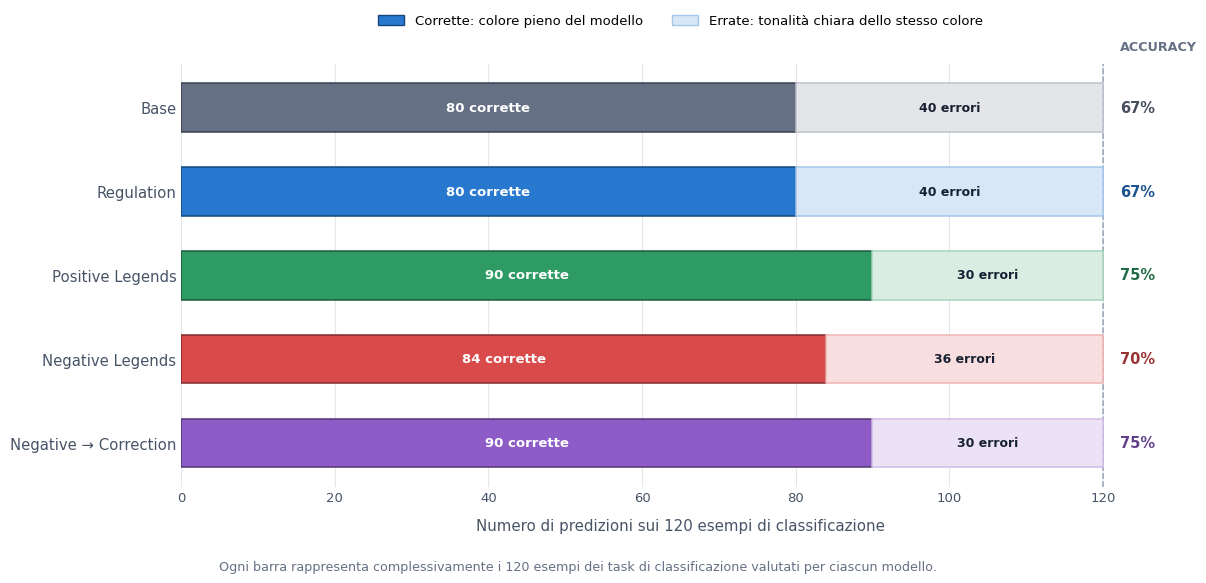

In [623]:
# CELLA 10 — Visualizzazione aggregata della classificazione.
#
# Per ciascun modello mostra:
# - risposte corrette sui 120 esempi;
# - risposte errate;
# - accuracy aggregata.
#
# Codifica grafica:
# - colore pieno del modello = risposte corrette;
# - tonalità chiara dello stesso colore = risposte errate.
#
# Non utilizza punti, rank o posizioni.
# Il grafico viene salvato come singolo PNG analitico.

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Patch


# =====================================================================
# PREPARAZIONE DEI DATI
# =====================================================================

classification_chart_df = (
    classification_summary_df
    .set_index(
        "model_name"
    )
    .reindex(
        MODEL_ORDER
    )
    .reset_index()
)


required_chart_columns = {
    "model_name",
    "total_correct",
    "total_errors",
    "overall_accuracy",
}


missing_chart_columns = (
    required_chart_columns
    - set(
        classification_chart_df.columns
    )
)


if missing_chart_columns:
    raise RuntimeError(
        "Nella sintesi della classificazione mancano le colonne: "
        f"{sorted(missing_chart_columns)}"
    )


if classification_chart_df[
    [
        "total_correct",
        "total_errors",
        "overall_accuracy",
    ]
].isna().any().any():
    raise RuntimeError(
        "La sintesi aggregata della classificazione "
        "contiene valori mancanti."
    )


# =====================================================================
# CONFIGURAZIONE DELLA FIGURA
# =====================================================================

figure, axis = plt.subplots(
    figsize=(
        12.8,
        6.4,
    )
)


figure.patch.set_facecolor(
    "white"
)


axis.set_facecolor(
    "white"
)


y_positions = np.arange(
    len(
        classification_chart_df
    )
)


bar_height = 0.58


# =====================================================================
# BARRE CORRETTE / ERRORI
# =====================================================================

for row_index, row in classification_chart_df.iterrows():

    model_name = row[
        "model_name"
    ]


    model_color = MODEL_COLORS[
        model_name
    ]


    total_correct = int(
        row[
            "total_correct"
        ]
    )


    total_errors = int(
        row[
            "total_errors"
        ]
    )


    overall_accuracy = float(
        row[
            "overall_accuracy"
        ]
    )


    if (
        total_correct
        + total_errors
        != 120
    ):
        raise RuntimeError(
            f"Per il modello {model_name}, corrette ed errori "
            "non sommano a 120."
        )


    # Colore pieno del modello per le risposte corrette.
    correct_color = model_color


    # Tonalità chiara dello stesso modello per gli errori.
    error_color = classification_blend_colors(
        background_color="#FFFFFF",
        foreground_color=model_color,
        amount=0.18,
    )


    # Bordo leggermente più scuro del colore del modello.
    model_edge_color = darken_color(
        model_color,
        0.42,
    )


    # ---------------------------------------------------------------
    # Risposte corrette
    # ---------------------------------------------------------------

    axis.barh(
        y=row_index,
        width=total_correct,
        left=0,
        height=bar_height,
        color=correct_color,
        edgecolor=model_edge_color,
        linewidth=1.1,
        zorder=3,
    )


    # ---------------------------------------------------------------
    # Risposte errate
    # ---------------------------------------------------------------

    axis.barh(
        y=row_index,
        width=total_errors,
        left=total_correct,
        height=bar_height,
        color=error_color,
        edgecolor=classification_blend_colors(
            background_color="#FFFFFF",
            foreground_color=model_color,
            amount=0.42,
        ),
        linewidth=1.1,
        zorder=3,
    )


    # ---------------------------------------------------------------
    # Etichetta delle risposte corrette
    # ---------------------------------------------------------------

    if total_correct > 0:
        axis.text(
            total_correct / 2,
            row_index,
            f"{total_correct} corrette",
            ha="center",
            va="center",
            fontsize=9.5,
            fontweight="bold",
            color="white",
            zorder=5,
        )


    # ---------------------------------------------------------------
    # Etichetta degli errori
    # ---------------------------------------------------------------

    if total_errors > 0:
        axis.text(
            total_correct
            + total_errors / 2,
            row_index,
            f"{total_errors} errori",
            ha="center",
            va="center",
            fontsize=9.0,
            fontweight="bold",
            color="#172033",
            zorder=5,
        )


    # ---------------------------------------------------------------
    # Accuracy aggregata
    # ---------------------------------------------------------------

    axis.text(
        122.2,
        row_index,
        f"{overall_accuracy * 100:.0f}%",
        ha="left",
        va="center",
        fontsize=10.5,
        fontweight="bold",
        color=darken_color(
            model_color,
            0.30,
        ),
        zorder=5,
    )


# =====================================================================
# ASSI E LABEL
# =====================================================================

axis.set_yticks(
    y_positions
)


axis.set_yticklabels(
    [
        MODEL_DISPLAY_NAMES[
            model_name
        ]
        for model_name
        in classification_chart_df[
            "model_name"
        ]
    ],
    fontsize=10.7,
    fontweight="medium",
    color="#172033",
)


axis.invert_yaxis()


axis.set_xlim(
    0,
    130,
)


axis.set_xticks(
    [
        0,
        20,
        40,
        60,
        80,
        100,
        120,
    ]
)


axis.set_xlabel(
    "Numero di predizioni sui 120 esempi di classificazione",
    fontsize=10.8,
    fontweight="medium",
    color="#475467",
    labelpad=10,
)


# Separatore tra la barra e la colonna dell'accuracy.
axis.axvline(
    120,
    color="#98A2B3",
    linewidth=1.1,
    linestyle="--",
    zorder=1,
)


# Intestazione della colonna percentuale.
axis.text(
    122.2,
    1.025,
    "ACCURACY",
    transform=axis.get_xaxis_transform(),
    ha="left",
    va="bottom",
    fontsize=9.2,
    fontweight="bold",
    color="#667085",
    clip_on=False,
)


axis.grid(
    axis="x",
    color="#D9DEE5",
    linewidth=0.8,
    alpha=0.72,
)


axis.set_axisbelow(
    True
)


axis.tick_params(
    axis="both",
    length=0,
    colors="#475467",
)


for spine in axis.spines.values():
    spine.set_visible(
        False
    )


# =====================================================================
# LEGENDA
# =====================================================================

# La legenda rappresenta la differenza tra colore pieno
# e tonalità chiara. Il blu è usato soltanto come esempio visivo:
# nel grafico il colore effettivo dipende dal modello.

legend_example_color = "#2878D0"


legend_handles = [
    Patch(
        facecolor=legend_example_color,
        edgecolor=darken_color(
            legend_example_color,
            0.42,
        ),
        linewidth=1.0,
        label="Corrette: colore pieno del modello",
    ),

    Patch(
        facecolor=classification_blend_colors(
            background_color="#FFFFFF",
            foreground_color=legend_example_color,
            amount=0.18,
        ),
        edgecolor=classification_blend_colors(
            background_color="#FFFFFF",
            foreground_color=legend_example_color,
            amount=0.42,
        ),
        linewidth=1.0,
        label="Errate: tonalità chiara dello stesso colore",
    ),
]


axis.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        1.145,
    ),
    frameon=False,
    fontsize=9.5,
    ncol=2,
    columnspacing=2.2,
    handlelength=2.0,
)


# =====================================================================
# NOTA METODOLOGICA
# =====================================================================

figure.text(
    0.5,
    0.035,
    (
        "Ogni barra rappresenta complessivamente i 120 esempi "
        "dei task di classificazione valutati per ciascun modello."
    ),
    ha="center",
    va="center",
    fontsize=9.2,
    color="#667085",
)


figure.subplots_adjust(
    left=0.19,
    right=0.97,
    top=0.82,
    bottom=0.16,
)


# =====================================================================
# SALVATAGGIO
# =====================================================================

save_figure(
    figure=figure,
    output_path=(
        CLASSIFICATION_PLOTS_DIR
        / "02_classification_correct_vs_errors.png"
    ),
)

In [595]:
# CELLA 11 — Controllo conclusivo della sezione Classificazione.
#
# Non calcola rank, punti, posizioni o stabilità del ranking.
# Verifica soltanto che la tabella aggregata contenga:
# - cinque modelli;
# - 120 esempi per modello;
# - corrette + errori = 120;
# - accuracy coerente con il numero di risposte corrette.

required_classification_columns = {
    "model_name",
    "total_examples",
    "total_correct",
    "total_errors",
    "overall_accuracy",
}


missing_classification_columns = (
    required_classification_columns
    - set(
        classification_summary_df.columns
    )
)


if missing_classification_columns:
    raise RuntimeError(
        "Nella sintesi classificatoria mancano le colonne: "
        f"{sorted(missing_classification_columns)}"
    )


classification_check_df = (
    classification_summary_df
    .set_index(
        "model_name"
    )
    .reindex(
        MODEL_ORDER
    )
    .reset_index()
)


if len(
    classification_check_df
) != len(
    MODEL_ORDER
):
    raise RuntimeError(
        "La sintesi classificatoria non contiene "
        "esattamente i cinque modelli previsti."
    )


if classification_check_df[
    "model_name"
].isna().any():
    raise RuntimeError(
        "Uno o più modelli previsti non sono presenti "
        "nella sintesi classificatoria."
    )


if not (
    classification_check_df[
        "total_examples"
    ]
    == 120
).all():
    raise RuntimeError(
        "Ogni modello deve avere esattamente "
        "120 predizioni classificatorie."
    )


if not (
    classification_check_df[
        "total_correct"
    ]
    + classification_check_df[
        "total_errors"
    ]
    == classification_check_df[
        "total_examples"
    ]
).all():
    raise RuntimeError(
        "Per almeno un modello, corrette + errori "
        "non coincide con il totale degli esempi."
    )


expected_accuracy = (
    classification_check_df[
        "total_correct"
    ]
    / classification_check_df[
        "total_examples"
    ]
)


if not np.isclose(
    classification_check_df[
        "overall_accuracy"
    ].to_numpy(
        dtype=float
    ),
    expected_accuracy.to_numpy(
        dtype=float
    ),
    atol=1e-12,
    rtol=0.0,
).all():
    raise RuntimeError(
        "L'accuracy aggregata non coincide con "
        "total_correct / total_examples."
    )


display(
    classification_check_df[
        [
            "model_name",
            "total_correct",
            "total_errors",
            "overall_accuracy",
        ]
    ]
    .assign(
        overall_accuracy=lambda dataframe: (
            dataframe[
                "overall_accuracy"
            ]
            * 100
        ).round(
            1
        )
    )
    .rename(
        columns={
            "model_name": "Modello",
            "total_correct": "Corrette",
            "total_errors": "Errori",
            "overall_accuracy": "Accuracy (%)",
        }
    )
)


print(
    "Sezione Classificazione verificata correttamente: "
    "nessun ranking utilizzato."
)

,Modello,Corrette,Errori,Accuracy (%)
0,base,80,40,66.7
1,regulation,80,40,66.7
2,positive_legends,90,30,75.0
3,negative_legends,84,36,70.0
4,negative_to_correction,90,30,75.0


Sezione Classificazione verificata correttamente: nessun ranking utilizzato.


## Tentativi alternativi — Classificazione

Le celle seguenti non sostituiscono le tre visualizzazioni principali.

Servono a verificare prospettive aggiuntive:

- posizione ottenuta su ciascun task;
- dominanza tutti-contro-tutti;
- distribuzione dei primary score normalizzati internamente al singolo task.

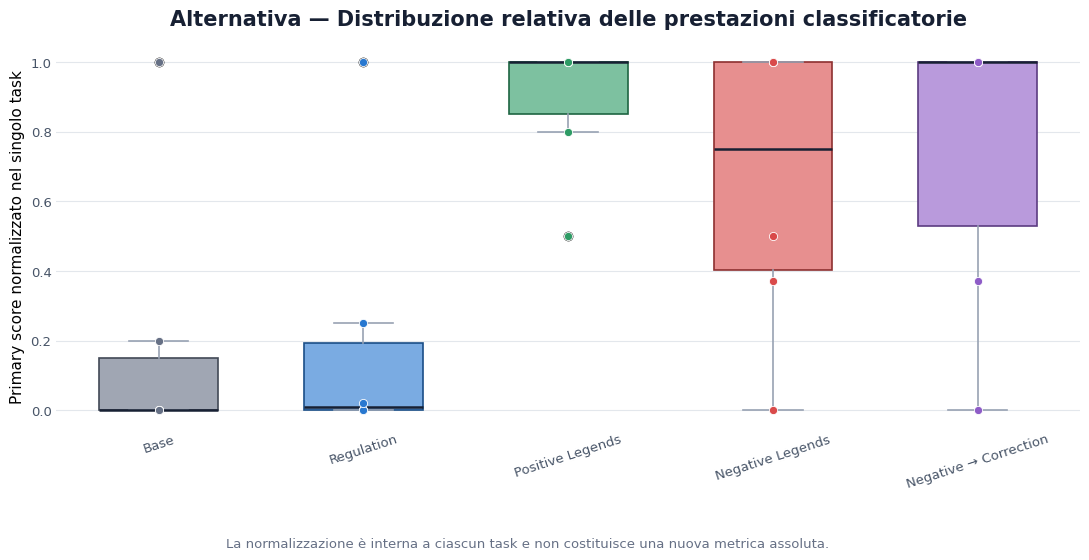

In [596]:
# CELLA 15 — ALTERNATIVA CLASSIFICAZIONE 3.
# Normalizza i primary score all'interno di ciascun task
# e confronta la distribuzione relativa dei sei risultati.

classification_scores_wide_df = (
    automatic_primary_scores_df[
        automatic_primary_scores_df[
            "task_name"
        ].isin(
            CLASSIFICATION_TASKS
        )
    ]
    .pivot(
        index="task_name",
        columns="model_name",
        values="primary_score",
    )
    .reindex(
        index=CLASSIFICATION_TASKS,
        columns=MODEL_ORDER,
    )
)


classification_normalized_df = (
    classification_scores_wide_df
    .copy()
)


for task_name in CLASSIFICATION_TASKS:
    task_values = (
        classification_scores_wide_df.loc[
            task_name
        ]
        .astype(
            float
        )
    )

    task_minimum = float(
        task_values.min()
    )

    task_maximum = float(
        task_values.max()
    )

    if np.isclose(
        task_minimum,
        task_maximum,
    ):
        classification_normalized_df.loc[
            task_name
        ] = 1.0

    else:
        classification_normalized_df.loc[
            task_name
        ] = (
            task_values
            - task_minimum
        ) / (
            task_maximum
            - task_minimum
        )


boxplot_values = [
    classification_normalized_df[
        model_name
    ].to_numpy(
        dtype=float
    )
    for model_name in MODEL_ORDER
]


figure, axis = plt.subplots(
    figsize=(
        11.5,
        5.8,
    )
)

figure.patch.set_facecolor(
    "white"
)


boxplot_result = axis.boxplot(
    boxplot_values,
    tick_labels=[
        MODEL_DISPLAY_NAMES[
            model_name
        ]
        for model_name
        in MODEL_ORDER
    ],
    patch_artist=True,
    widths=0.58,
    medianprops={
        "color": "#172033",
        "linewidth": 1.8,
    },
    whiskerprops={
        "color": "#98A2B3",
        "linewidth": 1.2,
    },
    capprops={
        "color": "#98A2B3",
        "linewidth": 1.2,
    },
)


for box, model_name in zip(
    boxplot_result[
        "boxes"
    ],
    MODEL_ORDER,
):
    box.set_facecolor(
        mix_color(
            "#FFFFFF",
            MODEL_COLORS[
                model_name
            ],
            0.62,
        )
    )

    box.set_edgecolor(
        darken_color(
            MODEL_COLORS[
                model_name
            ],
            0.35,
        )
    )

    box.set_linewidth(
        1.2
    )


for (
    x_position,
    model_name,
) in enumerate(
    MODEL_ORDER,
    start=1,
):
    values = (
        classification_normalized_df[
            model_name
        ]
        .to_numpy(
            dtype=float
        )
    )

    axis.scatter(
        np.full_like(
            values,
            x_position,
            dtype=float,
        ),
        values,
        s=35,
        color=MODEL_COLORS[
            model_name
        ],
        edgecolor="white",
        linewidth=0.6,
        zorder=4,
    )


axis.set_ylim(
    -0.05,
    1.05,
)

axis.set_ylabel(
    "Primary score normalizzato nel singolo task"
)

axis.set_title(
    "Alternativa — Distribuzione relativa "
    "delle prestazioni classificatorie",
    color=TEXT_COLOR,
    pad=14,
)

axis.tick_params(
    axis="x",
    rotation=18,
)

style_axis(
    axis,
    grid_axis="y",
)


figure.text(
    0.5,
    0.02,
    "La normalizzazione è interna a ciascun task "
    "e non costituisce una nuova metrica assoluta.",
    ha="center",
    va="center",
    fontsize=9.5,
    color=MUTED_TEXT_COLOR,
)


figure.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.88,
    bottom=0.22,
)


save_figure(
    figure,
    CLASSIFICATION_ALT_DIR
    / "ALT_CLASS_03_normalized_score_distribution.png",
)

# Sezione 2 — Similarità numerica

STS-B è un singolo task numerico e non viene trattato come una categoria multi-task artificiale.

La capacità viene osservata attraverso prospettive complementari:

- correlazione lineare e ordinamento relativo;
- distanza media dalla reference;
- gravità degli errori;
- tendenza a sottostimare o sovrastimare;
- distribuzione congiunta tra valore reale e valore predetto.

In [597]:
# CELLA 17 — Calcola il profilo completo di STS-B
# per ciascun modello a partire dalle 100 predizioni.

def safe_pearson(
    true_values: pd.Series,
    predicted_values: pd.Series,
) -> float:
    """
    Calcola Pearson gestendo il caso
    di predizioni costanti.
    """

    if np.isclose(
        predicted_values.std(
            ddof=0
        ),
        0.0,
    ):
        return 0.0

    return float(
        pearsonr(
            true_values,
            predicted_values,
        ).statistic
    )


def safe_spearman(
    true_values: pd.Series,
    predicted_values: pd.Series,
) -> float:
    """
    Calcola Spearman gestendo il caso
    di predizioni costanti.
    """

    if np.isclose(
        predicted_values.std(
            ddof=0
        ),
        0.0,
    ):
        return 0.0

    return float(
        spearmanr(
            true_values,
            predicted_values,
        ).statistic
    )


stsb_summary_rows = []


for model_name in MODEL_ORDER:
    model_data = (
        stsb_results_df[
            stsb_results_df[
                "model_name"
            ]
            == model_name
        ]
        .copy()
    )

    true_values = (
        model_data[
            "y_true"
        ]
        .astype(
            float
        )
    )

    predicted_values = (
        model_data[
            "y_pred"
        ]
        .astype(
            float
        )
    )

    absolute_errors = (
        model_data[
            "absolute_error"
        ]
        .astype(
            float
        )
    )

    signed_errors = (
        model_data[
            "signed_error"
        ]
        .astype(
            float
        )
    )

    pearson_value = safe_pearson(
        true_values,
        predicted_values,
    )

    spearman_value = safe_spearman(
        true_values,
        predicted_values,
    )

    stsb_summary_rows.append({
        "model_name": model_name,

        "n_examples": len(
            model_data
        ),

        "pearson": (
            pearson_value
        ),

        "spearman": (
            spearman_value
        ),

        "primary_score": (
            pearson_value
            + spearman_value
        ) / 2,

        "mae": float(
            absolute_errors.mean()
        ),

        "rmse": float(
            np.sqrt(
                np.mean(
                    np.square(
                        signed_errors
                    )
                )
            )
        ),

        "mean_signed_error": float(
            signed_errors.mean()
        ),

        "exact_rate": float(
            np.isclose(
                absolute_errors,
                0.0,
            ).mean()
        ),

        "within_1_rate": float(
            (
                absolute_errors
                <= 1
            ).mean()
        ),

        "within_2_rate": float(
            (
                absolute_errors
                <= 2
            ).mean()
        ),

        "exact_count": int(
            np.isclose(
                absolute_errors,
                0.0,
            ).sum()
        ),

        "off_by_1_count": int(
            np.isclose(
                absolute_errors,
                1.0,
            ).sum()
        ),

        "off_by_2_count": int(
            np.isclose(
                absolute_errors,
                2.0,
            ).sum()
        ),

        "off_by_3_or_more_count": int(
            (
                absolute_errors
                >= 3.0
            ).sum()
        ),

        "underestimation_count": int(
            (
                signed_errors
                < 0
            ).sum()
        ),

        "exact_prediction_count": int(
            np.isclose(
                signed_errors,
                0.0,
            ).sum()
        ),

        "overestimation_count": int(
            (
                signed_errors
                > 0
            ).sum()
        ),
    })


stsb_summary_df = sort_models(
    pd.DataFrame(
        stsb_summary_rows
    )
)


reported_stsb_primary_df = (
    primary_task_scores_df[
        primary_task_scores_df[
            "task_name"
        ]
        == STSB_TASK
    ][
        [
            "model_name",
            "primary_score",
        ]
    ]
    .rename(
        columns={
            "primary_score": (
                "reported_primary_score"
            )
        }
    )
)


stsb_summary_df = (
    stsb_summary_df
    .merge(
        reported_stsb_primary_df,
        on="model_name",
        how="left",
        validate="one_to_one",
    )
)


stsb_summary_df[
    "primary_score_difference"
] = (
    stsb_summary_df[
        "primary_score"
    ]
    - stsb_summary_df[
        "reported_primary_score"
    ]
)


if (
    stsb_summary_df[
        "reported_primary_score"
    ].notna().all()
    and not np.isclose(
        stsb_summary_df[
            "primary_score"
        ],
        stsb_summary_df[
            "reported_primary_score"
        ],
        atol=1e-8,
        rtol=0.0,
    ).all()
):
    warnings.warn(
        "La primary metric STS-B ricalcolata non coincide "
        "perfettamente con primary_task_scores.csv. "
        "I valori vengono mantenuti entrambi."
    )


display(
    stsb_summary_df
    .round(
        4
    )
)

,model_name,n_examples,pearson,spearman,primary_score,mae,rmse,mean_signed_error,exact_rate,within_1_rate,within_2_rate,exact_count,off_by_1_count,off_by_2_count,off_by_3_or_more_count,underestimation_count,exact_prediction_count,overestimation_count,reported_primary_score,primary_score_difference
0,base,20,0.8177,0.8409,0.8293,1.05,1.3229,-0.85,0.25,0.75,0.95,5,10,4,1,14,5,1,0.8293,0.0
1,regulation,20,0.8577,0.8748,0.8663,1.00,1.2649,-0.90,0.25,0.80,0.95,5,11,3,1,14,5,1,0.8663,0.0
2,positive_legends,20,0.8329,0.8535,0.8432,1.10,1.3784,-1.00,0.25,0.70,0.95,5,9,5,1,14,5,1,0.8432,0.0
3,negative_legends,20,0.8595,0.8767,0.8681,0.95,1.2450,-0.85,0.30,0.80,0.95,6,10,3,1,13,6,1,0.8681,0.0
4,negative_to_correction,20,0.8470,0.8694,0.8582,1.10,1.3416,-1.00,0.20,0.75,0.95,4,11,4,1,15,4,1,0.8582,-0.0


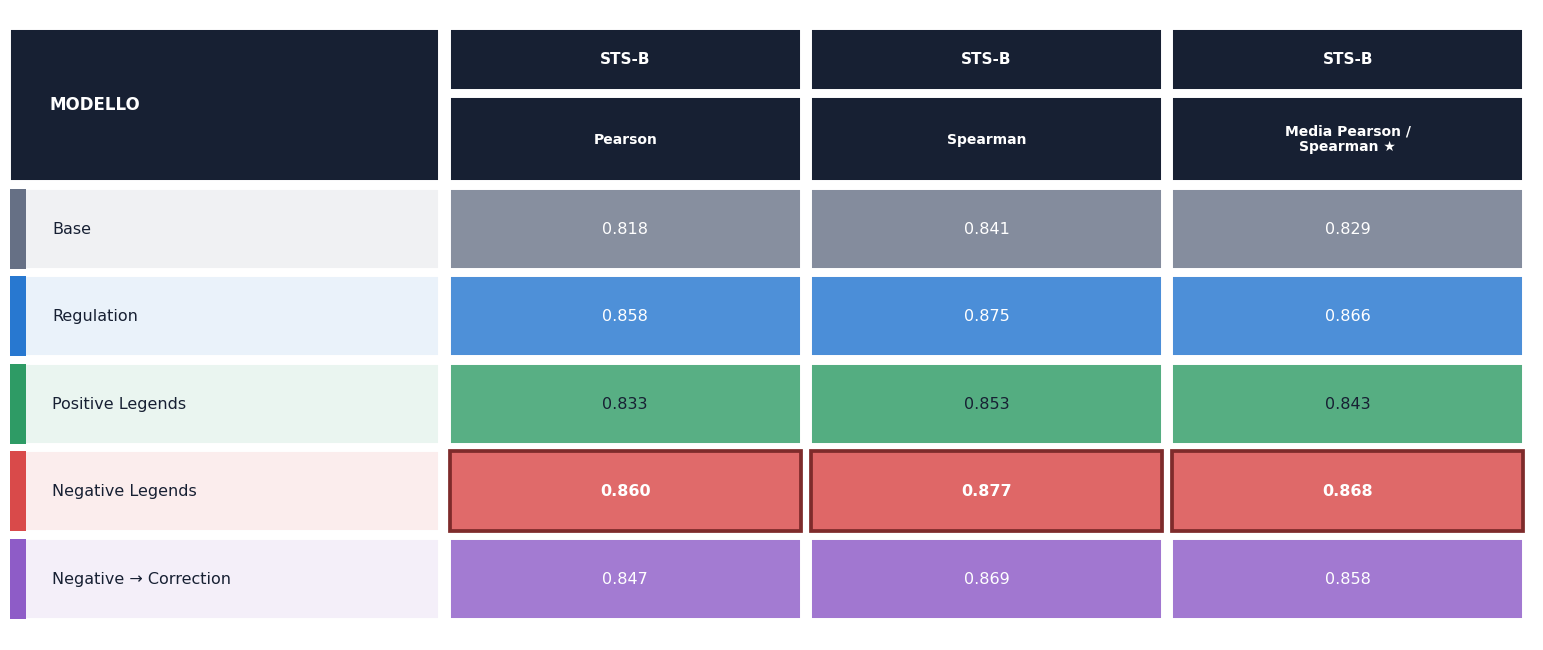

In [598]:
# CELLA 18 — Matrice standard e simmetrica delle correlazioni STS-B.
#
# Caratteristiche:
# - tutte le colonne metriche hanno la stessa larghezza;
# - matrice complessivamente più larga;
# - "Media Pearson / Spearman" va su due righe;
# - colonna modello chiara con banda verticale colorata;
# - intensità cromatica sulla scala assoluta 0–1;
# - bordo scuro e testo bold soltanto sui valori migliori;
# - nessun titolo incorporato nel PNG.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import colors as mcolors
from matplotlib.patches import Rectangle


# =====================================================================
# FUNZIONI LOCALI
# =====================================================================

def stsb_blend_colors(
    background_color: str,
    foreground_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """
    Miscela il colore del modello con il colore di sfondo.

    amount:
    - 0 restituisce il colore di sfondo;
    - 1 restituisce il colore pieno del modello.
    """

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    background_rgb = np.asarray(
        mcolors.to_rgb(
            background_color
        )
    )

    foreground_rgb = np.asarray(
        mcolors.to_rgb(
            foreground_color
        )
    )

    return tuple(
        background_rgb
        * (
            1.0
            - amount
        )
        + foreground_rgb
        * amount
    )


def stsb_get_contrast_text_color(
    background_color,
) -> str:
    """
    Restituisce bianco oppure blu scuro
    in base alla luminosità della cella.
    """

    red, green, blue = mcolors.to_rgb(
        background_color
    )

    relative_luminance = (
        0.2126
        * red
        + 0.7152
        * green
        + 0.0722
        * blue
    )

    if relative_luminance >= 0.58:
        return "#172033"

    return "white"


def normalize_stsb_value_for_color(
    value: float,
    lower_limit: float = 0.0,
    upper_limit: float = 1.0,
) -> float:
    """
    Normalizza il valore sulla scala assoluta 0–1.

    0.00 -> cella quasi bianca
    1.00 -> colore quasi pieno
    """

    if pd.isna(
        value
    ):
        return np.nan

    if upper_limit <= lower_limit:
        raise ValueError(
            "upper_limit deve essere maggiore di lower_limit."
        )

    normalized_value = (
        float(
            value
        )
        - lower_limit
    ) / (
        upper_limit
        - lower_limit
    )

    return float(
        np.clip(
            normalized_value,
            0.0,
            1.0,
        )
    )


# =====================================================================
# FUNZIONE PRINCIPALE
# =====================================================================

def plot_standard_stsb_correlation_matrix(
    dataframe: pd.DataFrame,
    output_path: Path,
):
    """
    Genera la matrice standard e simmetrica
    di Pearson, Spearman e primary score.
    """

    required_columns = {
        "model_name",
        "pearson",
        "spearman",
        "primary_score",
    }

    missing_columns = (
        required_columns
        - set(
            dataframe.columns
        )
    )

    if missing_columns:
        raise RuntimeError(
            "Nella tabella STS-B mancano le colonne: "
            f"{sorted(missing_columns)}"
        )


    metric_columns = [
        "pearson",
        "spearman",
        "primary_score",
    ]


    matrix_dataframe = (
        dataframe
        .set_index(
            "model_name"
        )
        .reindex(
            index=MODEL_ORDER
        )[
            metric_columns
        ]
        .copy()
    )


    if matrix_dataframe.isna().any().any():
        raise RuntimeError(
            "La matrice STS-B contiene valori mancanti."
        )


    # =================================================================
    # TESTI DELLE INTESTAZIONI
    # =================================================================

    column_top_names = {
        "pearson": "STS-B",
        "spearman": "STS-B",
        "primary_score": "STS-B",
    }


    column_bottom_names = {
        "pearson": "Pearson",

        "spearman": "Spearman",

        "primary_score": (
            "Media Pearson /\nSpearman ★"
        ),
    }


    metric_formatters = {
        "pearson": (
            lambda value:
            f"{value:.3f}"
        ),

        "spearman": (
            lambda value:
            f"{value:.3f}"
        ),

        "primary_score": (
            lambda value:
            f"{value:.3f}"
        ),
    }


    raw_values = (
        matrix_dataframe
        .to_numpy(
            dtype=float
        )
    )


    number_of_models = len(
        matrix_dataframe.index
    )

    number_of_metrics = len(
        matrix_dataframe.columns
    )


    normalized_values = np.full_like(
        raw_values,
        np.nan,
        dtype=float,
    )


    for column_index in range(
        number_of_metrics
    ):
        for row_index in range(
            number_of_models
        ):
            normalized_values[
                row_index,
                column_index,
            ] = normalize_stsb_value_for_color(
                value=raw_values[
                    row_index,
                    column_index,
                ],

                lower_limit=0.0,

                upper_limit=1.0,
            )


    # =================================================================
    # DIMENSIONI DEL TEMPLATE
    # =================================================================

    # Colonna modello leggermente più larga.
    model_column_width = 4.20

    # Tutte le colonne delle metriche sono IDENTICHE.
    metric_column_width = 3.45

    horizontal_gap = 0.10
    vertical_gap = 0.08

    row_height = 0.92

    task_header_height = 0.72

    # Altezza sufficiente per l'intestazione su due righe.
    metric_header_height = 0.96

    complete_header_height = (
        task_header_height
        + metric_header_height
    )

    bottom_margin = 0.22
    top_margin = 0.12


    total_width = (
        model_column_width
        + number_of_metrics
        * metric_column_width
    )


    total_height = (
        bottom_margin
        + number_of_models
        * row_height
        + complete_header_height
        + top_margin
    )


    figure, axis = plt.subplots(
        figsize=(
            15.5,
            6.5,
        )
    )


    figure.patch.set_facecolor(
        "white"
    )

    axis.set_facecolor(
        "white"
    )

    axis.set_xlim(
        0,
        total_width,
    )

    axis.set_ylim(
        0,
        total_height,
    )

    axis.axis(
        "off"
    )


    rows_bottom = (
        bottom_margin
    )


    header_bottom = (
        rows_bottom
        + number_of_models
        * row_height
    )


    metric_header_bottom = (
        header_bottom
    )


    task_header_bottom = (
        metric_header_bottom
        + metric_header_height
    )


    header_color = "#172033"


    # =================================================================
    # INTESTAZIONE DELLA COLONNA MODELLO
    # =================================================================

    axis.add_patch(
        Rectangle(
            xy=(
                0,
                header_bottom,
            ),

            width=(
                model_column_width
                - horizontal_gap
            ),

            height=(
                complete_header_height
                - vertical_gap
            ),

            facecolor=header_color,

            edgecolor="white",

            linewidth=1.4,
        )
    )


    axis.text(
        0.38,

        header_bottom
        + (
            complete_header_height
            - vertical_gap
        )
        / 2,

        "MODELLO",

        ha="left",

        va="center",

        fontsize=12,

        fontweight="bold",

        color="white",
    )


    # =================================================================
    # INTESTAZIONI DELLE METRICHE
    # =================================================================

    for column_index, column_name in enumerate(
        matrix_dataframe.columns
    ):
        cell_x = (
            model_column_width
            + column_index
            * metric_column_width
        )


        cell_width = (
            metric_column_width
            - horizontal_gap
        )


        # -------------------------------------------------------------
        # RIGA SUPERIORE: TASK
        # -------------------------------------------------------------

        axis.add_patch(
            Rectangle(
                xy=(
                    cell_x,
                    task_header_bottom,
                ),

                width=cell_width,

                height=(
                    task_header_height
                    - vertical_gap
                ),

                facecolor=header_color,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,

            task_header_bottom
            + (
                task_header_height
                - vertical_gap
            )
            / 2,

            column_top_names[
                column_name
            ],

            ha="center",

            va="center",

            fontsize=11,

            fontweight="bold",

            color="white",
        )


        # -------------------------------------------------------------
        # RIGA INFERIORE: METRICA
        # -------------------------------------------------------------

        axis.add_patch(
            Rectangle(
                xy=(
                    cell_x,
                    metric_header_bottom,
                ),

                width=cell_width,

                height=(
                    metric_header_height
                    - vertical_gap
                ),

                facecolor=header_color,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,

            metric_header_bottom
            + (
                metric_header_height
                - vertical_gap
            )
            / 2,

            column_bottom_names[
                column_name
            ],

            ha="center",

            va="center",

            fontsize=10,

            fontweight="bold",

            color="white",

            linespacing=1.10,

            multialignment="center",
        )


    # =================================================================
    # RIGHE DEI MODELLI
    # =================================================================

    for row_index, model_name in enumerate(
        matrix_dataframe.index
    ):
        row_bottom = (
            rows_bottom
            + (
                number_of_models
                - 1
                - row_index
            )
            * row_height
        )


        model_color = (
            MODEL_COLORS[
                model_name
            ]
        )


        model_name_background = (
            stsb_blend_colors(
                background_color="#FFFFFF",

                foreground_color=model_color,

                amount=0.10,
            )
        )


        # -------------------------------------------------------------
        # CELLA CON IL NOME DEL MODELLO
        # -------------------------------------------------------------

        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=(
                    model_column_width
                    - horizontal_gap
                ),

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_name_background,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=0.15,

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_color,

                edgecolor="none",
            )
        )


        axis.text(
            0.40,

            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,

            MODEL_DISPLAY_NAMES[
                model_name
            ],

            ha="left",

            va="center",

            fontsize=11.5,

            fontweight="medium",

            color="#172033",
        )


        # -------------------------------------------------------------
        # CELLE NUMERICHE
        # -------------------------------------------------------------

        for column_index, column_name in enumerate(
            matrix_dataframe.columns
        ):
            cell_x = (
                model_column_width
                + column_index
                * metric_column_width
            )


            cell_width = (
                metric_column_width
                - horizontal_gap
            )


            raw_value = raw_values[
                row_index,
                column_index,
            ]


            normalized_value = normalized_values[
                row_index,
                column_index,
            ]


            best_models = get_best_models(
                matrix_dataframe[
                    column_name
                ],

                "higher",
            )


            is_best_model = (
                model_name
                in best_models
            )


            if np.isnan(
                normalized_value
            ):
                cell_facecolor = (
                    "#EAECEF"
                )

            else:
                color_strength = (
                    0.05
                    + 0.90
                    * normalized_value
                )


                cell_facecolor = (
                    stsb_blend_colors(
                        background_color="#FFFFFF",

                        foreground_color=model_color,

                        amount=color_strength,
                    )
                )


            if is_best_model:
                cell_edgecolor = (
                    darken_color(
                        model_color,

                        0.42,
                    )
                )

                cell_linewidth = (
                    2.7
                )

            else:
                cell_edgecolor = (
                    "white"
                )

                cell_linewidth = (
                    1.4
                )


            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        row_bottom,
                    ),

                    width=cell_width,

                    height=(
                        row_height
                        - vertical_gap
                    ),

                    facecolor=cell_facecolor,

                    edgecolor=cell_edgecolor,

                    linewidth=cell_linewidth,
                )
            )


            value_text = (
                metric_formatters[
                    column_name
                ](
                    raw_value
                )
            )


            axis.text(
                cell_x
                + cell_width
                / 2,

                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                / 2,

                value_text,

                ha="center",

                va="center",

                fontsize=11.5,

                fontweight=(
                    "bold"
                    if is_best_model
                    else "normal"
                ),

                color=(
                    stsb_get_contrast_text_color(
                        cell_facecolor
                    )
                ),
            )


    figure.subplots_adjust(
        left=0.012,
        right=0.995,
        top=0.985,
        bottom=0.015,
    )


    save_figure(
        figure=figure,

        output_path=output_path,
    )


# =====================================================================
# GENERAZIONE DELLA MATRICE
# =====================================================================

plot_standard_stsb_correlation_matrix(
    dataframe=(
        stsb_summary_df
    ),

    output_path=(
        NUMERIC_PLOTS_DIR
        / "01_stsb_correlation_matrix.png"
    ),
)

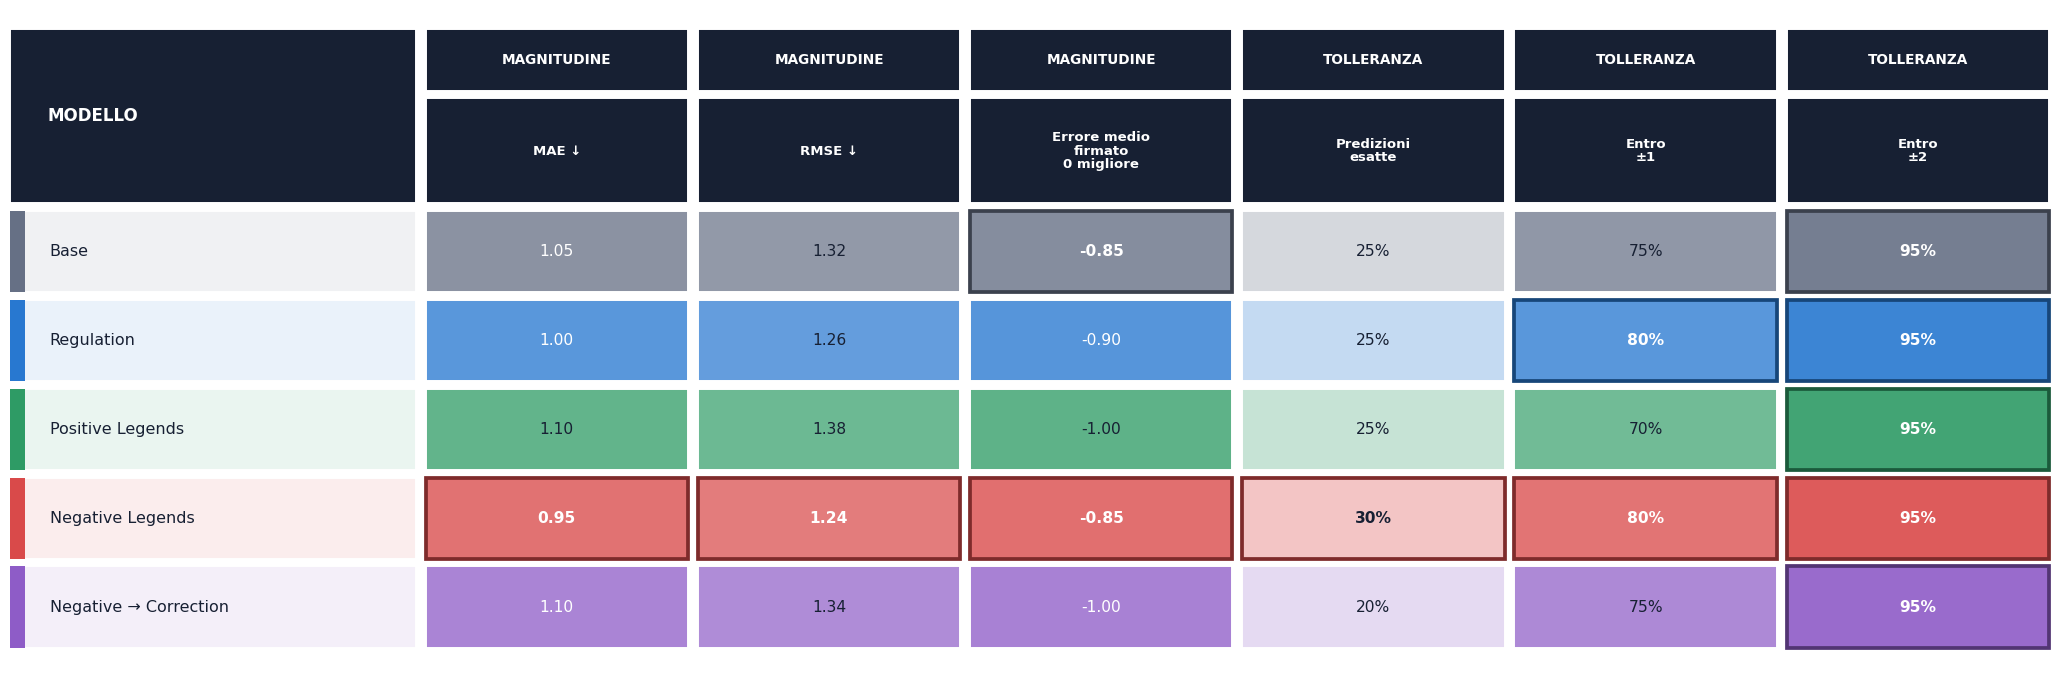

In [599]:
# CELLA 19 — Matrice standard, simmetrica e completa
# delle metriche di errore STS-B.
#
# Sezioni:
# - MAGNITUDINE: MAE, RMSE, errore medio firmato;
# - TOLLERANZA: predizioni esatte, entro ±1, entro ±2.
#
# Tutte le colonne metriche hanno la stessa larghezza.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import colors as mcolors
from matplotlib.patches import Rectangle


# =====================================================================
# FUNZIONI LOCALI
# =====================================================================

def stsb_error_blend_colors(
    background_color: str,
    foreground_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """
    Miscela il colore del modello con il colore di sfondo.

    amount:
    - 0 restituisce il colore di sfondo;
    - 1 restituisce il colore pieno del modello.
    """

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    background_rgb = np.asarray(
        mcolors.to_rgb(
            background_color
        )
    )

    foreground_rgb = np.asarray(
        mcolors.to_rgb(
            foreground_color
        )
    )

    return tuple(
        background_rgb
        * (
            1.0
            - amount
        )
        + foreground_rgb
        * amount
    )


def stsb_error_get_contrast_text_color(
    background_color,
) -> str:
    """
    Restituisce blu scuro oppure bianco
    in base alla luminosità della cella.
    """

    red, green, blue = mcolors.to_rgb(
        background_color
    )

    relative_luminance = (
        0.2126
        * red
        + 0.7152
        * green
        + 0.0722
        * blue
    )

    if relative_luminance >= 0.58:
        return "#172033"

    return "white"


def normalize_stsb_error_value(
    value: float,
    direction: str,
    lower_limit: float,
    upper_limit: float,
) -> float:
    """
    Converte il valore nell'intensità cromatica 0–1.

    higher:
        valore alto -> maggiore intensità.

    lower:
        valore basso -> maggiore intensità.

    zero:
        valore più vicino a zero -> maggiore intensità.
    """

    if pd.isna(
        value
    ):
        return np.nan

    numeric_value = float(
        value
    )

    if upper_limit <= lower_limit:
        raise ValueError(
            "upper_limit deve essere maggiore di lower_limit."
        )


    if direction == "higher":
        normalized_value = (
            numeric_value
            - lower_limit
        ) / (
            upper_limit
            - lower_limit
        )


    elif direction == "lower":
        normalized_value = (
            upper_limit
            - numeric_value
        ) / (
            upper_limit
            - lower_limit
        )


    elif direction == "zero":
        maximum_absolute_value = max(
            abs(
                lower_limit
            ),
            abs(
                upper_limit
            ),
        )

        if np.isclose(
            maximum_absolute_value,
            0.0,
        ):
            normalized_value = 1.0

        else:
            normalized_value = (
                1.0
                - abs(
                    numeric_value
                )
                / maximum_absolute_value
            )


    else:
        raise ValueError(
            f"Direzione non supportata: {direction}"
        )


    return float(
        np.clip(
            normalized_value,
            0.0,
            1.0,
        )
    )


# =====================================================================
# FUNZIONE PRINCIPALE
# =====================================================================

def plot_standard_stsb_error_matrix(
    dataframe: pd.DataFrame,
    output_path: Path,
):
    """
    Genera la matrice standard delle metriche
    di errore e tolleranza STS-B.
    """

    required_columns = {
        "model_name",
        "mae",
        "rmse",
        "mean_signed_error",
        "exact_rate",
        "within_1_rate",
        "within_2_rate",
    }


    missing_columns = (
        required_columns
        - set(
            dataframe.columns
        )
    )


    if missing_columns:
        raise RuntimeError(
            "Nella tabella STS-B mancano le colonne: "
            f"{sorted(missing_columns)}"
        )


    metric_columns = [
        "mae",
        "rmse",
        "mean_signed_error",
        "exact_rate",
        "within_1_rate",
        "within_2_rate",
    ]


    matrix_dataframe = (
        dataframe
        .set_index(
            "model_name"
        )
        .reindex(
            index=MODEL_ORDER
        )[
            metric_columns
        ]
        .copy()
    )


    if matrix_dataframe.isna().any().any():
        raise RuntimeError(
            "La matrice degli errori STS-B "
            "contiene valori mancanti."
        )


    # =================================================================
    # CONFIGURAZIONE DELLE METRICHE
    # =================================================================

    column_top_names = {
        "mae": "MAGNITUDINE",
        "rmse": "MAGNITUDINE",
        "mean_signed_error": "MAGNITUDINE",
        "exact_rate": "TOLLERANZA",
        "within_1_rate": "TOLLERANZA",
        "within_2_rate": "TOLLERANZA",
    }


    column_bottom_names = {
        "mae": (
            "MAE ↓"
        ),

        "rmse": (
            "RMSE ↓"
        ),

        "mean_signed_error": (
            "Errore medio\n"
            "firmato\n"
            "0 migliore"
        ),

        "exact_rate": (
            "Predizioni\n"
            "esatte"
        ),

        "within_1_rate": (
            "Entro\n"
            "±1"
        ),

        "within_2_rate": (
            "Entro\n"
            "±2"
        ),
    }


    metric_directions = {
        "mae": "lower",
        "rmse": "lower",
        "mean_signed_error": "zero",
        "exact_rate": "higher",
        "within_1_rate": "higher",
        "within_2_rate": "higher",
    }


    # Scale assolute e non dipendenti
    # dai soli valori osservati nei cinque modelli.
    absolute_color_limits = {
        "mae": (
            0.0,
            5.0,
        ),

        "rmse": (
            0.0,
            5.0,
        ),

        "mean_signed_error": (
            -5.0,
            5.0,
        ),

        "exact_rate": (
            0.0,
            1.0,
        ),

        "within_1_rate": (
            0.0,
            1.0,
        ),

        "within_2_rate": (
            0.0,
            1.0,
        ),
    }


    metric_formatters = {
        "mae": (
            lambda value:
            f"{value:.2f}"
        ),

        "rmse": (
            lambda value:
            f"{value:.2f}"
        ),

        "mean_signed_error": (
            lambda value:
            f"{value:+.2f}"
        ),

        "exact_rate": (
            lambda value:
            f"{value * 100:.0f}%"
        ),

        "within_1_rate": (
            lambda value:
            f"{value * 100:.0f}%"
        ),

        "within_2_rate": (
            lambda value:
            f"{value * 100:.0f}%"
        ),
    }


    raw_values = (
        matrix_dataframe
        .to_numpy(
            dtype=float
        )
    )


    number_of_models = len(
        matrix_dataframe.index
    )

    number_of_metrics = len(
        matrix_dataframe.columns
    )


    normalized_values = np.full_like(
        raw_values,
        np.nan,
        dtype=float,
    )


    for column_index, column_name in enumerate(
        matrix_dataframe.columns
    ):
        direction = (
            metric_directions[
                column_name
            ]
        )

        lower_limit, upper_limit = (
            absolute_color_limits[
                column_name
            ]
        )

        for row_index in range(
            number_of_models
        ):
            normalized_values[
                row_index,
                column_index,
            ] = normalize_stsb_error_value(
                value=raw_values[
                    row_index,
                    column_index,
                ],

                direction=direction,

                lower_limit=lower_limit,

                upper_limit=upper_limit,
            )


    # =================================================================
    # DIMENSIONI DEL TEMPLATE
    # =================================================================

    model_column_width = 4.20

    # Tutte le sei colonne hanno la stessa larghezza.
    metric_column_width = 2.75

    horizontal_gap = 0.10
    vertical_gap = 0.08

    row_height = 0.92

    category_header_height = 0.72

    # Sufficiente per intestazioni fino a tre righe.
    metric_header_height = 1.16

    complete_header_height = (
        category_header_height
        + metric_header_height
    )

    bottom_margin = 0.22
    top_margin = 0.12


    total_width = (
        model_column_width
        + number_of_metrics
        * metric_column_width
    )


    total_height = (
        bottom_margin
        + number_of_models
        * row_height
        + complete_header_height
        + top_margin
    )


    figure, axis = plt.subplots(
        figsize=(
            20.8,
            6.8,
        )
    )


    figure.patch.set_facecolor(
        "white"
    )

    axis.set_facecolor(
        "white"
    )

    axis.set_xlim(
        0,
        total_width,
    )

    axis.set_ylim(
        0,
        total_height,
    )

    axis.axis(
        "off"
    )


    rows_bottom = (
        bottom_margin
    )


    header_bottom = (
        rows_bottom
        + number_of_models
        * row_height
    )


    metric_header_bottom = (
        header_bottom
    )


    category_header_bottom = (
        metric_header_bottom
        + metric_header_height
    )


    header_color = "#172033"


    # =================================================================
    # INTESTAZIONE DELLA COLONNA MODELLO
    # =================================================================

    axis.add_patch(
        Rectangle(
            xy=(
                0,
                header_bottom,
            ),

            width=(
                model_column_width
                - horizontal_gap
            ),

            height=(
                complete_header_height
                - vertical_gap
            ),

            facecolor=header_color,

            edgecolor="white",

            linewidth=1.4,
        )
    )


    axis.text(
        0.38,

        header_bottom
        + (
            complete_header_height
            - vertical_gap
        )
        / 2,

        "MODELLO",

        ha="left",

        va="center",

        fontsize=12,

        fontweight="bold",

        color="white",
    )


    # =================================================================
    # INTESTAZIONI DELLE METRICHE
    # =================================================================

    for column_index, column_name in enumerate(
        matrix_dataframe.columns
    ):
        cell_x = (
            model_column_width
            + column_index
            * metric_column_width
        )


        cell_width = (
            metric_column_width
            - horizontal_gap
        )


        # -------------------------------------------------------------
        # RIGA SUPERIORE: CATEGORIA
        # -------------------------------------------------------------

        axis.add_patch(
            Rectangle(
                xy=(
                    cell_x,
                    category_header_bottom,
                ),

                width=cell_width,

                height=(
                    category_header_height
                    - vertical_gap
                ),

                facecolor=header_color,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,

            category_header_bottom
            + (
                category_header_height
                - vertical_gap
            )
            / 2,

            column_top_names[
                column_name
            ],

            ha="center",

            va="center",

            fontsize=9.8,

            fontweight="bold",

            color="white",
        )


        # -------------------------------------------------------------
        # RIGA INFERIORE: METRICA
        # -------------------------------------------------------------

        axis.add_patch(
            Rectangle(
                xy=(
                    cell_x,
                    metric_header_bottom,
                ),

                width=cell_width,

                height=(
                    metric_header_height
                    - vertical_gap
                ),

                facecolor=header_color,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,

            metric_header_bottom
            + (
                metric_header_height
                - vertical_gap
            )
            / 2,

            column_bottom_names[
                column_name
            ],

            ha="center",

            va="center",

            fontsize=9.5,

            fontweight="bold",

            color="white",

            linespacing=1.05,

            multialignment="center",
        )


    # =================================================================
    # RIGHE DEI MODELLI
    # =================================================================

    for row_index, model_name in enumerate(
        matrix_dataframe.index
    ):
        row_bottom = (
            rows_bottom
            + (
                number_of_models
                - 1
                - row_index
            )
            * row_height
        )


        model_color = (
            MODEL_COLORS[
                model_name
            ]
        )


        model_name_background = (
            stsb_error_blend_colors(
                background_color="#FFFFFF",

                foreground_color=model_color,

                amount=0.10,
            )
        )


        # -------------------------------------------------------------
        # CELLA CON IL NOME DEL MODELLO
        # -------------------------------------------------------------

        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=(
                    model_column_width
                    - horizontal_gap
                ),

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_name_background,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=0.15,

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_color,

                edgecolor="none",
            )
        )


        axis.text(
            0.40,

            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,

            MODEL_DISPLAY_NAMES[
                model_name
            ],

            ha="left",

            va="center",

            fontsize=11.5,

            fontweight="medium",

            color="#172033",
        )


        # -------------------------------------------------------------
        # CELLE NUMERICHE
        # -------------------------------------------------------------

        for column_index, column_name in enumerate(
            matrix_dataframe.columns
        ):
            cell_x = (
                model_column_width
                + column_index
                * metric_column_width
            )


            cell_width = (
                metric_column_width
                - horizontal_gap
            )


            raw_value = raw_values[
                row_index,
                column_index,
            ]


            normalized_value = normalized_values[
                row_index,
                column_index,
            ]


            direction = (
                metric_directions[
                    column_name
                ]
            )


            best_models = get_best_models(
                matrix_dataframe[
                    column_name
                ],

                direction,
            )


            is_best_model = (
                model_name
                in best_models
            )


            if np.isnan(
                normalized_value
            ):
                cell_facecolor = (
                    "#EAECEF"
                )

            else:
                color_strength = (
                    0.05
                    + 0.90
                    * normalized_value
                )


                cell_facecolor = (
                    stsb_error_blend_colors(
                        background_color="#FFFFFF",

                        foreground_color=model_color,

                        amount=color_strength,
                    )
                )


            if is_best_model:
                cell_edgecolor = (
                    darken_color(
                        model_color,

                        0.42,
                    )
                )

                cell_linewidth = (
                    2.7
                )

            else:
                cell_edgecolor = (
                    "white"
                )

                cell_linewidth = (
                    1.4
                )


            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        row_bottom,
                    ),

                    width=cell_width,

                    height=(
                        row_height
                        - vertical_gap
                    ),

                    facecolor=cell_facecolor,

                    edgecolor=cell_edgecolor,

                    linewidth=cell_linewidth,
                )
            )


            value_text = (
                metric_formatters[
                    column_name
                ](
                    raw_value
                )
            )


            axis.text(
                cell_x
                + cell_width
                / 2,

                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                / 2,

                value_text,

                ha="center",

                va="center",

                fontsize=11.2,

                fontweight=(
                    "bold"
                    if is_best_model
                    else "normal"
                ),

                color=(
                    stsb_error_get_contrast_text_color(
                        cell_facecolor
                    )
                ),
            )


    figure.subplots_adjust(
        left=0.010,
        right=0.995,
        top=0.985,
        bottom=0.015,
    )


    save_figure(
        figure=figure,

        output_path=output_path,
    )


# =====================================================================
# GENERAZIONE DELLA MATRICE
# =====================================================================

plot_standard_stsb_error_matrix(
    dataframe=(
        stsb_summary_df
    ),

    output_path=(
        NUMERIC_PLOTS_DIR
        / "02_stsb_error_metrics_matrix.png"
    ),
)

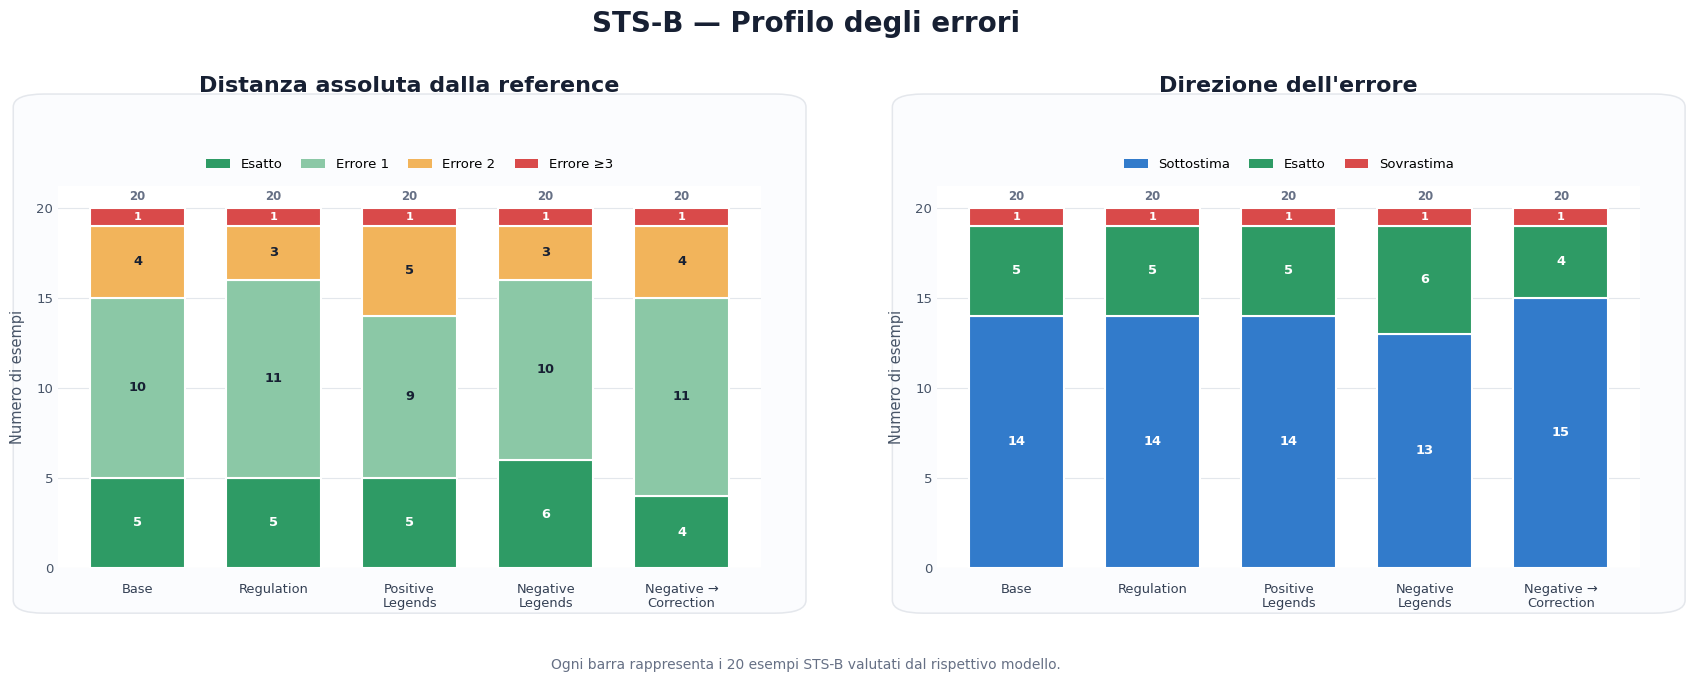

In [600]:
# CELLA 20 — Profilo degli errori STS-B.
#
# Pannello sinistro:
# - predizioni esatte;
# - errore assoluto pari a 1;
# - errore assoluto pari a 2;
# - errore assoluto maggiore o uguale a 3.
#
# Pannello destro:
# - sottostime;
# - predizioni esatte;
# - sovrastime.
#
# Il layout usa:
# - nomi dei modelli orizzontali;
# - pannelli separati e simmetrici;
# - legende collocate fuori dall'area dati;
# - valori riportati all'interno dei segmenti;
# - scala comune da 0 a 20 esempi.

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Patch, FancyBboxPatch


# =====================================================================
# PREPARAZIONE E VALIDAZIONE DEI DATI
# =====================================================================

required_error_profile_columns = {
    "model_name",
    "exact_count",
    "off_by_1_count",
    "off_by_2_count",
    "off_by_3_or_more_count",
    "underestimation_count",
    "exact_prediction_count",
    "overestimation_count",
}


missing_error_profile_columns = (
    required_error_profile_columns
    - set(
        stsb_summary_df.columns
    )
)


if missing_error_profile_columns:
    raise RuntimeError(
        "Nella sintesi STS-B mancano le colonne: "
        f"{sorted(missing_error_profile_columns)}"
    )


stsb_error_profile_df = (
    stsb_summary_df
    .set_index(
        "model_name"
    )
    .reindex(
        MODEL_ORDER
    )
)


if stsb_error_profile_df[
    list(
        required_error_profile_columns
        - {
            "model_name"
        }
    )
].isna().any().any():
    raise RuntimeError(
        "Il profilo degli errori STS-B contiene valori mancanti."
    )


# Controlla che ciascun pannello sommi a 20 esempi per modello.
absolute_error_totals = (
    stsb_error_profile_df[
        [
            "exact_count",
            "off_by_1_count",
            "off_by_2_count",
            "off_by_3_or_more_count",
        ]
    ]
    .sum(
        axis=1
    )
)


direction_error_totals = (
    stsb_error_profile_df[
        [
            "underestimation_count",
            "exact_prediction_count",
            "overestimation_count",
        ]
    ]
    .sum(
        axis=1
    )
)


if not (
    absolute_error_totals
    == EXPECTED_EXAMPLES_PER_TASK
).all():
    raise RuntimeError(
        "Le categorie della distanza assoluta "
        "non sommano a 20 esempi per ogni modello."
    )


if not (
    direction_error_totals
    == EXPECTED_EXAMPLES_PER_TASK
).all():
    raise RuntimeError(
        "Le categorie della direzione dell'errore "
        "non sommano a 20 esempi per ogni modello."
    )


# =====================================================================
# CONFIGURAZIONE VISIVA
# =====================================================================

model_axis_labels = {
    "base": "Base",
    "regulation": "Regulation",
    "positive_legends": "Positive\nLegends",
    "negative_legends": "Negative\nLegends",
    "negative_to_correction": "Negative →\nCorrection",
}


absolute_error_specs = [
    {
        "column": "exact_count",
        "label": "Esatto",
        "color": "#2E9B65",
        "text_color": "white",
    },

    {
        "column": "off_by_1_count",
        "label": "Errore 1",
        "color": "#8BC8A6",
        "text_color": "#172033",
    },

    {
        "column": "off_by_2_count",
        "label": "Errore 2",
        "color": "#F2B45B",
        "text_color": "#172033",
    },

    {
        "column": "off_by_3_or_more_count",
        "label": "Errore ≥3",
        "color": "#D94A4A",
        "text_color": "white",
    },
]


direction_error_specs = [
    {
        "column": "underestimation_count",
        "label": "Sottostima",
        "color": "#327BCB",
        "text_color": "white",
    },

    {
        "column": "exact_prediction_count",
        "label": "Esatto",
        "color": "#2E9B65",
        "text_color": "white",
    },

    {
        "column": "overestimation_count",
        "label": "Sovrastima",
        "color": "#D94A4A",
        "text_color": "white",
    },
]


x_positions = np.arange(
    len(
        MODEL_ORDER
    )
)


# =====================================================================
# FUNZIONI GRAFICHE LOCALI
# =====================================================================

def add_error_profile_card(
    figure: plt.Figure,
    axis: plt.Axes,
):
    """
    Aggiunge uno sfondo leggero dietro ciascun pannello,
    includendo anche titolo e legenda.
    """

    axis_position = axis.get_position()

    card = FancyBboxPatch(
        (
            axis_position.x0
            - 0.018,
            axis_position.y0
            - 0.055,
        ),

        axis_position.width
        + 0.036,

        axis_position.height
        + 0.175,

        transform=figure.transFigure,

        boxstyle=(
            "round,pad=0.008,"
            "rounding_size=0.018"
        ),

        facecolor="#FBFCFE",

        edgecolor="#E4E7EC",

        linewidth=1.1,

        zorder=-10,
    )

    figure.add_artist(
        card
    )


def draw_stacked_error_panel(
    axis: plt.Axes,
    specifications: list[dict],
    panel_title: str,
    legend_columns: int,
):
    """
    Disegna un pannello stacked coerente,
    con etichette interne e legenda esterna.
    """

    bottom_values = np.zeros(
        len(
            MODEL_ORDER
        ),
        dtype=float,
    )


    for specification in specifications:
        values = (
            stsb_error_profile_df[
                specification[
                    "column"
                ]
            ]
            .to_numpy(
                dtype=float
            )
        )


        bars = axis.bar(
            x_positions,
            values,

            bottom=bottom_values,

            width=0.70,

            color=specification[
                "color"
            ],

            edgecolor="white",

            linewidth=1.5,

            zorder=3,
        )


        for (
            bar,
            value,
            bottom,
        ) in zip(
            bars,
            values,
            bottom_values,
        ):
            if value <= 0:
                continue


            # Segmenti da un solo esempio mantengono
            # un carattere leggermente più piccolo.
            label_font_size = (
                8.2
                if value <= 1
                else 9.4
            )


            axis.text(
                bar.get_x()
                + bar.get_width()
                / 2,

                bottom
                + value
                / 2,

                str(
                    int(
                        value
                    )
                ),

                ha="center",

                va="center",

                fontsize=label_font_size,

                fontweight="bold",

                color=specification[
                    "text_color"
                ],

                zorder=5,
            )


        bottom_values += values


    # Piccolo totale sopra ogni barra.
    for x_position, total_value in zip(
        x_positions,
        bottom_values,
    ):
        axis.text(
            x_position,
            total_value
            + 0.30,
            str(
                int(
                    total_value
                )
            ),
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
            color="#667085",
        )


    axis.set_xticks(
        x_positions
    )


    axis.set_xticklabels(
        [
            model_axis_labels[
                model_name
            ]
            for model_name
            in MODEL_ORDER
        ],

        rotation=0,

        ha="center",

        fontsize=9.4,

        fontweight="medium",

        color="#344054",

        linespacing=1.10,
    )


    axis.set_ylim(
        0,
        21.2,
    )


    axis.set_yticks(
        [
            0,
            5,
            10,
            15,
            20,
        ]
    )


    axis.set_ylabel(
        "Numero di esempi",
        fontsize=10.5,
        color="#475467",
        labelpad=8,
    )


    axis.set_title(
        panel_title,
        fontsize=16,
        fontweight="bold",
        color="#172033",
        pad=68,
    )


    legend_handles = [
        Patch(
            facecolor=specification[
                "color"
            ],

            edgecolor="none",

            label=specification[
                "label"
            ],
        )
        for specification
        in specifications
    ]


    axis.legend(
        handles=legend_handles,

        loc="upper center",

        bbox_to_anchor=(
            0.5,
            1.105,
        ),

        ncol=legend_columns,

        frameon=False,

        fontsize=9.5,

        handlelength=1.8,

        columnspacing=1.45,
    )


    axis.grid(
        axis="y",
        color="#D9DEE5",
        linewidth=0.8,
        alpha=0.72,
        linestyle="-",
    )


    axis.set_axisbelow(
        True
    )


    axis.tick_params(
        axis="x",
        length=0,
        pad=11,
    )


    axis.tick_params(
        axis="y",
        length=0,
        colors="#475467",
    )


    for spine in axis.spines.values():
        spine.set_visible(
            False
        )


# =====================================================================
# CREAZIONE DELLA FIGURA
# =====================================================================

figure, axes = plt.subplots(
    nrows=1,
    ncols=2,

    figsize=(
        17.2,
        7.2,
    ),
)


figure.patch.set_facecolor(
    "white"
)


figure.subplots_adjust(
    left=0.065,
    right=0.985,
    top=0.72,
    bottom=0.19,
    wspace=0.25,
)


# Le card vengono inserite prima dei dati,
# così restano dietro agli assi.
add_error_profile_card(
    figure,
    axes[
        0
    ],
)


add_error_profile_card(
    figure,
    axes[
        1
    ],
)


draw_stacked_error_panel(
    axis=axes[
        0
    ],

    specifications=(
        absolute_error_specs
    ),

    panel_title=(
        "Distanza assoluta dalla reference"
    ),

    legend_columns=4,
)


draw_stacked_error_panel(
    axis=axes[
        1
    ],

    specifications=(
        direction_error_specs
    ),

    panel_title=(
        "Direzione dell'errore"
    ),

    legend_columns=3,
)


figure.suptitle(
    "STS-B — Profilo degli errori",

    fontsize=20,

    fontweight="bold",

    color="#172033",

    y=0.965,
)


figure.text(
    0.5,
    0.055,

    (
        "Ogni barra rappresenta i 20 esempi STS-B "
        "valutati dal rispettivo modello."
    ),

    ha="center",

    va="center",

    fontsize=10,

    color="#667085",
)


save_figure(
    figure=figure,

    output_path=(
        NUMERIC_PLOTS_DIR
        / "03_stsb_error_distributions.png"
    ),
)

,model_name,y_true,mean_prediction,prediction_std,minimum_prediction,maximum_prediction,n_examples,lower_band,upper_band
0,base,0,0.000,0.000,0,0,3,0.000,0.000
1,base,1,1.000,1.414,0,3,3,0.000,2.414
2,base,2,0.000,0.000,0,0,3,0.000,0.000
3,base,3,1.500,0.866,0,2,4,0.634,2.366
4,base,4,3.500,0.500,3,4,4,3.000,4.000
5,base,5,4.000,0.000,4,4,3,4.000,4.000
6,negative_legends,0,0.000,0.000,0,0,3,0.000,0.000
7,negative_legends,1,0.667,0.943,0,2,3,0.000,1.609
8,negative_legends,2,0.000,0.000,0,0,3,0.000,0.000
9,negative_legends,3,1.500,0.866,0,2,4,0.634,2.366


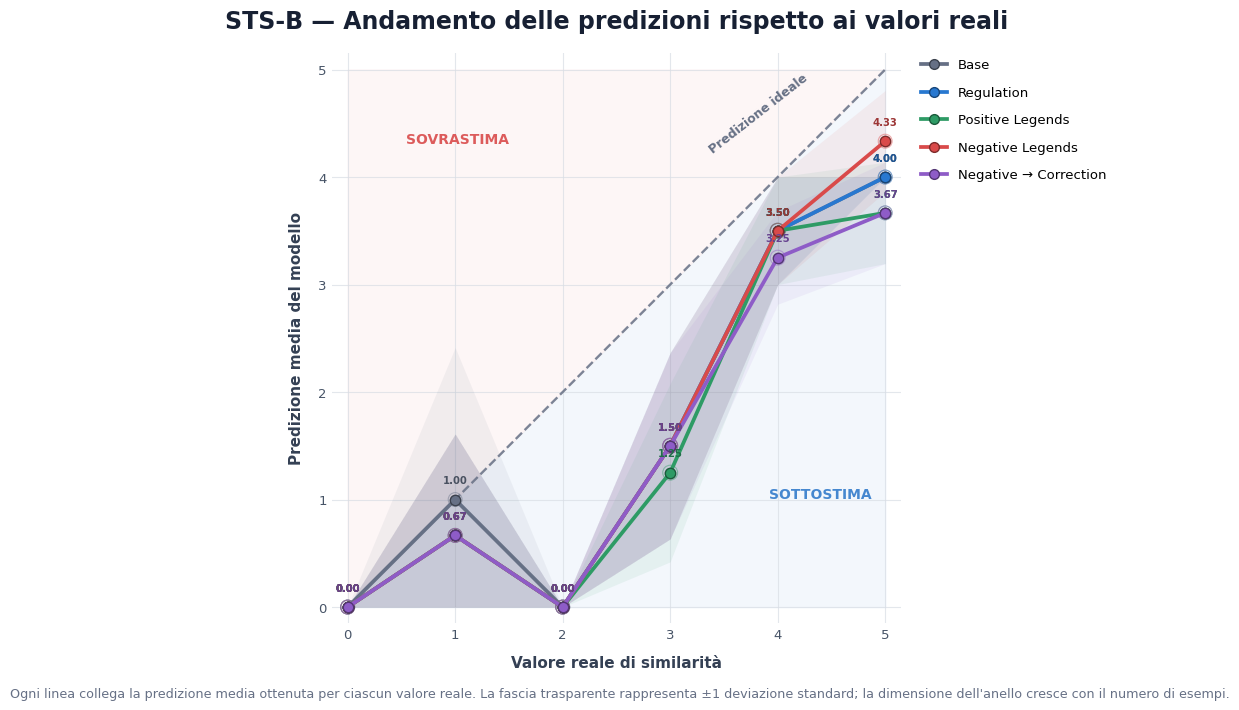

In [601]:
# CELLA 21 — STS-B: andamento delle predizioni rispetto ai valori reali.
#
# Per ogni valore reale da 0 a 5 viene calcolata, per ciascun modello:
# - la predizione media;
# - la deviazione standard delle predizioni;
# - il numero di esempi disponibili.
#
# La linea tratteggiata rappresenta il comportamento ideale:
# valore predetto = valore reale.
#
# Questa cella sostituisce:
# - i cinque scatter plot separati;
# - il dashboard sperimentale con le singole metriche.
#
# Produce un solo grafico di andamento direttamente confrontabile.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D


# =====================================================================
# VALIDAZIONE DEI DATI
# =====================================================================

required_columns = {
    "model_name",
    "y_true",
    "y_pred",
}


missing_columns = (
    required_columns
    - set(
        stsb_results_df.columns
    )
)


if missing_columns:
    raise RuntimeError(
        "Nel dataframe STS-B mancano le colonne: "
        f"{sorted(missing_columns)}"
    )


stsb_trend_source_df = (
    stsb_results_df[
        [
            "model_name",
            "example_id",
            "y_true",
            "y_pred",
        ]
    ]
    .copy()
)


stsb_trend_source_df[
    "y_true"
] = pd.to_numeric(
    stsb_trend_source_df[
        "y_true"
    ],
    errors="raise",
)


stsb_trend_source_df[
    "y_pred"
] = pd.to_numeric(
    stsb_trend_source_df[
        "y_pred"
    ],
    errors="raise",
)


unexpected_models = (
    set(
        stsb_trend_source_df[
            "model_name"
        ]
    )
    - set(
        MODEL_ORDER
    )
)


if unexpected_models:
    raise RuntimeError(
        "Sono presenti modelli inattesi nei risultati STS-B: "
        f"{sorted(unexpected_models)}"
    )


# =====================================================================
# CALCOLO DELL'ANDAMENTO
# =====================================================================

stsb_prediction_trend_df = (
    stsb_trend_source_df
    .groupby(
        [
            "model_name",
            "y_true",
        ],
        as_index=False,
    )
    .agg(
        mean_prediction=(
            "y_pred",
            "mean",
        ),

        prediction_std=(
            "y_pred",
            lambda values: float(
                np.std(
                    values,
                    ddof=0,
                )
            ),
        ),

        minimum_prediction=(
            "y_pred",
            "min",
        ),

        maximum_prediction=(
            "y_pred",
            "max",
        ),

        n_examples=(
            "example_id",
            "count",
        ),
    )
)


stsb_prediction_trend_df[
    "lower_band"
] = np.clip(
    stsb_prediction_trend_df[
        "mean_prediction"
    ]
    - stsb_prediction_trend_df[
        "prediction_std"
    ],
    0.0,
    5.0,
)


stsb_prediction_trend_df[
    "upper_band"
] = np.clip(
    stsb_prediction_trend_df[
        "mean_prediction"
    ]
    + stsb_prediction_trend_df[
        "prediction_std"
    ],
    0.0,
    5.0,
)


display(
    stsb_prediction_trend_df
    .sort_values(
        [
            "model_name",
            "y_true",
        ]
    )
    .round(
        3
    )
)


# =====================================================================
# CONFIGURAZIONE GRAFICA
# =====================================================================

TEXT_COLOR = "#172033"
MUTED_TEXT_COLOR = "#667085"
GRID_COLOR = "#D9DEE5"


figure, axis = plt.subplots(
    figsize=(
        13.8,
        7.4,
    )
)


figure.patch.set_facecolor(
    "white"
)


axis.set_facecolor(
    "white"
)


# =====================================================================
# ZONE VISIVE DI SOTTOSTIMA E SOVRASTIMA
# =====================================================================

scale_values = np.linspace(
    0.0,
    5.0,
    300,
)


# Sotto la diagonale:
# valore predetto inferiore al valore reale.
axis.fill_between(
    scale_values,
    0.0,
    scale_values,
    color="#EAF2FB",
    alpha=0.55,
    zorder=0,
)


# Sopra la diagonale:
# valore predetto superiore al valore reale.
axis.fill_between(
    scale_values,
    scale_values,
    5.0,
    color="#FCEEEE",
    alpha=0.48,
    zorder=0,
)


# =====================================================================
# LINEA DELLA PREDIZIONE IDEALE
# =====================================================================

axis.plot(
    [
        0,
        5,
    ],
    [
        0,
        5,
    ],
    color="#667085",
    linewidth=1.7,
    linestyle="--",
    alpha=0.85,
    zorder=2,
)


axis.text(
    3.82,
    4.20,
    "Predizione ideale",
    ha="center",
    va="bottom",
    fontsize=9,
    fontweight="bold",
    color="#667085",
    rotation=38,
)


# =====================================================================
# ANDAMENTO DEI CINQUE MODELLI
# =====================================================================

for model_name in MODEL_ORDER:
    model_data = (
        stsb_prediction_trend_df[
            stsb_prediction_trend_df[
                "model_name"
            ]
            == model_name
        ]
        .sort_values(
            "y_true"
        )
        .copy()
    )


    if model_data.empty:
        continue


    model_color = MODEL_COLORS[
        model_name
    ]


    true_values = (
        model_data[
            "y_true"
        ]
        .to_numpy(
            dtype=float
        )
    )


    mean_predictions = (
        model_data[
            "mean_prediction"
        ]
        .to_numpy(
            dtype=float
        )
    )


    lower_band = (
        model_data[
            "lower_band"
        ]
        .to_numpy(
            dtype=float
        )
    )


    upper_band = (
        model_data[
            "upper_band"
        ]
        .to_numpy(
            dtype=float
        )
    )


    example_counts = (
        model_data[
            "n_examples"
        ]
        .to_numpy(
            dtype=float
        )
    )


    # ---------------------------------------------------------------
    # Fascia di dispersione ± deviazione standard.
    # ---------------------------------------------------------------

    axis.fill_between(
        true_values,
        lower_band,
        upper_band,
        color=model_color,
        alpha=0.075,
        linewidth=0,
        zorder=1,
    )


    # ---------------------------------------------------------------
    # Linea della predizione media.
    # ---------------------------------------------------------------

    axis.plot(
        true_values,
        mean_predictions,
        color=model_color,
        linewidth=2.7,
        marker="o",
        markersize=7.5,
        markerfacecolor=model_color,
        markeredgecolor=darken_color(
            model_color,
            0.42,
        ),
        markeredgewidth=1.0,
        label=MODEL_DISPLAY_NAMES[
            model_name
        ],
        zorder=4,
    )


    # ---------------------------------------------------------------
    # Dimensione supplementare dei punti:
    # anello proporzionale al numero di esempi.
    # ---------------------------------------------------------------

    axis.scatter(
        true_values,
        mean_predictions,
        s=(
            55
            + example_counts
            * 15
        ),
        facecolor="none",
        edgecolor=model_color,
        linewidth=0.8,
        alpha=0.45,
        zorder=3,
    )


    # ---------------------------------------------------------------
    # Valore medio accanto a ogni punto.
    # ---------------------------------------------------------------

    for (
        true_value,
        mean_prediction,
        n_examples,
    ) in zip(
        true_values,
        mean_predictions,
        example_counts,
    ):
        axis.annotate(
            f"{mean_prediction:.2f}",
            xy=(
                true_value,
                mean_prediction,
            ),
            xytext=(
                0,
                10,
            ),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=7.2,
            fontweight="bold",
            color=darken_color(
                model_color,
                0.28,
            ),
            zorder=6,
        )


# =====================================================================
# ETICHETTE DELLE AREE
# =====================================================================

axis.text(
    4.40,
    1.05,
    "SOTTOSTIMA",
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="#327BCB",
    alpha=0.90,
)


axis.text(
    1.02,
    4.35,
    "SOVRASTIMA",
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="#D94A4A",
    alpha=0.90,
)


# =====================================================================
# ASSI
# =====================================================================

axis.set_xlim(
    -0.15,
    5.15,
)


axis.set_ylim(
    -0.15,
    5.15,
)


axis.set_xticks(
    range(
        6
    )
)


axis.set_yticks(
    range(
        6
    )
)


axis.set_xlabel(
    "Valore reale di similarità",
    fontsize=11,
    fontweight="bold",
    color="#344054",
    labelpad=10,
)


axis.set_ylabel(
    "Predizione media del modello",
    fontsize=11,
    fontweight="bold",
    color="#344054",
    labelpad=10,
)


axis.set_title(
    "STS-B — Andamento delle predizioni rispetto ai valori reali",
    fontsize=17,
    fontweight="bold",
    color=TEXT_COLOR,
    pad=18,
)


axis.grid(
    axis="both",
    color=GRID_COLOR,
    linewidth=0.8,
    alpha=0.72,
)


axis.set_axisbelow(
    True
)


axis.tick_params(
    axis="both",
    length=0,
    colors="#475467",
)


for spine in axis.spines.values():
    spine.set_visible(
        False
    )


# Mantiene le due scale geometricamente confrontabili.
axis.set_aspect(
    "equal",
    adjustable="box",
)


# =====================================================================
# LEGENDA
# =====================================================================

legend_handles = [
    Line2D(
        [
            0
        ],
        [
            0
        ],
        color=MODEL_COLORS[
            model_name
        ],
        linewidth=2.7,
        marker="o",
        markersize=7,
        markerfacecolor=MODEL_COLORS[
            model_name
        ],
        markeredgecolor=darken_color(
            MODEL_COLORS[
                model_name
            ],
            0.42,
        ),
        label=MODEL_DISPLAY_NAMES[
            model_name
        ],
    )
    for model_name in MODEL_ORDER
]


axis.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(
        1.025,
        1.0,
    ),
    frameon=False,
    fontsize=9.5,
    borderaxespad=0,
    labelspacing=1.1,
)


# =====================================================================
# NOTA METODOLOGICA
# =====================================================================

figure.text(
    0.44,
    0.035,
    (
        "Ogni linea collega la predizione media ottenuta per ciascun "
        "valore reale. La fascia trasparente rappresenta ±1 deviazione "
        "standard; la dimensione dell'anello cresce con il numero di esempi."
    ),
    ha="center",
    va="center",
    fontsize=9.2,
    color=MUTED_TEXT_COLOR,
)


figure.subplots_adjust(
    left=0.085,
    right=0.79,
    top=0.90,
    bottom=0.13,
)


# =====================================================================
# SALVATAGGIO
# =====================================================================

save_figure(
    figure=figure,
    output_path=(
        NUMERIC_PLOTS_DIR
        / "04_stsb_true_vs_predicted.png"
    ),
)

,model_name,y_true,mae,mse,mean_signed_error,n_examples,rmse
0,base,0,0.000,0.000,0.000,3,0.000
1,base,1,1.333,2.000,0.000,3,1.414
2,base,2,2.000,4.000,-2.000,3,2.000
3,base,3,1.500,3.000,-1.500,4,1.732
4,base,4,0.500,0.500,-0.500,4,0.707
5,base,5,1.000,1.000,-1.000,3,1.000
18,negative_legends,0,0.000,0.000,0.000,3,0.000
19,negative_legends,1,1.000,1.000,-0.333,3,1.000
20,negative_legends,2,2.000,4.000,-2.000,3,2.000
21,negative_legends,3,1.500,3.000,-1.500,4,1.732


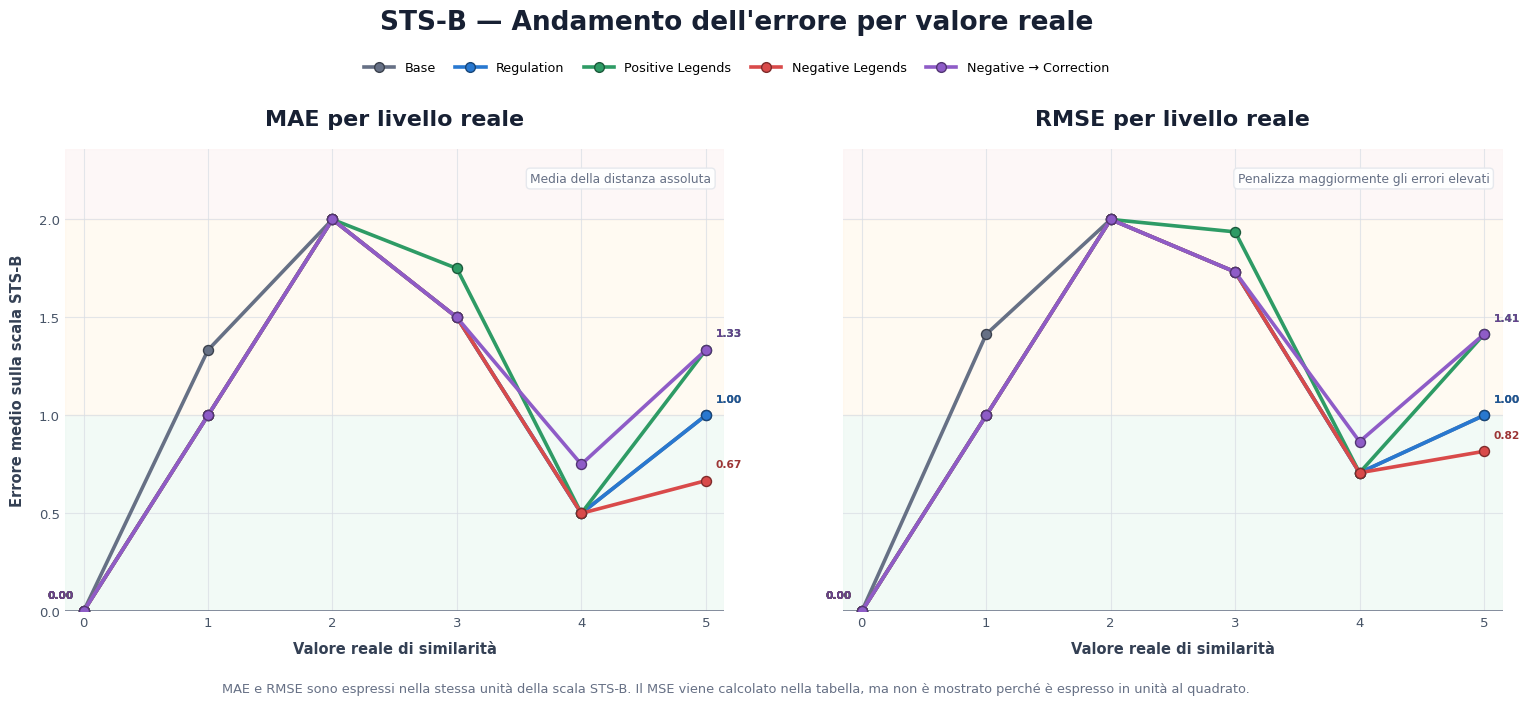

In [602]:
# CELLA 21-BIS — Andamento di MAE e RMSE per valore reale STS-B.
#
# Per ciascun valore reale di similarità da 0 a 5 calcola:
# - MAE: errore assoluto medio;
# - MSE: errore quadratico medio;
# - RMSE: radice dell'errore quadratico medio;
# - numero di esempi disponibili.
#
# Il grafico mostra MAE e RMSE in due pannelli coordinati.
# Valori più bassi indicano prestazioni migliori.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D


# =====================================================================
# VALIDAZIONE
# =====================================================================

required_error_trend_columns = {
    "model_name",
    "example_id",
    "y_true",
    "y_pred",
}


missing_error_trend_columns = (
    required_error_trend_columns
    - set(
        stsb_results_df.columns
    )
)


if missing_error_trend_columns:
    raise RuntimeError(
        "Nel dataframe STS-B mancano le colonne: "
        f"{sorted(missing_error_trend_columns)}"
    )


stsb_error_trend_source_df = (
    stsb_results_df[
        [
            "model_name",
            "example_id",
            "y_true",
            "y_pred",
        ]
    ]
    .copy()
)


stsb_error_trend_source_df[
    "y_true"
] = pd.to_numeric(
    stsb_error_trend_source_df[
        "y_true"
    ],
    errors="raise",
)


stsb_error_trend_source_df[
    "y_pred"
] = pd.to_numeric(
    stsb_error_trend_source_df[
        "y_pred"
    ],
    errors="raise",
)


stsb_error_trend_source_df[
    "signed_error"
] = (
    stsb_error_trend_source_df[
        "y_pred"
    ]
    - stsb_error_trend_source_df[
        "y_true"
    ]
)


stsb_error_trend_source_df[
    "absolute_error"
] = (
    stsb_error_trend_source_df[
        "signed_error"
    ].abs()
)


stsb_error_trend_source_df[
    "squared_error"
] = (
    stsb_error_trend_source_df[
        "signed_error"
    ]
    ** 2
)


# =====================================================================
# CALCOLO DI MAE, MSE E RMSE PER VALORE REALE
# =====================================================================

stsb_error_by_true_score_df = (
    stsb_error_trend_source_df
    .groupby(
        [
            "model_name",
            "y_true",
        ],
        as_index=False,
    )
    .agg(
        mae=(
            "absolute_error",
            "mean",
        ),

        mse=(
            "squared_error",
            "mean",
        ),

        mean_signed_error=(
            "signed_error",
            "mean",
        ),

        n_examples=(
            "example_id",
            "count",
        ),
    )
)


stsb_error_by_true_score_df[
    "rmse"
] = np.sqrt(
    stsb_error_by_true_score_df[
        "mse"
    ]
)


score_levels = list(
    range(
        6
    )
)


complete_error_index = pd.MultiIndex.from_product(
    [
        MODEL_ORDER,
        score_levels,
    ],
    names=[
        "model_name",
        "y_true",
    ],
)


stsb_error_by_true_score_df = (
    stsb_error_by_true_score_df
    .set_index(
        [
            "model_name",
            "y_true",
        ]
    )
    .reindex(
        complete_error_index
    )
    .reset_index()
)


display(
    stsb_error_by_true_score_df
    .sort_values(
        [
            "model_name",
            "y_true",
        ]
    )
    .round(
        {
            "mae": 3,
            "mse": 3,
            "rmse": 3,
            "mean_signed_error": 3,
        }
    )
)


# =====================================================================
# CONFIGURAZIONE GRAFICA
# =====================================================================

TEXT_COLOR = "#172033"
MUTED_TEXT_COLOR = "#667085"
GRID_COLOR = "#D9DEE5"


observed_error_values = (
    stsb_error_by_true_score_df[
        [
            "mae",
            "rmse",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


observed_error_values = observed_error_values[
    np.isfinite(
        observed_error_values
    )
]


if len(
    observed_error_values
) == 0:
    raise RuntimeError(
        "Non sono disponibili valori MAE o RMSE da rappresentare."
    )


maximum_observed_error = float(
    observed_error_values.max()
)


y_axis_maximum = min(
    5.0,
    max(
        1.25,
        maximum_observed_error
        * 1.18,
    ),
)


figure, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(
        15.8,
        6.8,
    ),
    sharex=True,
    sharey=True,
)


figure.patch.set_facecolor(
    "white"
)


# =====================================================================
# FUNZIONE DI STILE DEI DUE PANNELLI
# =====================================================================

def configure_error_trend_axis(
    axis: plt.Axes,
    title: str,
    metric_description: str,
):
    """
    Configura scala, fasce interpretative e stile del pannello.
    """

    axis.set_facecolor(
        "white"
    )


    # Errore contenuto: inferiore o uguale a 1.
    axis.axhspan(
        0.0,
        min(
            1.0,
            y_axis_maximum,
        ),
        color="#EAF7F0",
        alpha=0.58,
        zorder=0,
    )


    # Errore intermedio: compreso tra 1 e 2.
    if y_axis_maximum > 1.0:
        axis.axhspan(
            1.0,
            min(
                2.0,
                y_axis_maximum,
            ),
            color="#FFF6E6",
            alpha=0.50,
            zorder=0,
        )


    # Errore elevato: superiore a 2.
    if y_axis_maximum > 2.0:
        axis.axhspan(
            2.0,
            y_axis_maximum,
            color="#FCEEEE",
            alpha=0.43,
            zorder=0,
        )


    axis.axhline(
        0,
        color="#667085",
        linewidth=1.1,
        zorder=2,
    )


    axis.set_xlim(
        -0.15,
        5.15,
    )


    axis.set_ylim(
        0,
        y_axis_maximum,
    )


    axis.set_xticks(
        score_levels
    )


    axis.set_xlabel(
        "Valore reale di similarità",
        fontsize=10.5,
        fontweight="bold",
        color="#344054",
        labelpad=9,
    )


    axis.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        color=TEXT_COLOR,
        pad=17,
    )


    axis.text(
        0.98,
        0.95,
        metric_description,
        transform=axis.transAxes,
        ha="right",
        va="top",
        fontsize=8.8,
        color=MUTED_TEXT_COLOR,
        bbox={
            "boxstyle": (
                "round,pad=0.32"
            ),
            "facecolor": "white",
            "edgecolor": "#E4E7EC",
            "alpha": 0.92,
        },
        zorder=8,
    )


    axis.grid(
        axis="both",
        color=GRID_COLOR,
        linewidth=0.8,
        alpha=0.72,
    )


    axis.set_axisbelow(
        True
    )


    axis.tick_params(
        axis="both",
        length=0,
        colors="#475467",
    )


    for spine in axis.spines.values():
        spine.set_visible(
            False
        )


# =====================================================================
# DISEGNO DEGLI ANDAMENTI
# =====================================================================

panel_definitions = [
    {
        "axis": axes[
            0
        ],

        "metric": "mae",

        "title": (
            "MAE per livello reale"
        ),

        "description": (
            "Media della distanza assoluta"
        ),
    },

    {
        "axis": axes[
            1
        ],

        "metric": "rmse",

        "title": (
            "RMSE per livello reale"
        ),

        "description": (
            "Penalizza maggiormente gli errori elevati"
        ),
    },
]


for panel_definition in panel_definitions:
    axis = panel_definition[
        "axis"
    ]

    metric_name = panel_definition[
        "metric"
    ]


    configure_error_trend_axis(
        axis=axis,
        title=panel_definition[
            "title"
        ],
        metric_description=panel_definition[
            "description"
        ],
    )


    for model_name in MODEL_ORDER:
        model_data = (
            stsb_error_by_true_score_df[
                stsb_error_by_true_score_df[
                    "model_name"
                ]
                == model_name
            ]
            .set_index(
                "y_true"
            )
            .reindex(
                score_levels
            )
            .reset_index()
        )


        metric_values = (
            model_data[
                metric_name
            ]
            .to_numpy(
                dtype=float
            )
        )


        valid_mask = np.isfinite(
            metric_values
        )


        if not valid_mask.any():
            continue


        valid_scores = np.asarray(
            score_levels,
            dtype=float,
        )[
            valid_mask
        ]


        valid_metric_values = (
            metric_values[
                valid_mask
            ]
        )


        model_color = MODEL_COLORS[
            model_name
        ]


        axis.plot(
            valid_scores,
            valid_metric_values,
            color=model_color,
            linewidth=2.6,
            marker="o",
            markersize=7.2,
            markerfacecolor=model_color,
            markeredgecolor=darken_color(
                model_color,
                0.42,
            ),
            markeredgewidth=1.0,
            label=MODEL_DISPLAY_NAMES[
                model_name
            ],
            zorder=4,
        )


        # Etichetta soltanto il primo e l'ultimo punto disponibile,
        # evitando di riempire il grafico di numeri sovrapposti.
        endpoint_indices = {
            0,
            len(
                valid_scores
            )
            - 1,
        }


        for endpoint_index in endpoint_indices:
            score_value = valid_scores[
                endpoint_index
            ]

            metric_value = valid_metric_values[
                endpoint_index
            ]


            horizontal_offset = (
                -7
                if endpoint_index == 0
                else 7
            )


            axis.annotate(
                f"{metric_value:.2f}",
                xy=(
                    score_value,
                    metric_value,
                ),
                xytext=(
                    horizontal_offset,
                    8,
                ),
                textcoords="offset points",
                ha=(
                    "right"
                    if endpoint_index == 0
                    else "left"
                ),
                va="bottom",
                fontsize=7.7,
                fontweight="bold",
                color=darken_color(
                    model_color,
                    0.28,
                ),
                zorder=6,
            )


# Etichetta condivisa dell'asse Y.
axes[
    0
].set_ylabel(
    "Errore medio sulla scala STS-B",
    fontsize=10.5,
    fontweight="bold",
    color="#344054",
    labelpad=10,
)


# =====================================================================
# LEGENDA CONDIVISA
# =====================================================================

legend_handles = [
    Line2D(
        [
            0
        ],
        [
            0
        ],
        color=MODEL_COLORS[
            model_name
        ],
        linewidth=2.6,
        marker="o",
        markersize=7,
        markerfacecolor=MODEL_COLORS[
            model_name
        ],
        markeredgecolor=darken_color(
            MODEL_COLORS[
                model_name
            ],
            0.42,
        ),
        label=MODEL_DISPLAY_NAMES[
            model_name
        ],
    )
    for model_name in MODEL_ORDER
]


figure.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.965,
    ),
    ncol=len(
        MODEL_ORDER
    ),
    frameon=False,
    fontsize=9.2,
    columnspacing=1.5,
    handlelength=2.4,
)


# =====================================================================
# TITOLO E NOTA
# =====================================================================

figure.suptitle(
    "STS-B — Andamento dell'errore per valore reale",
    fontsize=19,
    fontweight="bold",
    color=TEXT_COLOR,
    y=1.025,
)


figure.text(
    0.5,
    0.025,
    (
        "MAE e RMSE sono espressi nella stessa unità della scala STS-B. "
        "Il MSE viene calcolato nella tabella, ma non è mostrato perché "
        "è espresso in unità al quadrato."
    ),
    ha="center",
    va="center",
    fontsize=9.3,
    color=MUTED_TEXT_COLOR,
)


figure.subplots_adjust(
    left=0.075,
    right=0.985,
    top=0.82,
    bottom=0.14,
    wspace=0.18,
)


# =====================================================================
# ESPORTAZIONE
# =====================================================================

stsb_error_by_true_score_df.to_csv(
    BLOCK_2_TABLES_DIR
    / "stsb_error_by_true_score.csv",
    index=False,
    encoding="utf-8-sig",
)


save_figure(
    figure,
    NUMERIC_PLOTS_DIR
    / "04B_stsb_mae_rmse_by_true_score.png",
)

## Tentativi alternativi — Similarità numerica

Le celle alternative osservano i residui a livello di singolo esempio:

- distribuzione dell’errore assoluto;
- residui firmati e dispersione;
- MAE distinto per valore reale da 0 a 5.

# Sezione 3 — Generazione testuale

Il task generativo non è stato incluso nel Blocco 1 dedicato ai sette task GLUE-style.

Viene quindi analizzato qui attraverso quattro sottosezioni autonome:

1. **BLEU**, per la sovrapposizione lessicale;
2. **ROUGE**, per la copertura del contenuto della reference;
3. **BERTScore**, per la similarità semantica contestuale;
4. **Valutazione soggettiva A/B**, per la qualità giudicata dai due valutatori.

Le metriche non vengono fuse in una media unica.

In [603]:
# CELLA 27 — Prepara e valida la tabella
# delle metriche generative aggregate.

GENERATION_REQUIRED_METRIC_COLUMNS = [
    "model_name",
    "mean_sentence_bleu",
    "corpus_bleu",
    "mean_rouge1_f1",
    "mean_rouge2_f1",
    "mean_rougeL_f1",
    "mean_bertscore_precision",
    "mean_bertscore_recall",
    "mean_bertscore_f1",
]

GENERATION_OPTIONAL_COLUMNS = [
    "mean_reference_word_count",
    "mean_generated_word_count",
    "median_generated_word_count",
    "mean_word_length_ratio",
]


missing_generation_columns = (
    set(
        GENERATION_REQUIRED_METRIC_COLUMNS
    )
    - set(
        generation_by_model_df.columns
    )
)


if missing_generation_columns:
    raise RuntimeError(
        "generation_metrics_by_model.csv: "
        "colonne mancanti "
        f"{sorted(missing_generation_columns)}"
    )


available_generation_columns = (
    GENERATION_REQUIRED_METRIC_COLUMNS
    + [
        column_name
        for column_name
        in GENERATION_OPTIONAL_COLUMNS
        if column_name
        in generation_by_model_df.columns
    ]
)


generation_metrics_table_df = sort_models(
    generation_by_model_df[
        available_generation_columns
    ].copy()
)


for column_name in available_generation_columns:
    if column_name == "model_name":
        continue

    generation_metrics_table_df[
        column_name
    ] = pd.to_numeric(
        generation_metrics_table_df[
            column_name
        ],
        errors="raise",
    )


display(
    generation_metrics_table_df
    .round(
        4
    )
)

,model_name,mean_sentence_bleu,corpus_bleu,mean_rouge1_f1,mean_rouge2_f1,mean_rougeL_f1,mean_bertscore_precision,mean_bertscore_recall,mean_bertscore_f1,mean_reference_word_count,mean_generated_word_count,median_generated_word_count,mean_word_length_ratio
0,base,0.0312,0.0319,0.2590,0.0702,0.1881,0.7249,0.7503,0.7369,24.0,48.65,45.0,2.0518
1,regulation,0.0356,0.0450,0.2762,0.0777,0.2355,0.7602,0.7352,0.7465,24.0,22.60,21.0,0.9731
2,positive_legends,0.0592,0.0758,0.3145,0.1224,0.2855,0.7854,0.7479,0.7658,24.0,18.75,18.5,0.7937
3,negative_legends,0.0495,0.0609,0.2940,0.1018,0.2603,0.7752,0.7427,0.7581,24.0,18.05,18.5,0.7628
4,negative_to_correction,0.0381,0.0491,0.2851,0.0870,0.2300,0.7793,0.7517,0.7647,24.0,19.90,21.0,0.8460


## 3.1 — BLEU

BLEU osserva soprattutto la sovrapposizione lessicale e delle sequenze di token con la reference.

Vengono mantenute separate:

- Mean Sentence BLEU;
- Corpus BLEU.

,model_name,mean_sentence_bleu,corpus_bleu
0,base,0.0312,0.0319
1,regulation,0.0356,0.0450
2,positive_legends,0.0592,0.0758
3,negative_legends,0.0495,0.0609
4,negative_to_correction,0.0381,0.0491


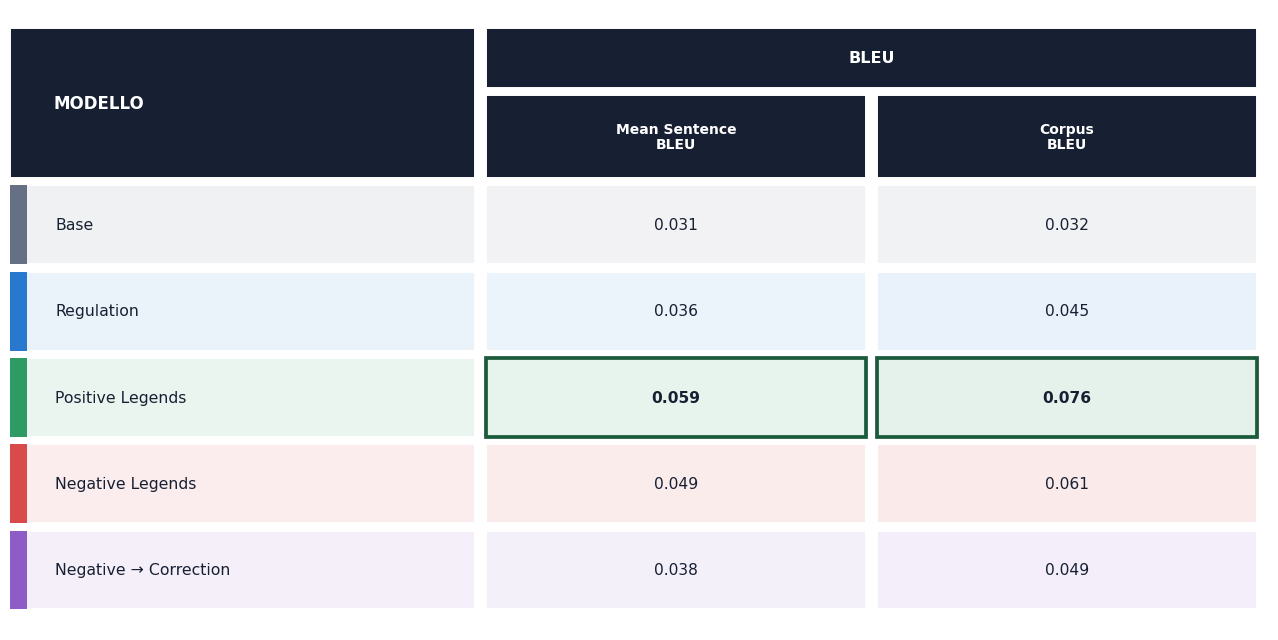

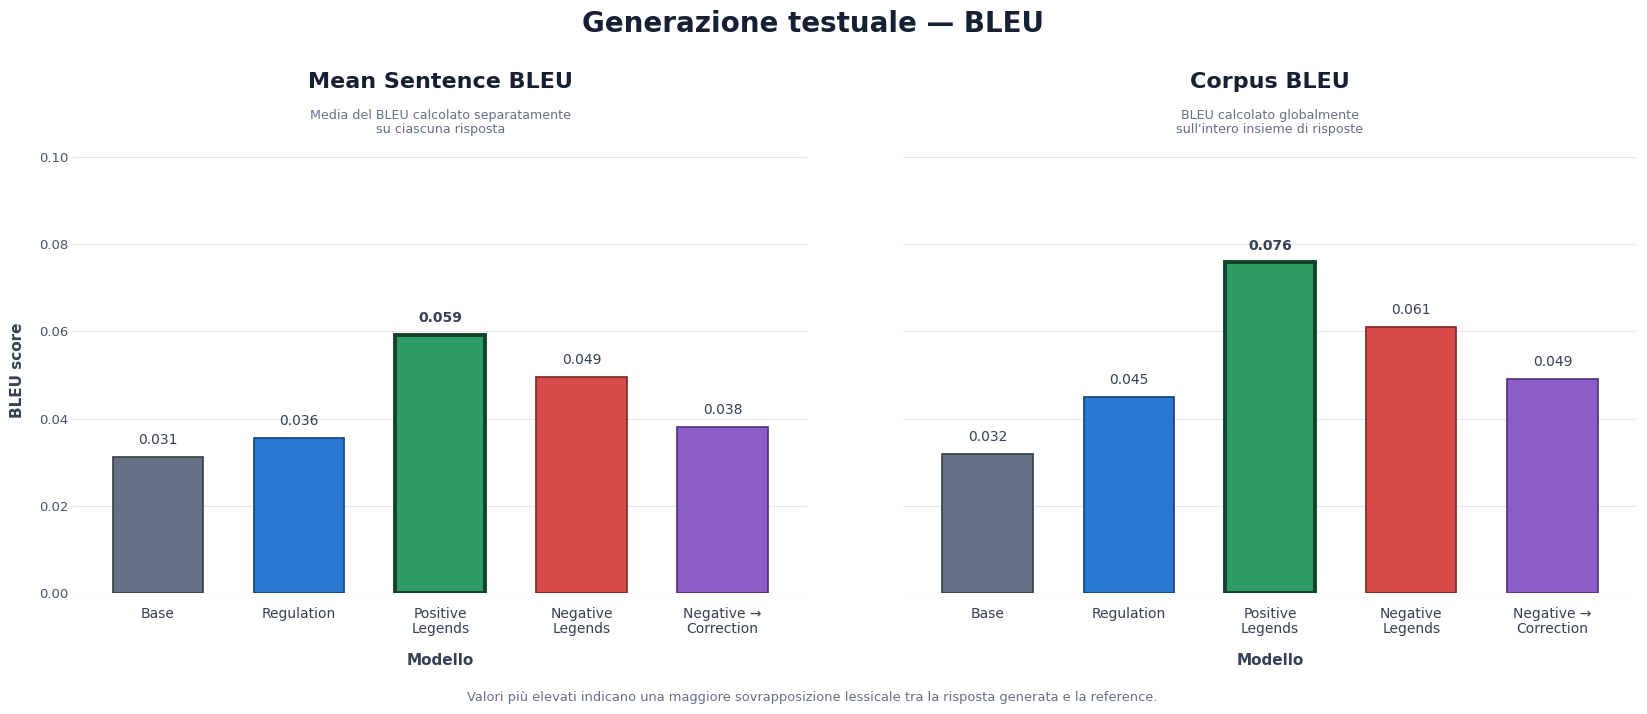

In [618]:
# CELLA 29 — Analisi delle sole metriche BLEU.
#
# Produce:
# 1. matrice standard BLEU;
# 2. due grafici separati:
#    - Mean Sentence BLEU;
#    - Corpus BLEU;
# 3. tabella CSV delle metriche BLEU.
#
# ROUGE e BERTScore restano nelle celle successive.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import colors as mcolors
from matplotlib.patches import Rectangle


# =====================================================================
# PREPARAZIONE E VALIDAZIONE
# =====================================================================

required_bleu_columns = {
    "model_name",
    "mean_sentence_bleu",
    "corpus_bleu",
}


missing_bleu_columns = (
    required_bleu_columns
    - set(
        generation_metrics_table_df.columns
    )
)


if missing_bleu_columns:
    raise RuntimeError(
        "Nella tabella generativa mancano le colonne BLEU: "
        f"{sorted(missing_bleu_columns)}"
    )


generation_bleu_df = (
    generation_metrics_table_df[
        [
            "model_name",
            "mean_sentence_bleu",
            "corpus_bleu",
        ]
    ]
    .copy()
    .set_index(
        "model_name"
    )
    .reindex(
        MODEL_ORDER
    )
    .reset_index()
)


for column_name in [
    "mean_sentence_bleu",
    "corpus_bleu",
]:
    generation_bleu_df[
        column_name
    ] = pd.to_numeric(
        generation_bleu_df[
            column_name
        ],
        errors="raise",
    )


if generation_bleu_df.isna().any().any():
    raise RuntimeError(
        "La tabella BLEU contiene valori mancanti."
    )


bleu_numeric_columns = [
    "mean_sentence_bleu",
    "corpus_bleu",
]


values_outside_range = (
    (
        generation_bleu_df[
            bleu_numeric_columns
        ]
        < 0.0
    )
    |
    (
        generation_bleu_df[
            bleu_numeric_columns
        ]
        > 1.0
    )
)


if values_outside_range.any().any():
    raise RuntimeError(
        "Sono presenti valori BLEU fuori dall'intervallo 0–1."
    )


generation_bleu_df.to_csv(
    BLOCK_2_TABLES_DIR
    / "generation_bleu_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)


display(
    generation_bleu_df.round(
        4
    )
)


# =====================================================================
# FUNZIONI GRAFICHE LOCALI
# =====================================================================

def bleu_blend_colors(
    background_color: str,
    foreground_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """
    Miscela il colore del modello con il colore di sfondo.
    """

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )


    background_rgb = np.asarray(
        mcolors.to_rgb(
            background_color
        )
    )


    foreground_rgb = np.asarray(
        mcolors.to_rgb(
            foreground_color
        )
    )


    return tuple(
        background_rgb
        * (
            1.0
            - amount
        )
        + foreground_rgb
        * amount
    )


def bleu_contrast_text_color(
    background_color,
) -> str:
    """
    Restituisce testo bianco o blu scuro
    in base alla luminosità dello sfondo.
    """

    red, green, blue = mcolors.to_rgb(
        background_color
    )


    luminance = (
        0.2126
        * red
        + 0.7152
        * green
        + 0.0722
        * blue
    )


    if luminance >= 0.58:
        return "#172033"

    return "white"


# =====================================================================
# MATRICE BLEU NEL TEMPLATE STANDARD
# =====================================================================

def plot_standard_bleu_matrix(
    dataframe: pd.DataFrame,
    output_path,
):
    """
    Genera la matrice standard delle sole metriche BLEU.
    """

    matrix_columns = [
        "mean_sentence_bleu",
        "corpus_bleu",
    ]


    matrix_dataframe = (
        dataframe
        .set_index(
            "model_name"
        )
        .reindex(
            MODEL_ORDER
        )[
            matrix_columns
        ]
        .copy()
    )


    metric_labels = {
        "mean_sentence_bleu": (
            "Mean Sentence\nBLEU"
        ),

        "corpus_bleu": (
            "Corpus\nBLEU"
        ),
    }


    raw_values = (
        matrix_dataframe
        .to_numpy(
            dtype=float
        )
    )


    number_of_models = len(
        matrix_dataframe.index
    )

    number_of_metrics = len(
        matrix_dataframe.columns
    )


    # -----------------------------------------------------------------
    # Dimensioni simmetriche
    # -----------------------------------------------------------------

    model_column_width = 4.20

    metric_column_width = 3.45

    horizontal_gap = 0.10
    vertical_gap = 0.08

    row_height = 0.92

    group_header_height = 0.72
    metric_header_height = 0.96

    complete_header_height = (
        group_header_height
        + metric_header_height
    )

    bottom_margin = 0.22
    top_margin = 0.12


    total_width = (
        model_column_width
        + number_of_metrics
        * metric_column_width
    )


    total_height = (
        bottom_margin
        + number_of_models
        * row_height
        + complete_header_height
        + top_margin
    )


    figure, axis = plt.subplots(
        figsize=(
            12.8,
            6.4,
        )
    )


    figure.patch.set_facecolor(
        "white"
    )

    axis.set_facecolor(
        "white"
    )


    axis.set_xlim(
        0,
        total_width,
    )

    axis.set_ylim(
        0,
        total_height,
    )

    axis.axis(
        "off"
    )


    rows_bottom = bottom_margin


    header_bottom = (
        rows_bottom
        + number_of_models
        * row_height
    )


    metric_header_bottom = (
        header_bottom
    )


    group_header_bottom = (
        metric_header_bottom
        + metric_header_height
    )


    header_color = "#172033"


    # -----------------------------------------------------------------
    # Header MODELLO
    # -----------------------------------------------------------------

    axis.add_patch(
        Rectangle(
            xy=(
                0,
                header_bottom,
            ),

            width=(
                model_column_width
                - horizontal_gap
            ),

            height=(
                complete_header_height
                - vertical_gap
            ),

            facecolor=header_color,

            edgecolor="white",

            linewidth=1.4,
        )
    )


    axis.text(
        0.38,

        header_bottom
        + (
            complete_header_height
            - vertical_gap
        )
        / 2,

        "MODELLO",

        ha="left",

        va="center",

        fontsize=12,

        fontweight="bold",

        color="white",
    )


    # -----------------------------------------------------------------
    # Header superiore BLEU
    # -----------------------------------------------------------------

    bleu_group_x = model_column_width


    bleu_group_width = (
        number_of_metrics
        * metric_column_width
        - horizontal_gap
    )


    axis.add_patch(
        Rectangle(
            xy=(
                bleu_group_x,
                group_header_bottom,
            ),

            width=bleu_group_width,

            height=(
                group_header_height
                - vertical_gap
            ),

            facecolor=header_color,

            edgecolor="white",

            linewidth=1.4,
        )
    )


    axis.text(
        bleu_group_x
        + bleu_group_width
        / 2,

        group_header_bottom
        + (
            group_header_height
            - vertical_gap
        )
        / 2,

        "BLEU",

        ha="center",

        va="center",

        fontsize=11.5,

        fontweight="bold",

        color="white",
    )


    # -----------------------------------------------------------------
    # Header delle due metriche
    # -----------------------------------------------------------------

    for column_index, column_name in enumerate(
        matrix_dataframe.columns
    ):
        cell_x = (
            model_column_width
            + column_index
            * metric_column_width
        )


        cell_width = (
            metric_column_width
            - horizontal_gap
        )


        axis.add_patch(
            Rectangle(
                xy=(
                    cell_x,
                    metric_header_bottom,
                ),

                width=cell_width,

                height=(
                    metric_header_height
                    - vertical_gap
                ),

                facecolor=header_color,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,

            metric_header_bottom
            + (
                metric_header_height
                - vertical_gap
            )
            / 2,

            metric_labels[
                column_name
            ],

            ha="center",

            va="center",

            fontsize=10,

            fontweight="bold",

            color="white",

            linespacing=1.08,

            multialignment="center",
        )


    # -----------------------------------------------------------------
    # Righe dei modelli
    # -----------------------------------------------------------------

    for row_index, model_name in enumerate(
        matrix_dataframe.index
    ):
        row_bottom = (
            rows_bottom
            + (
                number_of_models
                - 1
                - row_index
            )
            * row_height
        )


        model_color = MODEL_COLORS[
            model_name
        ]


        model_name_background = (
            bleu_blend_colors(
                background_color="#FFFFFF",

                foreground_color=model_color,

                amount=0.10,
            )
        )


        # -------------------------------------------------------------
        # Colonna modello
        # -------------------------------------------------------------

        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=(
                    model_column_width
                    - horizontal_gap
                ),

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_name_background,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=0.15,

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_color,

                edgecolor="none",
            )
        )


        axis.text(
            0.40,

            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,

            MODEL_DISPLAY_NAMES[
                model_name
            ],

            ha="left",

            va="center",

            fontsize=11.3,

            fontweight="medium",

            color="#172033",
        )


        # -------------------------------------------------------------
        # Celle numeriche
        # -------------------------------------------------------------

        for column_index, column_name in enumerate(
            matrix_dataframe.columns
        ):
            cell_x = (
                model_column_width
                + column_index
                * metric_column_width
            )


            cell_width = (
                metric_column_width
                - horizontal_gap
            )


            raw_value = float(
                raw_values[
                    row_index,
                    column_index,
                ]
            )


            normalized_value = float(
                np.clip(
                    raw_value,
                    0.0,
                    1.0,
                )
            )


            color_strength = (
                0.06
                + 0.90
                * normalized_value
            )


            cell_facecolor = (
                bleu_blend_colors(
                    background_color="#FFFFFF",

                    foreground_color=model_color,

                    amount=color_strength,
                )
            )


            best_models = get_best_models(
                matrix_dataframe[
                    column_name
                ],

                "higher",
            )


            is_best_model = (
                model_name
                in best_models
            )


            if is_best_model:
                cell_edgecolor = darken_color(
                    model_color,
                    0.42,
                )

                cell_linewidth = 2.7

            else:
                cell_edgecolor = "white"
                cell_linewidth = 1.4


            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        row_bottom,
                    ),

                    width=cell_width,

                    height=(
                        row_height
                        - vertical_gap
                    ),

                    facecolor=cell_facecolor,

                    edgecolor=cell_edgecolor,

                    linewidth=cell_linewidth,
                )
            )


            axis.text(
                cell_x
                + cell_width
                / 2,

                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                / 2,

                f"{raw_value:.3f}",

                ha="center",

                va="center",

                fontsize=11.2,

                fontweight=(
                    "bold"
                    if is_best_model
                    else "normal"
                ),

                color=(
                    bleu_contrast_text_color(
                        cell_facecolor
                    )
                ),
            )


    figure.subplots_adjust(
        left=0.012,
        right=0.995,
        top=0.985,
        bottom=0.015,
    )


    save_figure(
        figure=figure,

        output_path=output_path,
    )


plot_standard_bleu_matrix(
    dataframe=generation_bleu_df,

    output_path=(
        GENERATION_PLOTS_DIR
        / "01_generation_bleu_matrix.png"
    ),
)


# =====================================================================
# DUE GRAFICI BLEU SEPARATI
# =====================================================================

bleu_plot_df = (
    generation_bleu_df
    .set_index(
        "model_name"
    )
    .reindex(
        MODEL_ORDER
    )
)


model_axis_labels = {
    "base": "Base",

    "regulation": "Regulation",

    "positive_legends": (
        "Positive\nLegends"
    ),

    "negative_legends": (
        "Negative\nLegends"
    ),

    "negative_to_correction": (
        "Negative →\nCorrection"
    ),
}


x_positions = np.arange(
    len(
        MODEL_ORDER
    )
)


mean_sentence_values = (
    bleu_plot_df[
        "mean_sentence_bleu"
    ]
    .to_numpy(
        dtype=float
    )
)


corpus_values = (
    bleu_plot_df[
        "corpus_bleu"
    ]
    .to_numpy(
        dtype=float
    )
)


maximum_bleu_value = float(
    max(
        mean_sentence_values.max(),
        corpus_values.max(),
    )
)


# I due pannelli condividono esattamente la stessa scala.
y_axis_maximum = min(
    1.0,

    max(
        0.10,
        maximum_bleu_value
        * 1.35,
    ),
)


figure, axes = plt.subplots(
    nrows=1,
    ncols=2,

    figsize=(
        17.0,
        7.2,
    ),

    sharey=True,
)


figure.patch.set_facecolor(
    "white"
)


bleu_panel_definitions = [
    {
        "axis": axes[
            0
        ],

        "column": (
            "mean_sentence_bleu"
        ),

        "values": mean_sentence_values,

        "title": (
            "Mean Sentence BLEU"
        ),

        "description": (
            "Media del BLEU calcolato separatamente\n"
            "su ciascuna risposta"
        ),
    },

    {
        "axis": axes[
            1
        ],

        "column": (
            "corpus_bleu"
        ),

        "values": corpus_values,

        "title": (
            "Corpus BLEU"
        ),

        "description": (
            "BLEU calcolato globalmente\n"
            "sull'intero insieme di risposte"
        ),
    },
]


for panel_definition in bleu_panel_definitions:
    axis = panel_definition[
        "axis"
    ]

    metric_column = panel_definition[
        "column"
    ]

    metric_values = panel_definition[
        "values"
    ]


    best_models = get_best_models(
        bleu_plot_df[
            metric_column
        ],

        "higher",
    )


    bar_colors = [
        MODEL_COLORS[
            model_name
        ]
        for model_name
        in MODEL_ORDER
    ]


    bar_edges = [
        darken_color(
            MODEL_COLORS[
                model_name
            ],

            0.42,
        )
        for model_name
        in MODEL_ORDER
    ]


    bars = axis.bar(
        x_positions,
        metric_values,

        width=0.64,

        color=bar_colors,

        edgecolor=bar_edges,

        linewidth=1.25,

        zorder=3,
    )


    value_label_offset = (
        y_axis_maximum
        * 0.022
    )


    for (
        bar,
        model_name,
        metric_value,
    ) in zip(
        bars,
        MODEL_ORDER,
        metric_values,
    ):
        is_best_model = (
            model_name
            in best_models
        )


        if is_best_model:
            bar.set_linewidth(
                2.8
            )

            bar.set_edgecolor(
                darken_color(
                    MODEL_COLORS[
                        model_name
                    ],

                    0.57,
                )
            )


        axis.text(
            bar.get_x()
            + bar.get_width()
            / 2,

            metric_value
            + value_label_offset,

            f"{metric_value:.3f}",

            ha="center",

            va="bottom",

            fontsize=10,

            fontweight=(
                "bold"
                if is_best_model
                else "normal"
            ),

            color="#344054",

            zorder=5,
        )


    axis.set_xticks(
        x_positions
    )


    axis.set_xticklabels(
        [
            model_axis_labels[
                model_name
            ]
            for model_name
            in MODEL_ORDER
        ],

        rotation=0,

        ha="center",

        fontsize=10,

        fontweight="medium",

        color="#344054",

        linespacing=1.10,
    )


    axis.set_xlim(
        -0.60,
        len(
            MODEL_ORDER
        )
        - 0.40,
    )


    axis.set_ylim(
        0.0,
        y_axis_maximum,
    )


    axis.set_xlabel(
        "Modello",

        fontsize=11,

        fontweight="bold",

        color="#344054",

        labelpad=12,
    )


    axis.set_title(
        panel_definition[
            "title"
        ],

        fontsize=16,

        fontweight="bold",

        color="#172033",

        pad=42,
    )


    axis.text(
        0.5,
        1.025,

        panel_definition[
            "description"
        ],

        transform=axis.transAxes,

        ha="center",

        va="bottom",

        fontsize=9.1,

        color="#667085",

        linespacing=1.10,
    )


    axis.grid(
        axis="y",

        color="#D9DEE5",

        linewidth=0.8,

        alpha=0.75,
    )


    axis.set_axisbelow(
        True
    )


    axis.tick_params(
        axis="x",

        length=0,

        pad=10,
    )


    axis.tick_params(
        axis="y",

        length=0,

        colors="#475467",
    )


    for spine in axis.spines.values():
        spine.set_visible(
            False
        )


axes[
    0
].set_ylabel(
    "BLEU score",

    fontsize=11,

    fontweight="bold",

    color="#344054",

    labelpad=10,
)


figure.suptitle(
    "Generazione testuale — BLEU",

    fontsize=20,

    fontweight="bold",

    color="#172033",

    y=0.98,
)


figure.text(
    0.5,
    0.025,

    (
        "Valori più elevati indicano una maggiore sovrapposizione "
        "lessicale tra la risposta generata e la reference."
    ),

    ha="center",

    va="center",

    fontsize=9.4,

    color="#667085",
)


figure.subplots_adjust(
    left=0.065,
    right=0.985,
    top=0.79,
    bottom=0.17,
    wspace=0.13,
)


save_figure(
    figure=figure,

    output_path=(
        GENERATION_PLOTS_DIR
        / "01_generation_bleu.png"
    ),
)

## 3.2 — ROUGE

ROUGE osserva la copertura del contenuto della reference.

Nella visualizzazione principale vengono confrontati:

- ROUGE-1 F1;
- ROUGE-2 F1;
- ROUGE-L F1.

,model_name,mean_rouge1_f1,mean_rouge2_f1,mean_rougeL_f1
0,base,0.2590,0.0702,0.1881
1,regulation,0.2762,0.0777,0.2355
2,positive_legends,0.3145,0.1224,0.2855
3,negative_legends,0.2940,0.1018,0.2603
4,negative_to_correction,0.2851,0.0870,0.2300


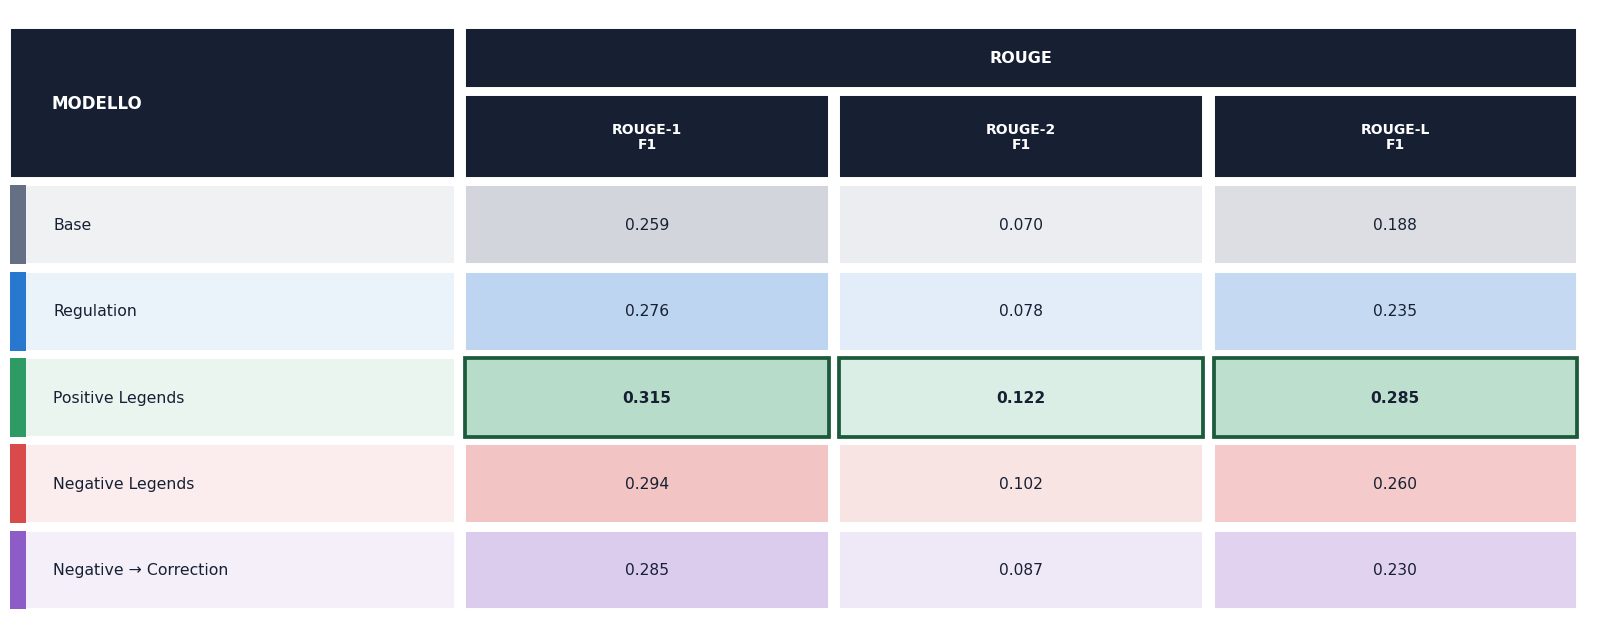

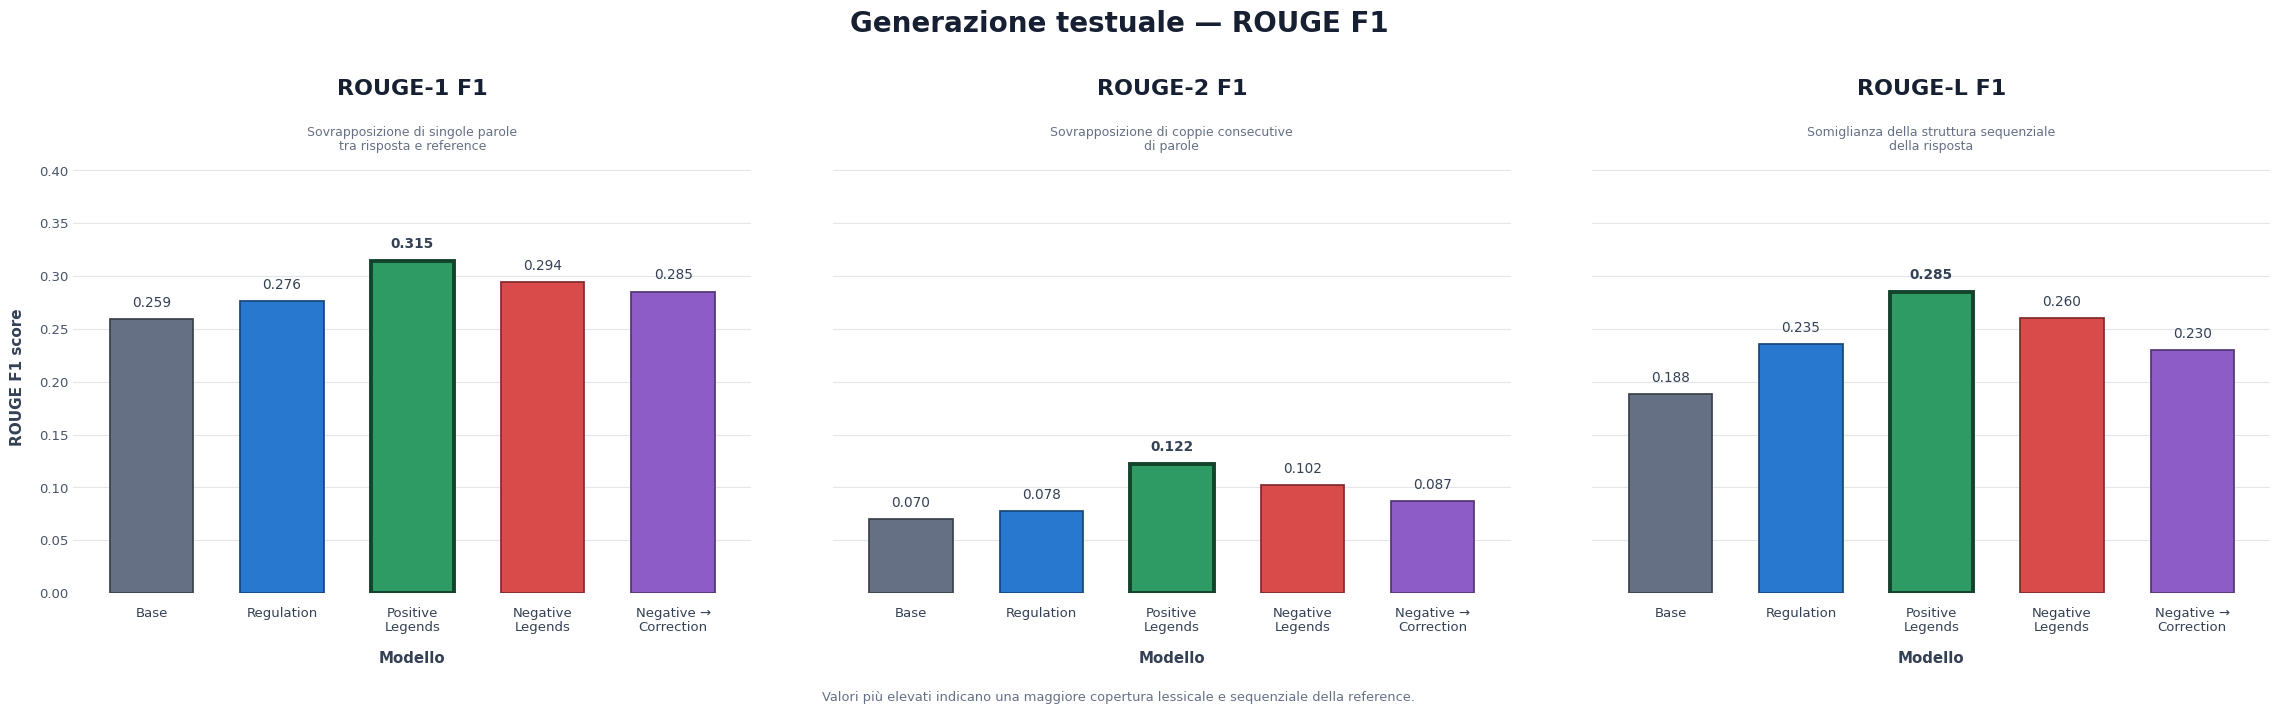

In [619]:
# CELLA 30 — Analisi delle sole metriche ROUGE.
#
# Produce:
# 1. matrice standard ROUGE;
# 2. tre grafici separati e affiancati:
#    - ROUGE-1 F1;
#    - ROUGE-2 F1;
#    - ROUGE-L F1;
# 3. tabella CSV delle metriche ROUGE.
#
# BLEU e BERTScore restano nelle rispettive celle dedicate.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import colors as mcolors
from matplotlib.patches import Rectangle


# =====================================================================
# PREPARAZIONE E VALIDAZIONE
# =====================================================================

required_rouge_columns = {
    "model_name",
    "mean_rouge1_f1",
    "mean_rouge2_f1",
    "mean_rougeL_f1",
}


missing_rouge_columns = (
    required_rouge_columns
    - set(
        generation_metrics_table_df.columns
    )
)


if missing_rouge_columns:
    raise RuntimeError(
        "Nella tabella generativa mancano le colonne ROUGE: "
        f"{sorted(missing_rouge_columns)}"
    )


generation_rouge_df = (
    generation_metrics_table_df[
        [
            "model_name",
            "mean_rouge1_f1",
            "mean_rouge2_f1",
            "mean_rougeL_f1",
        ]
    ]
    .copy()
    .set_index(
        "model_name"
    )
    .reindex(
        MODEL_ORDER
    )
    .reset_index()
)


rouge_numeric_columns = [
    "mean_rouge1_f1",
    "mean_rouge2_f1",
    "mean_rougeL_f1",
]


for column_name in rouge_numeric_columns:
    generation_rouge_df[
        column_name
    ] = pd.to_numeric(
        generation_rouge_df[
            column_name
        ],
        errors="raise",
    )


if generation_rouge_df.isna().any().any():
    raise RuntimeError(
        "La tabella ROUGE contiene valori mancanti."
    )


values_outside_range = (
    (
        generation_rouge_df[
            rouge_numeric_columns
        ]
        < 0.0
    )
    |
    (
        generation_rouge_df[
            rouge_numeric_columns
        ]
        > 1.0
    )
)


if values_outside_range.any().any():
    raise RuntimeError(
        "Sono presenti valori ROUGE fuori dall'intervallo 0–1."
    )


generation_rouge_df.to_csv(
    BLOCK_2_TABLES_DIR
    / "generation_rouge_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)


display(
    generation_rouge_df.round(
        4
    )
)


# =====================================================================
# FUNZIONI GRAFICHE LOCALI
# =====================================================================

def rouge_blend_colors(
    background_color: str,
    foreground_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """
    Miscela il colore del modello con il colore di sfondo.
    """

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )


    background_rgb = np.asarray(
        mcolors.to_rgb(
            background_color
        )
    )


    foreground_rgb = np.asarray(
        mcolors.to_rgb(
            foreground_color
        )
    )


    return tuple(
        background_rgb
        * (
            1.0
            - amount
        )
        + foreground_rgb
        * amount
    )


def rouge_contrast_text_color(
    background_color,
) -> str:
    """
    Restituisce testo bianco oppure blu scuro
    in base alla luminosità dello sfondo.
    """

    red, green, blue = mcolors.to_rgb(
        background_color
    )


    luminance = (
        0.2126
        * red
        + 0.7152
        * green
        + 0.0722
        * blue
    )


    if luminance >= 0.58:
        return "#172033"

    return "white"


# =====================================================================
# MATRICE ROUGE NEL TEMPLATE STANDARD
# =====================================================================

def plot_standard_rouge_matrix(
    dataframe: pd.DataFrame,
    output_path,
):
    """
    Genera la matrice standard delle sole metriche ROUGE F1.
    """

    matrix_columns = [
        "mean_rouge1_f1",
        "mean_rouge2_f1",
        "mean_rougeL_f1",
    ]


    matrix_dataframe = (
        dataframe
        .set_index(
            "model_name"
        )
        .reindex(
            MODEL_ORDER
        )[
            matrix_columns
        ]
        .copy()
    )


    metric_labels = {
        "mean_rouge1_f1": (
            "ROUGE-1\nF1"
        ),

        "mean_rouge2_f1": (
            "ROUGE-2\nF1"
        ),

        "mean_rougeL_f1": (
            "ROUGE-L\nF1"
        ),
    }


    raw_values = (
        matrix_dataframe
        .to_numpy(
            dtype=float
        )
    )


    number_of_models = len(
        matrix_dataframe.index
    )


    number_of_metrics = len(
        matrix_dataframe.columns
    )


    # =================================================================
    # DIMENSIONI SIMMETRICHE
    # =================================================================

    model_column_width = 4.20

    # Tutte le metriche hanno la stessa larghezza.
    metric_column_width = 3.45

    horizontal_gap = 0.10
    vertical_gap = 0.08

    row_height = 0.92

    group_header_height = 0.72
    metric_header_height = 0.96

    complete_header_height = (
        group_header_height
        + metric_header_height
    )

    bottom_margin = 0.22
    top_margin = 0.12


    total_width = (
        model_column_width
        + number_of_metrics
        * metric_column_width
    )


    total_height = (
        bottom_margin
        + number_of_models
        * row_height
        + complete_header_height
        + top_margin
    )


    figure, axis = plt.subplots(
        figsize=(
            16.0,
            6.4,
        )
    )


    figure.patch.set_facecolor(
        "white"
    )


    axis.set_facecolor(
        "white"
    )


    axis.set_xlim(
        0,
        total_width,
    )


    axis.set_ylim(
        0,
        total_height,
    )


    axis.axis(
        "off"
    )


    rows_bottom = bottom_margin


    header_bottom = (
        rows_bottom
        + number_of_models
        * row_height
    )


    metric_header_bottom = (
        header_bottom
    )


    group_header_bottom = (
        metric_header_bottom
        + metric_header_height
    )


    header_color = "#172033"


    # =================================================================
    # HEADER MODELLO
    # =================================================================

    axis.add_patch(
        Rectangle(
            xy=(
                0,
                header_bottom,
            ),

            width=(
                model_column_width
                - horizontal_gap
            ),

            height=(
                complete_header_height
                - vertical_gap
            ),

            facecolor=header_color,

            edgecolor="white",

            linewidth=1.4,
        )
    )


    axis.text(
        0.38,

        header_bottom
        + (
            complete_header_height
            - vertical_gap
        )
        / 2,

        "MODELLO",

        ha="left",

        va="center",

        fontsize=12,

        fontweight="bold",

        color="white",
    )


    # =================================================================
    # HEADER SUPERIORE ROUGE
    # =================================================================

    rouge_group_x = (
        model_column_width
    )


    rouge_group_width = (
        number_of_metrics
        * metric_column_width
        - horizontal_gap
    )


    axis.add_patch(
        Rectangle(
            xy=(
                rouge_group_x,
                group_header_bottom,
            ),

            width=rouge_group_width,

            height=(
                group_header_height
                - vertical_gap
            ),

            facecolor=header_color,

            edgecolor="white",

            linewidth=1.4,
        )
    )


    axis.text(
        rouge_group_x
        + rouge_group_width
        / 2,

        group_header_bottom
        + (
            group_header_height
            - vertical_gap
        )
        / 2,

        "ROUGE",

        ha="center",

        va="center",

        fontsize=11.5,

        fontweight="bold",

        color="white",
    )


    # =================================================================
    # HEADER DELLE TRE METRICHE
    # =================================================================

    for column_index, column_name in enumerate(
        matrix_dataframe.columns
    ):
        cell_x = (
            model_column_width
            + column_index
            * metric_column_width
        )


        cell_width = (
            metric_column_width
            - horizontal_gap
        )


        axis.add_patch(
            Rectangle(
                xy=(
                    cell_x,
                    metric_header_bottom,
                ),

                width=cell_width,

                height=(
                    metric_header_height
                    - vertical_gap
                ),

                facecolor=header_color,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,

            metric_header_bottom
            + (
                metric_header_height
                - vertical_gap
            )
            / 2,

            metric_labels[
                column_name
            ],

            ha="center",

            va="center",

            fontsize=10,

            fontweight="bold",

            color="white",

            linespacing=1.08,

            multialignment="center",
        )


    # =================================================================
    # RIGHE DEI MODELLI
    # =================================================================

    for row_index, model_name in enumerate(
        matrix_dataframe.index
    ):
        row_bottom = (
            rows_bottom
            + (
                number_of_models
                - 1
                - row_index
            )
            * row_height
        )


        model_color = MODEL_COLORS[
            model_name
        ]


        model_name_background = (
            rouge_blend_colors(
                background_color="#FFFFFF",

                foreground_color=model_color,

                amount=0.10,
            )
        )


        # -------------------------------------------------------------
        # Colonna modello
        # -------------------------------------------------------------

        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=(
                    model_column_width
                    - horizontal_gap
                ),

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_name_background,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=0.15,

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_color,

                edgecolor="none",
            )
        )


        axis.text(
            0.40,

            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,

            MODEL_DISPLAY_NAMES[
                model_name
            ],

            ha="left",

            va="center",

            fontsize=11.3,

            fontweight="medium",

            color="#172033",
        )


        # -------------------------------------------------------------
        # Celle numeriche
        # -------------------------------------------------------------

        for column_index, column_name in enumerate(
            matrix_dataframe.columns
        ):
            cell_x = (
                model_column_width
                + column_index
                * metric_column_width
            )


            cell_width = (
                metric_column_width
                - horizontal_gap
            )


            raw_value = float(
                raw_values[
                    row_index,
                    column_index,
                ]
            )


            # Scala assoluta ROUGE 0–1.
            normalized_value = float(
                np.clip(
                    raw_value,
                    0.0,
                    1.0,
                )
            )


            color_strength = (
                0.06
                + 0.90
                * normalized_value
            )


            cell_facecolor = (
                rouge_blend_colors(
                    background_color="#FFFFFF",

                    foreground_color=model_color,

                    amount=color_strength,
                )
            )


            best_models = get_best_models(
                matrix_dataframe[
                    column_name
                ],

                "higher",
            )


            is_best_model = (
                model_name
                in best_models
            )


            if is_best_model:
                cell_edgecolor = darken_color(
                    model_color,
                    0.42,
                )

                cell_linewidth = 2.7

            else:
                cell_edgecolor = "white"
                cell_linewidth = 1.4


            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        row_bottom,
                    ),

                    width=cell_width,

                    height=(
                        row_height
                        - vertical_gap
                    ),

                    facecolor=cell_facecolor,

                    edgecolor=cell_edgecolor,

                    linewidth=cell_linewidth,
                )
            )


            axis.text(
                cell_x
                + cell_width
                / 2,

                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                / 2,

                f"{raw_value:.3f}",

                ha="center",

                va="center",

                fontsize=11.2,

                fontweight=(
                    "bold"
                    if is_best_model
                    else "normal"
                ),

                color=(
                    rouge_contrast_text_color(
                        cell_facecolor
                    )
                ),
            )


    figure.subplots_adjust(
        left=0.010,
        right=0.996,
        top=0.985,
        bottom=0.015,
    )


    save_figure(
        figure=figure,

        output_path=output_path,
    )


plot_standard_rouge_matrix(
    dataframe=generation_rouge_df,

    output_path=(
        GENERATION_PLOTS_DIR
        / "02_generation_rouge_matrix.png"
    ),
)


# =====================================================================
# TRE GRAFICI ROUGE SEPARATI
# =====================================================================

rouge_plot_df = (
    generation_rouge_df
    .set_index(
        "model_name"
    )
    .reindex(
        MODEL_ORDER
    )
)


model_axis_labels = {
    "base": "Base",

    "regulation": "Regulation",

    "positive_legends": (
        "Positive\nLegends"
    ),

    "negative_legends": (
        "Negative\nLegends"
    ),

    "negative_to_correction": (
        "Negative →\nCorrection"
    ),
}


x_positions = np.arange(
    len(
        MODEL_ORDER
    )
)


rouge1_values = (
    rouge_plot_df[
        "mean_rouge1_f1"
    ]
    .to_numpy(
        dtype=float
    )
)


rouge2_values = (
    rouge_plot_df[
        "mean_rouge2_f1"
    ]
    .to_numpy(
        dtype=float
    )
)


rougeL_values = (
    rouge_plot_df[
        "mean_rougeL_f1"
    ]
    .to_numpy(
        dtype=float
    )
)


maximum_rouge_value = float(
    max(
        rouge1_values.max(),
        rouge2_values.max(),
        rougeL_values.max(),
    )
)


# I tre pannelli condividono esattamente la stessa scala.
y_axis_maximum = min(
    1.0,

    max(
        0.10,
        maximum_rouge_value
        * 1.30,
    ),
)


figure, axes = plt.subplots(
    nrows=1,
    ncols=3,

    figsize=(
        23.5,
        7.2,
    ),

    sharey=True,
)


figure.patch.set_facecolor(
    "white"
)


rouge_panel_definitions = [
    {
        "axis": axes[
            0
        ],

        "column": (
            "mean_rouge1_f1"
        ),

        "values": rouge1_values,

        "title": (
            "ROUGE-1 F1"
        ),

        "description": (
            "Sovrapposizione di singole parole\n"
            "tra risposta e reference"
        ),
    },

    {
        "axis": axes[
            1
        ],

        "column": (
            "mean_rouge2_f1"
        ),

        "values": rouge2_values,

        "title": (
            "ROUGE-2 F1"
        ),

        "description": (
            "Sovrapposizione di coppie consecutive\n"
            "di parole"
        ),
    },

    {
        "axis": axes[
            2
        ],

        "column": (
            "mean_rougeL_f1"
        ),

        "values": rougeL_values,

        "title": (
            "ROUGE-L F1"
        ),

        "description": (
            "Somiglianza della struttura sequenziale\n"
            "della risposta"
        ),
    },
]


for panel_definition in rouge_panel_definitions:
    axis = panel_definition[
        "axis"
    ]


    metric_column = panel_definition[
        "column"
    ]


    metric_values = panel_definition[
        "values"
    ]


    best_models = get_best_models(
        rouge_plot_df[
            metric_column
        ],

        "higher",
    )


    bar_colors = [
        MODEL_COLORS[
            model_name
        ]
        for model_name
        in MODEL_ORDER
    ]


    bar_edges = [
        darken_color(
            MODEL_COLORS[
                model_name
            ],

            0.42,
        )
        for model_name
        in MODEL_ORDER
    ]


    bars = axis.bar(
        x_positions,
        metric_values,

        width=0.64,

        color=bar_colors,

        edgecolor=bar_edges,

        linewidth=1.25,

        zorder=3,
    )


    value_label_offset = (
        y_axis_maximum
        * 0.022
    )


    for (
        bar,
        model_name,
        metric_value,
    ) in zip(
        bars,
        MODEL_ORDER,
        metric_values,
    ):
        is_best_model = (
            model_name
            in best_models
        )


        if is_best_model:
            bar.set_linewidth(
                2.8
            )


            bar.set_edgecolor(
                darken_color(
                    MODEL_COLORS[
                        model_name
                    ],

                    0.57,
                )
            )


        axis.text(
            bar.get_x()
            + bar.get_width()
            / 2,

            metric_value
            + value_label_offset,

            f"{metric_value:.3f}",

            ha="center",

            va="bottom",

            fontsize=9.8,

            fontweight=(
                "bold"
                if is_best_model
                else "normal"
            ),

            color="#344054",

            zorder=5,
        )


    axis.set_xticks(
        x_positions
    )


    axis.set_xticklabels(
        [
            model_axis_labels[
                model_name
            ]
            for model_name
            in MODEL_ORDER
        ],

        rotation=0,

        ha="center",

        fontsize=9.5,

        fontweight="medium",

        color="#344054",

        linespacing=1.10,
    )


    axis.set_xlim(
        -0.60,
        len(
            MODEL_ORDER
        )
        - 0.40,
    )


    axis.set_ylim(
        0.0,
        y_axis_maximum,
    )


    axis.set_xlabel(
        "Modello",

        fontsize=10.8,

        fontweight="bold",

        color="#344054",

        labelpad=12,
    )


    axis.set_title(
        panel_definition[
            "title"
        ],

        fontsize=16,

        fontweight="bold",

        color="#172033",

        pad=48,
    )


    axis.text(
        0.5,
        1.02,

        panel_definition[
            "description"
        ],

        transform=axis.transAxes,

        ha="center",

        va="bottom",

        fontsize=9.0,

        color="#667085",

        linespacing=1.10,
    )


    axis.grid(
        axis="y",

        color="#D9DEE5",

        linewidth=0.8,

        alpha=0.75,
    )


    axis.set_axisbelow(
        True
    )


    axis.tick_params(
        axis="x",

        length=0,

        pad=10,
    )


    axis.tick_params(
        axis="y",

        length=0,

        colors="#475467",
    )


    for spine in axis.spines.values():
        spine.set_visible(
            False
        )


axes[
    0
].set_ylabel(
    "ROUGE F1 score",

    fontsize=11,

    fontweight="bold",

    color="#344054",

    labelpad=10,
)


figure.suptitle(
    "Generazione testuale — ROUGE F1",

    fontsize=20,

    fontweight="bold",

    color="#172033",

    y=0.98,
)


figure.text(
    0.5,
    0.025,

    (
        "Valori più elevati indicano una maggiore copertura lessicale "
        "e sequenziale della reference."
    ),

    ha="center",

    va="center",

    fontsize=9.4,

    color="#667085",
)


figure.subplots_adjust(
    left=0.055,
    right=0.990,
    top=0.77,
    bottom=0.17,
    wspace=0.12,
)


save_figure(
    figure=figure,

    output_path=(
        GENERATION_PLOTS_DIR
        / "02_generation_rouge.png"
    ),
)

## 3.3 — BERTScore

BERTScore confronta le rappresentazioni contestuali dei token e può riconoscere formulazioni semanticamente simili anche quando le parole differiscono.

Vengono mostrati:

- Precision;
- Recall;
- F1, utilizzato come primary metric automatica del task generativo.

,model_name,mean_bertscore_precision,mean_bertscore_recall,mean_bertscore_f1
0,base,0.7249,0.7503,0.7369
1,regulation,0.7602,0.7352,0.7465
2,positive_legends,0.7854,0.7479,0.7658
3,negative_legends,0.7752,0.7427,0.7581
4,negative_to_correction,0.7793,0.7517,0.7647


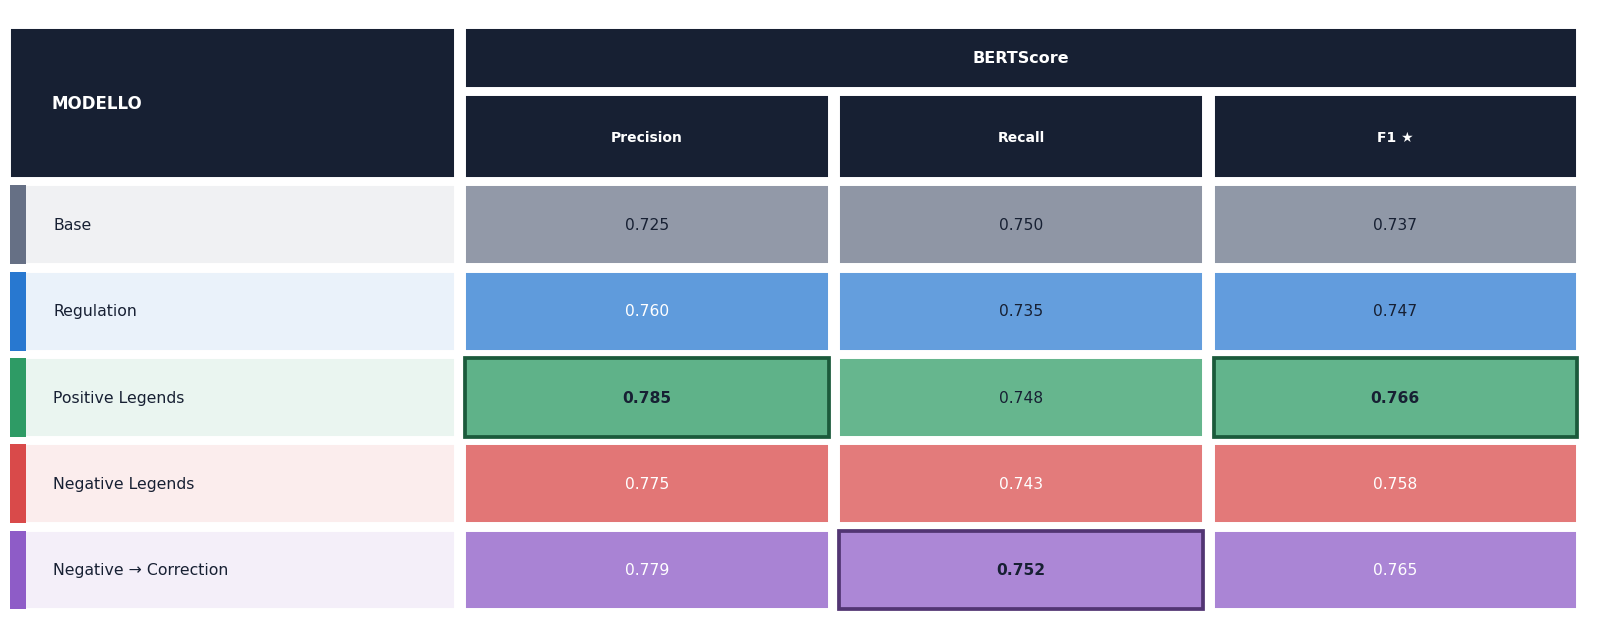

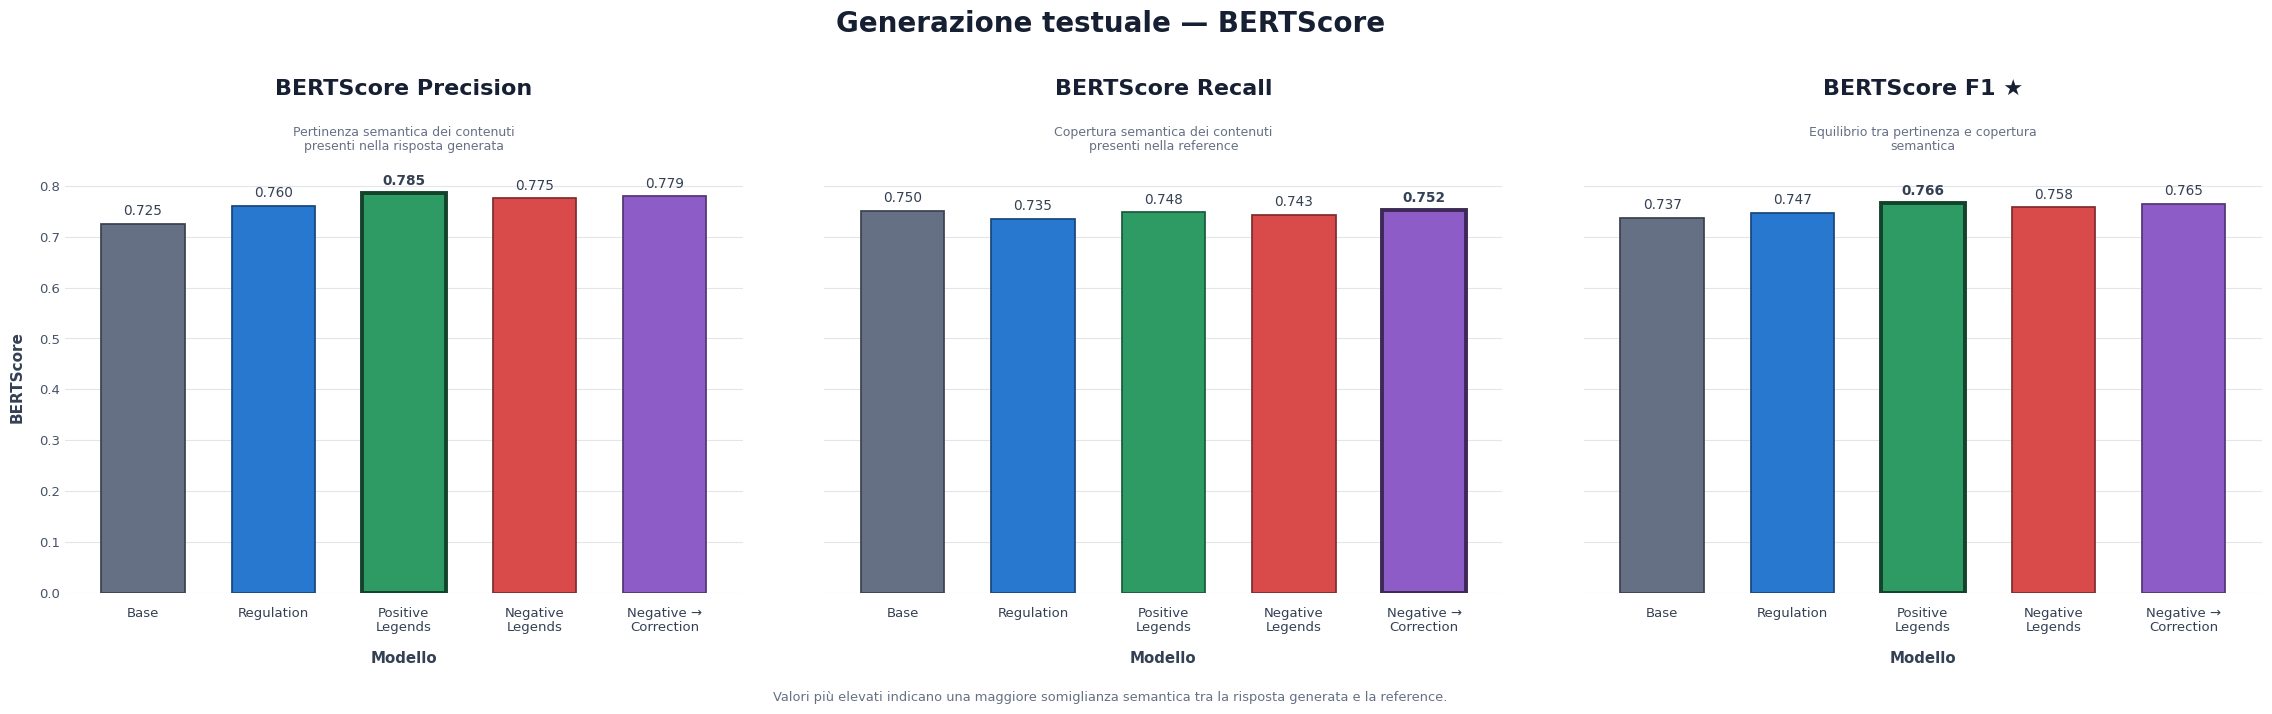

In [620]:
# CELLA 31 — Analisi delle sole metriche BERTScore.
#
# Produce:
# 1. matrice standard BERTScore;
# 2. tre grafici separati e affiancati:
#    - BERTScore Precision;
#    - BERTScore Recall;
#    - BERTScore F1;
# 3. tabella CSV delle metriche BERTScore.
#
# BLEU e ROUGE restano nelle rispettive celle dedicate.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import colors as mcolors
from matplotlib.patches import Rectangle


# =====================================================================
# PREPARAZIONE E VALIDAZIONE
# =====================================================================

required_bertscore_columns = {
    "model_name",
    "mean_bertscore_precision",
    "mean_bertscore_recall",
    "mean_bertscore_f1",
}


missing_bertscore_columns = (
    required_bertscore_columns
    - set(
        generation_metrics_table_df.columns
    )
)


if missing_bertscore_columns:
    raise RuntimeError(
        "Nella tabella generativa mancano le colonne BERTScore: "
        f"{sorted(missing_bertscore_columns)}"
    )


generation_bertscore_df = (
    generation_metrics_table_df[
        [
            "model_name",
            "mean_bertscore_precision",
            "mean_bertscore_recall",
            "mean_bertscore_f1",
        ]
    ]
    .copy()
    .set_index(
        "model_name"
    )
    .reindex(
        MODEL_ORDER
    )
    .reset_index()
)


bertscore_numeric_columns = [
    "mean_bertscore_precision",
    "mean_bertscore_recall",
    "mean_bertscore_f1",
]


for column_name in bertscore_numeric_columns:
    generation_bertscore_df[
        column_name
    ] = pd.to_numeric(
        generation_bertscore_df[
            column_name
        ],
        errors="raise",
    )


if generation_bertscore_df.isna().any().any():
    raise RuntimeError(
        "La tabella BERTScore contiene valori mancanti."
    )


values_outside_range = (
    (
        generation_bertscore_df[
            bertscore_numeric_columns
        ]
        < 0.0
    )
    |
    (
        generation_bertscore_df[
            bertscore_numeric_columns
        ]
        > 1.0
    )
)


if values_outside_range.any().any():
    raise RuntimeError(
        "Sono presenti valori BERTScore fuori dall'intervallo 0–1."
    )


generation_bertscore_df.to_csv(
    BLOCK_2_TABLES_DIR
    / "generation_bertscore_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)


display(
    generation_bertscore_df.round(
        4
    )
)


# =====================================================================
# FUNZIONI GRAFICHE LOCALI
# =====================================================================

def bertscore_blend_colors(
    background_color: str,
    foreground_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """
    Miscela il colore del modello con il colore di sfondo.
    """

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )


    background_rgb = np.asarray(
        mcolors.to_rgb(
            background_color
        )
    )


    foreground_rgb = np.asarray(
        mcolors.to_rgb(
            foreground_color
        )
    )


    return tuple(
        background_rgb
        * (
            1.0
            - amount
        )
        + foreground_rgb
        * amount
    )


def bertscore_contrast_text_color(
    background_color,
) -> str:
    """
    Restituisce testo bianco oppure blu scuro
    in base alla luminosità dello sfondo.
    """

    red, green, blue = mcolors.to_rgb(
        background_color
    )


    luminance = (
        0.2126
        * red
        + 0.7152
        * green
        + 0.0722
        * blue
    )


    if luminance >= 0.58:
        return "#172033"

    return "white"


# =====================================================================
# MATRICE BERTSCORE NEL TEMPLATE STANDARD
# =====================================================================

def plot_standard_bertscore_matrix(
    dataframe: pd.DataFrame,
    output_path,
):
    """
    Genera la matrice standard delle sole metriche BERTScore.
    """

    matrix_columns = [
        "mean_bertscore_precision",
        "mean_bertscore_recall",
        "mean_bertscore_f1",
    ]


    matrix_dataframe = (
        dataframe
        .set_index(
            "model_name"
        )
        .reindex(
            MODEL_ORDER
        )[
            matrix_columns
        ]
        .copy()
    )


    metric_labels = {
        "mean_bertscore_precision": (
            "Precision"
        ),

        "mean_bertscore_recall": (
            "Recall"
        ),

        "mean_bertscore_f1": (
            "F1 ★"
        ),
    }


    raw_values = (
        matrix_dataframe
        .to_numpy(
            dtype=float
        )
    )


    number_of_models = len(
        matrix_dataframe.index
    )


    number_of_metrics = len(
        matrix_dataframe.columns
    )


    # =================================================================
    # DIMENSIONI SIMMETRICHE
    # =================================================================

    model_column_width = 4.20

    # Tutte le metriche hanno la stessa larghezza.
    metric_column_width = 3.45

    horizontal_gap = 0.10
    vertical_gap = 0.08

    row_height = 0.92

    group_header_height = 0.72
    metric_header_height = 0.96

    complete_header_height = (
        group_header_height
        + metric_header_height
    )

    bottom_margin = 0.22
    top_margin = 0.12


    total_width = (
        model_column_width
        + number_of_metrics
        * metric_column_width
    )


    total_height = (
        bottom_margin
        + number_of_models
        * row_height
        + complete_header_height
        + top_margin
    )


    figure, axis = plt.subplots(
        figsize=(
            16.0,
            6.4,
        )
    )


    figure.patch.set_facecolor(
        "white"
    )


    axis.set_facecolor(
        "white"
    )


    axis.set_xlim(
        0,
        total_width,
    )


    axis.set_ylim(
        0,
        total_height,
    )


    axis.axis(
        "off"
    )


    rows_bottom = bottom_margin


    header_bottom = (
        rows_bottom
        + number_of_models
        * row_height
    )


    metric_header_bottom = (
        header_bottom
    )


    group_header_bottom = (
        metric_header_bottom
        + metric_header_height
    )


    header_color = "#172033"


    # =================================================================
    # HEADER MODELLO
    # =================================================================

    axis.add_patch(
        Rectangle(
            xy=(
                0,
                header_bottom,
            ),

            width=(
                model_column_width
                - horizontal_gap
            ),

            height=(
                complete_header_height
                - vertical_gap
            ),

            facecolor=header_color,

            edgecolor="white",

            linewidth=1.4,
        )
    )


    axis.text(
        0.38,

        header_bottom
        + (
            complete_header_height
            - vertical_gap
        )
        / 2,

        "MODELLO",

        ha="left",

        va="center",

        fontsize=12,

        fontweight="bold",

        color="white",
    )


    # =================================================================
    # HEADER SUPERIORE BERTSCORE
    # =================================================================

    bertscore_group_x = (
        model_column_width
    )


    bertscore_group_width = (
        number_of_metrics
        * metric_column_width
        - horizontal_gap
    )


    axis.add_patch(
        Rectangle(
            xy=(
                bertscore_group_x,
                group_header_bottom,
            ),

            width=bertscore_group_width,

            height=(
                group_header_height
                - vertical_gap
            ),

            facecolor=header_color,

            edgecolor="white",

            linewidth=1.4,
        )
    )


    axis.text(
        bertscore_group_x
        + bertscore_group_width
        / 2,

        group_header_bottom
        + (
            group_header_height
            - vertical_gap
        )
        / 2,

        "BERTScore",

        ha="center",

        va="center",

        fontsize=11.5,

        fontweight="bold",

        color="white",
    )


    # =================================================================
    # HEADER DELLE TRE METRICHE
    # =================================================================

    for column_index, column_name in enumerate(
        matrix_dataframe.columns
    ):
        cell_x = (
            model_column_width
            + column_index
            * metric_column_width
        )


        cell_width = (
            metric_column_width
            - horizontal_gap
        )


        axis.add_patch(
            Rectangle(
                xy=(
                    cell_x,
                    metric_header_bottom,
                ),

                width=cell_width,

                height=(
                    metric_header_height
                    - vertical_gap
                ),

                facecolor=header_color,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,

            metric_header_bottom
            + (
                metric_header_height
                - vertical_gap
            )
            / 2,

            metric_labels[
                column_name
            ],

            ha="center",

            va="center",

            fontsize=10,

            fontweight="bold",

            color="white",

            multialignment="center",
        )


    # =================================================================
    # RIGHE DEI MODELLI
    # =================================================================

    for row_index, model_name in enumerate(
        matrix_dataframe.index
    ):
        row_bottom = (
            rows_bottom
            + (
                number_of_models
                - 1
                - row_index
            )
            * row_height
        )


        model_color = MODEL_COLORS[
            model_name
        ]


        model_name_background = (
            bertscore_blend_colors(
                background_color="#FFFFFF",

                foreground_color=model_color,

                amount=0.10,
            )
        )


        # -------------------------------------------------------------
        # Colonna modello
        # -------------------------------------------------------------

        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=(
                    model_column_width
                    - horizontal_gap
                ),

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_name_background,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=0.15,

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_color,

                edgecolor="none",
            )
        )


        axis.text(
            0.40,

            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,

            MODEL_DISPLAY_NAMES[
                model_name
            ],

            ha="left",

            va="center",

            fontsize=11.3,

            fontweight="medium",

            color="#172033",
        )


        # -------------------------------------------------------------
        # Celle numeriche
        # -------------------------------------------------------------

        for column_index, column_name in enumerate(
            matrix_dataframe.columns
        ):
            cell_x = (
                model_column_width
                + column_index
                * metric_column_width
            )


            cell_width = (
                metric_column_width
                - horizontal_gap
            )


            raw_value = float(
                raw_values[
                    row_index,
                    column_index,
                ]
            )


            # Scala assoluta BERTScore 0–1.
            normalized_value = float(
                np.clip(
                    raw_value,
                    0.0,
                    1.0,
                )
            )


            color_strength = (
                0.06
                + 0.90
                * normalized_value
            )


            cell_facecolor = (
                bertscore_blend_colors(
                    background_color="#FFFFFF",

                    foreground_color=model_color,

                    amount=color_strength,
                )
            )


            best_models = get_best_models(
                matrix_dataframe[
                    column_name
                ],

                "higher",
            )


            is_best_model = (
                model_name
                in best_models
            )


            if is_best_model:
                cell_edgecolor = darken_color(
                    model_color,
                    0.42,
                )

                cell_linewidth = 2.7

            else:
                cell_edgecolor = "white"
                cell_linewidth = 1.4


            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        row_bottom,
                    ),

                    width=cell_width,

                    height=(
                        row_height
                        - vertical_gap
                    ),

                    facecolor=cell_facecolor,

                    edgecolor=cell_edgecolor,

                    linewidth=cell_linewidth,
                )
            )


            axis.text(
                cell_x
                + cell_width
                / 2,

                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                / 2,

                f"{raw_value:.3f}",

                ha="center",

                va="center",

                fontsize=11.2,

                fontweight=(
                    "bold"
                    if is_best_model
                    else "normal"
                ),

                color=(
                    bertscore_contrast_text_color(
                        cell_facecolor
                    )
                ),
            )


    figure.subplots_adjust(
        left=0.010,
        right=0.996,
        top=0.985,
        bottom=0.015,
    )


    save_figure(
        figure=figure,

        output_path=output_path,
    )


plot_standard_bertscore_matrix(
    dataframe=generation_bertscore_df,

    output_path=(
        GENERATION_PLOTS_DIR
        / "03_generation_bertscore_matrix.png"
    ),
)


# =====================================================================
# TRE GRAFICI BERTSCORE SEPARATI
# =====================================================================

bertscore_plot_df = (
    generation_bertscore_df
    .set_index(
        "model_name"
    )
    .reindex(
        MODEL_ORDER
    )
)


model_axis_labels = {
    "base": "Base",

    "regulation": "Regulation",

    "positive_legends": (
        "Positive\nLegends"
    ),

    "negative_legends": (
        "Negative\nLegends"
    ),

    "negative_to_correction": (
        "Negative →\nCorrection"
    ),
}


x_positions = np.arange(
    len(
        MODEL_ORDER
    )
)


precision_values = (
    bertscore_plot_df[
        "mean_bertscore_precision"
    ]
    .to_numpy(
        dtype=float
    )
)


recall_values = (
    bertscore_plot_df[
        "mean_bertscore_recall"
    ]
    .to_numpy(
        dtype=float
    )
)


f1_values = (
    bertscore_plot_df[
        "mean_bertscore_f1"
    ]
    .to_numpy(
        dtype=float
    )
)


maximum_bertscore_value = float(
    max(
        precision_values.max(),
        recall_values.max(),
        f1_values.max(),
    )
)


# I tre pannelli condividono la stessa scala assoluta.
y_axis_maximum = min(
    1.0,

    max(
        0.10,
        maximum_bertscore_value
        * 1.08,
    ),
)


figure, axes = plt.subplots(
    nrows=1,
    ncols=3,

    figsize=(
        23.5,
        7.2,
    ),

    sharey=True,
)


figure.patch.set_facecolor(
    "white"
)


bertscore_panel_definitions = [
    {
        "axis": axes[
            0
        ],

        "column": (
            "mean_bertscore_precision"
        ),

        "values": precision_values,

        "title": (
            "BERTScore Precision"
        ),

        "description": (
            "Pertinenza semantica dei contenuti\n"
            "presenti nella risposta generata"
        ),
    },

    {
        "axis": axes[
            1
        ],

        "column": (
            "mean_bertscore_recall"
        ),

        "values": recall_values,

        "title": (
            "BERTScore Recall"
        ),

        "description": (
            "Copertura semantica dei contenuti\n"
            "presenti nella reference"
        ),
    },

    {
        "axis": axes[
            2
        ],

        "column": (
            "mean_bertscore_f1"
        ),

        "values": f1_values,

        "title": (
            "BERTScore F1 ★"
        ),

        "description": (
            "Equilibrio tra pertinenza e copertura\n"
            "semantica"
        ),
    },
]


for panel_definition in bertscore_panel_definitions:
    axis = panel_definition[
        "axis"
    ]


    metric_column = panel_definition[
        "column"
    ]


    metric_values = panel_definition[
        "values"
    ]


    best_models = get_best_models(
        bertscore_plot_df[
            metric_column
        ],

        "higher",
    )


    bar_colors = [
        MODEL_COLORS[
            model_name
        ]
        for model_name
        in MODEL_ORDER
    ]


    bar_edges = [
        darken_color(
            MODEL_COLORS[
                model_name
            ],

            0.42,
        )
        for model_name
        in MODEL_ORDER
    ]


    bars = axis.bar(
        x_positions,
        metric_values,

        width=0.64,

        color=bar_colors,

        edgecolor=bar_edges,

        linewidth=1.25,

        zorder=3,
    )


    value_label_offset = (
        y_axis_maximum
        * 0.013
    )


    for (
        bar,
        model_name,
        metric_value,
    ) in zip(
        bars,
        MODEL_ORDER,
        metric_values,
    ):
        is_best_model = (
            model_name
            in best_models
        )


        if is_best_model:
            bar.set_linewidth(
                2.8
            )


            bar.set_edgecolor(
                darken_color(
                    MODEL_COLORS[
                        model_name
                    ],

                    0.57,
                )
            )


        axis.text(
            bar.get_x()
            + bar.get_width()
            / 2,

            metric_value
            + value_label_offset,

            f"{metric_value:.3f}",

            ha="center",

            va="bottom",

            fontsize=9.8,

            fontweight=(
                "bold"
                if is_best_model
                else "normal"
            ),

            color="#344054",

            zorder=5,
        )


    axis.set_xticks(
        x_positions
    )


    axis.set_xticklabels(
        [
            model_axis_labels[
                model_name
            ]
            for model_name
            in MODEL_ORDER
        ],

        rotation=0,

        ha="center",

        fontsize=9.5,

        fontweight="medium",

        color="#344054",

        linespacing=1.10,
    )


    axis.set_xlim(
        -0.60,
        len(
            MODEL_ORDER
        )
        - 0.40,
    )


    axis.set_ylim(
        0.0,
        y_axis_maximum,
    )


    axis.set_xlabel(
        "Modello",

        fontsize=10.8,

        fontweight="bold",

        color="#344054",

        labelpad=12,
    )


    axis.set_title(
        panel_definition[
            "title"
        ],

        fontsize=16,

        fontweight="bold",

        color="#172033",

        pad=48,
    )


    axis.text(
        0.5,
        1.02,

        panel_definition[
            "description"
        ],

        transform=axis.transAxes,

        ha="center",

        va="bottom",

        fontsize=9.0,

        color="#667085",

        linespacing=1.10,
    )


    axis.grid(
        axis="y",

        color="#D9DEE5",

        linewidth=0.8,

        alpha=0.75,
    )


    axis.set_axisbelow(
        True
    )


    axis.tick_params(
        axis="x",

        length=0,

        pad=10,
    )


    axis.tick_params(
        axis="y",

        length=0,

        colors="#475467",
    )


    for spine in axis.spines.values():
        spine.set_visible(
            False
        )


axes[
    0
].set_ylabel(
    "BERTScore",

    fontsize=11,

    fontweight="bold",

    color="#344054",

    labelpad=10,
)


figure.suptitle(
    "Generazione testuale — BERTScore",

    fontsize=20,

    fontweight="bold",

    color="#172033",

    y=0.98,
)


figure.text(
    0.5,
    0.025,

    (
        "Valori più elevati indicano una maggiore somiglianza "
        "semantica tra la risposta generata e la reference."
    ),

    ha="center",

    va="center",

    fontsize=9.4,

    color="#667085",
)


figure.subplots_adjust(
    left=0.055,
    right=0.990,
    top=0.77,
    bottom=0.17,
    wspace=0.12,
)


save_figure(
    figure=figure,

    output_path=(
        GENERATION_PLOTS_DIR
        / "03_generation_bertscore.png"
    ),
)

## 3.4 — Valutazione soggettiva A/B

La valutazione soggettiva usa due punteggi interi da 0 a 5:

- `valutazione_A`;
- `valutazione_B`.

Per ogni risposta viene calcolata la media A/B.

La cella di caricamento riconosce automaticamente file XLSX e ODS, anche quando l’estensione non coincide con il contenuto reale del file.

In [607]:
# CELLA 35 — Individua e carica il file soggettivo XLSX, ODS o CSV.
# Se necessario installa automaticamente openpyxl o odfpy
# nell'ambiente Python effettivamente usato dal notebook.

SUBJECTIVE_FILE_CANDIDATES = [
    (
        METRICS_DIR
        / "subjective_evaluation_completed.xlsx"
    ),

    (
        METRICS_DIR
        / "subjective_evaluation_completed.ods"
    ),

    (
        METRICS_DIR
        / "subjective_evaluation_completed.csv"
    ),

    (
        METRICS_DIR
        / "subjective_evaluation_to_complete.xlsx"
    ),

    (
        METRICS_DIR
        / "subjective_evaluation_to_complete.ods"
    ),

    (
        METRICS_DIR
        / "subjective_evaluation_to_complete.csv"
    ),
]


def ensure_optional_dependency(
    import_name: str,
    pip_name: str,
):
    """
    Importa una dipendenza opzionale
    e prova a installarla quando manca.
    """

    if find_spec(
        import_name
    ) is not None:
        return

    if not AUTO_INSTALL_OPTIONAL_DEPENDENCIES:
        raise ModuleNotFoundError(
            f"Dipendenza mancante: {pip_name}. "
            f"Installa con: "
            f"{sys.executable} -m pip install {pip_name}"
        )

    print(
        "Installazione automatica della dipendenza opzionale:",
        pip_name,
    )

    try:
        subprocess.check_call([
            sys.executable,
            "-m",
            "pip",
            "install",
            pip_name,
        ])

        importlib.invalidate_caches()

    except Exception as installation_error:
        raise ModuleNotFoundError(
            f"Impossibile installare automaticamente {pip_name}. "
            f"Esegui manualmente: "
            f"{sys.executable} -m pip install {pip_name}"
        ) from installation_error


def detect_spreadsheet_format(
    file_path: Path,
) -> str:
    """
    Riconosce XLSX o ODS dal contenuto del file,
    non soltanto dall'estensione.
    """

    file_path = Path(
        file_path
    )

    if (
        file_path.suffix.lower()
        == ".csv"
    ):
        return "csv"

    if not zipfile.is_zipfile(
        file_path
    ):
        raise RuntimeError(
            "Il file soggettivo non è un CSV né "
            "un archivio XLSX/ODS valido: "
            f"{file_path}"
        )

    with zipfile.ZipFile(
        file_path
    ) as archive:
        archive_names = set(
            archive.namelist()
        )

        if "mimetype" in archive_names:
            mime_type = (
                archive.read(
                    "mimetype"
                )
                .decode(
                    "utf-8",
                    errors="ignore",
                )
            )

            if (
                "opendocument.spreadsheet"
                in mime_type
            ):
                return "ods"

        if (
            "[Content_Types].xml"
            in archive_names
        ):
            return "xlsx"

    raise RuntimeError(
        "Formato spreadsheet non riconosciuto: "
        f"{file_path}"
    )


def read_subjective_table(
    file_path: Path,
) -> tuple[
    pd.DataFrame,
    str,
    str,
]:
    """
    Legge il file soggettivo
    usando il motore corretto.
    """

    detected_format = (
        detect_spreadsheet_format(
            file_path
        )
    )

    if detected_format == "csv":
        dataframe = pd.read_csv(
            file_path
        )

        return (
            dataframe,
            "CSV",
            "csv",
        )

    if detected_format == "xlsx":
        ensure_optional_dependency(
            "openpyxl",
            "openpyxl",
        )

        engine = "openpyxl"

    elif detected_format == "ods":
        ensure_optional_dependency(
            "odf",
            "odfpy",
        )

        engine = "odf"

    else:
        raise RuntimeError(
            f"Formato non supportato: {detected_format}"
        )

    excel_file = pd.ExcelFile(
        file_path,
        engine=engine,
    )

    sheet_name = (
        "Valutazioni"
        if "Valutazioni"
        in excel_file.sheet_names
        else excel_file.sheet_names[
            0
        ]
    )

    dataframe = pd.read_excel(
        excel_file,
        sheet_name=sheet_name,
    )

    return (
        dataframe,
        sheet_name,
        detected_format,
    )


subjective_file_path = next(
    (
        candidate_path
        for candidate_path
        in SUBJECTIVE_FILE_CANDIDATES
        if candidate_path.exists()
    ),
    None,
)


subjective_available = False

subjective_evaluation_df = (
    pd.DataFrame()
)

subjective_status_df = (
    pd.DataFrame()
)


if subjective_file_path is None:
    warnings.warn(
        "Nessun file di valutazione soggettiva trovato. "
        "Le celle soggettive verranno saltate."
    )

else:
    (
        subjective_evaluation_df,
        subjective_sheet_name,
        subjective_format,
    ) = read_subjective_table(
        subjective_file_path
    )

    subjective_evaluation_df.columns = [
        str(
            column_name
        ).strip()
        for column_name
        in subjective_evaluation_df.columns
    ]

    required_subjective_columns = {
        "model_name",
        "example_id",
        "valutazione_A",
        "valutazione_B",
    }

    missing_subjective_columns = (
        required_subjective_columns
        - set(
            subjective_evaluation_df.columns
        )
    )

    if missing_subjective_columns:
        raise RuntimeError(
            "Nel file soggettivo mancano le colonne "
            f"{sorted(missing_subjective_columns)}"
        )

    subjective_evaluation_df[
        "model_name"
    ] = (
        subjective_evaluation_df[
            "model_name"
        ]
        .astype(str)
        .str.strip()
    )

    for column_name in [
        "valutazione_A",
        "valutazione_B",
    ]:
        subjective_evaluation_df[
            column_name
        ] = pd.to_numeric(
            subjective_evaluation_df[
                column_name
            ],
            errors="coerce",
        )

    completed_both = int(
        (
            subjective_evaluation_df[
                "valutazione_A"
            ].notna()
            &
            subjective_evaluation_df[
                "valutazione_B"
            ].notna()
        ).sum()
    )

    available_scores = pd.concat(
        [
            subjective_evaluation_df[
                "valutazione_A"
            ],

            subjective_evaluation_df[
                "valutazione_B"
            ],
        ],
        ignore_index=True,
    ).dropna()

    if (
        (
            available_scores
            < 0
        )
        |
        (
            available_scores
            > 5
        )
    ).any():
        raise RuntimeError(
            "Sono presenti valutazioni soggettive "
            "fuori dall'intervallo 0–5."
        )

    if (
        (
            available_scores
            % 1
        )
        != 0
    ).any():
        raise RuntimeError(
            "Le valutazioni A e B devono essere valori interi."
        )

    actual_models = set(
        subjective_evaluation_df[
            "model_name"
        ]
    )

    subjective_available = (
        len(
            subjective_evaluation_df
        )
        == EXPECTED_GENERATION_ROWS
        and completed_both
        == EXPECTED_GENERATION_ROWS
        and actual_models
        == set(
            MODEL_ORDER
        )
    )

    subjective_status_df = pd.DataFrame([
        {
            "file": str(
                subjective_file_path
            ),

            "format": (
                subjective_format
            ),

            "sheet": (
                subjective_sheet_name
            ),

            "total_rows": len(
                subjective_evaluation_df
            ),

            "completed_both": (
                completed_both
            ),

            "expected_rows": (
                EXPECTED_GENERATION_ROWS
            ),

            "subjective_available": (
                subjective_available
            ),
        }
    ])

    if not subjective_available:
        warnings.warn(
            "La valutazione soggettiva è presente ma incompleta. "
            "Le relative visualizzazioni verranno saltate."
        )


print(
    "File soggettivo selezionato:",
    subjective_file_path,
)

print(
    "Valutazione soggettiva completa:",
    subjective_available,
)

display(
    subjective_status_df
)

File soggettivo selezionato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\metrics\subjective_evaluation_to_complete.xlsx
Valutazione soggettiva completa: True


,file,format,sheet,total_rows,completed_both,expected_rows,subjective_available
0,C:\Users\ab161\Desktop\Visualizzazioni Progett...,ods,Valutazioni,100,100,100,True


In [608]:
# CELLA 36 — Calcola statistiche per risposta, statistiche per modello,
# accordo tra valutatori e ranking soggettivo della generazione.

subjective_by_example_df = (
    pd.DataFrame()
)

subjective_by_model_df = (
    pd.DataFrame()
)

subjective_agreement_df = (
    pd.DataFrame()
)

subjective_generation_ranking_df = (
    pd.DataFrame()
)


if subjective_available:
    subjective_by_example_df = (
        subjective_evaluation_df
        .copy()
    )

    subjective_by_example_df[
        "subjective_mean_score"
    ] = (
        subjective_by_example_df[
            "valutazione_A"
        ]
        + subjective_by_example_df[
            "valutazione_B"
        ]
    ) / 2

    subjective_by_example_df[
        "evaluator_absolute_difference"
    ] = (
        subjective_by_example_df[
            "valutazione_A"
        ]
        - subjective_by_example_df[
            "valutazione_B"
        ]
    ).abs()

    subjective_by_model_df = (
        subjective_by_example_df
        .groupby(
            "model_name",
            as_index=False,
        )
        .agg(
            n_answers=(
                "example_id",
                "count",
            ),

            mean_evaluation_A=(
                "valutazione_A",
                "mean",
            ),

            mean_evaluation_B=(
                "valutazione_B",
                "mean",
            ),

            mean_subjective_score=(
                "subjective_mean_score",
                "mean",
            ),

            median_subjective_score=(
                "subjective_mean_score",
                "median",
            ),

            std_subjective_score=(
                "subjective_mean_score",
                "std",
            ),

            exact_agreement_rate=(
                "evaluator_absolute_difference",
                lambda values: float(
                    (
                        values
                        == 0
                    ).mean()
                ),
            ),

            within_one_point_rate=(
                "evaluator_absolute_difference",
                lambda values: float(
                    (
                        values
                        <= 1
                    ).mean()
                ),
            ),

            mean_absolute_difference=(
                "evaluator_absolute_difference",
                "mean",
            ),
        )
    )

    subjective_by_model_df = sort_models(
        subjective_by_model_df
    )

    weighted_kappa = float(
        cohen_kappa_score(
            subjective_by_example_df[
                "valutazione_A"
            ],
            subjective_by_example_df[
                "valutazione_B"
            ],
            weights="quadratic",
        )
    )

    subjective_agreement_df = pd.DataFrame([
        {
            "n_answers": len(
                subjective_by_example_df
            ),

            "exact_agreement_rate": float(
                (
                    subjective_by_example_df[
                        "evaluator_absolute_difference"
                    ]
                    == 0
                ).mean()
            ),

            "within_one_point_rate": float(
                (
                    subjective_by_example_df[
                        "evaluator_absolute_difference"
                    ]
                    <= 1
                ).mean()
            ),

            "mean_absolute_difference": float(
                subjective_by_example_df[
                    "evaluator_absolute_difference"
                ].mean()
            ),

            "quadratic_weighted_kappa": (
                weighted_kappa
            ),
        }
    ])

    subjective_ranking_input_df = (
        subjective_by_model_df[
            [
                "model_name",
                "mean_subjective_score",
            ]
        ]
        .rename(
            columns={
                "mean_subjective_score": (
                    "primary_score"
                )
            }
        )
    )

    subjective_ranking_input_df[
        "task_name"
    ] = GENERATION_TASK

    subjective_ranking_input_df[
        "primary_metric_name"
    ] = "mean_subjective_score"

    subjective_generation_ranking_df = (
        rank_models_for_task(
            subjective_ranking_input_df
        )
    )

    display(
        subjective_by_model_df
        .round(
            4
        )
    )

    display(
        subjective_agreement_df
        .round(
            4
        )
    )

    display(
        subjective_generation_ranking_df[
            [
                "model_name",
                "primary_score",
                "average_rank",
                "points",
                "tie_size",
            ]
        ]
        .round(
            4
        )
    )

else:
    print(
        "Analisi soggettiva saltata: "
        "file assente o incompleto."
    )

,model_name,n_answers,mean_evaluation_A,mean_evaluation_B,mean_subjective_score,median_subjective_score,std_subjective_score,exact_agreement_rate,within_one_point_rate,mean_absolute_difference
0,base,20,2.15,2.20,2.175,2.0,1.0166,0.85,0.90,0.25
1,regulation,20,2.05,2.15,2.100,2.0,0.9262,0.70,1.00,0.30
2,positive_legends,20,1.95,2.15,2.050,2.0,0.9018,0.80,0.90,0.30
3,negative_legends,20,2.00,2.20,2.100,2.0,0.5758,0.75,0.85,0.40
4,negative_to_correction,20,1.95,2.25,2.100,2.0,1.0336,0.65,0.75,0.60


,n_answers,exact_agreement_rate,within_one_point_rate,mean_absolute_difference,quadratic_weighted_kappa
0,100,0.75,0.88,0.37,0.6759


,model_name,primary_score,average_rank,points,tie_size
0,base,2.175,1.0,5.0,1
1,regulation,2.100,3.0,3.0,3
2,negative_legends,2.100,3.0,3.0,3
3,negative_to_correction,2.100,3.0,3.0,3
4,positive_legends,2.050,5.0,1.0,1


,model_name,mean_evaluation_A,mean_evaluation_B,mean_subjective_score,std_subjective_score,exact_agreement_rate,within_one_point_rate,mean_absolute_difference
0,base,2.15,2.20,2.175,1.0166,0.85,0.90,0.25
1,regulation,2.05,2.15,2.100,0.9262,0.70,1.00,0.30
2,positive_legends,1.95,2.15,2.050,0.9018,0.80,0.90,0.30
3,negative_legends,2.00,2.20,2.100,0.5758,0.75,0.85,0.40
4,negative_to_correction,1.95,2.25,2.100,1.0336,0.65,0.75,0.60


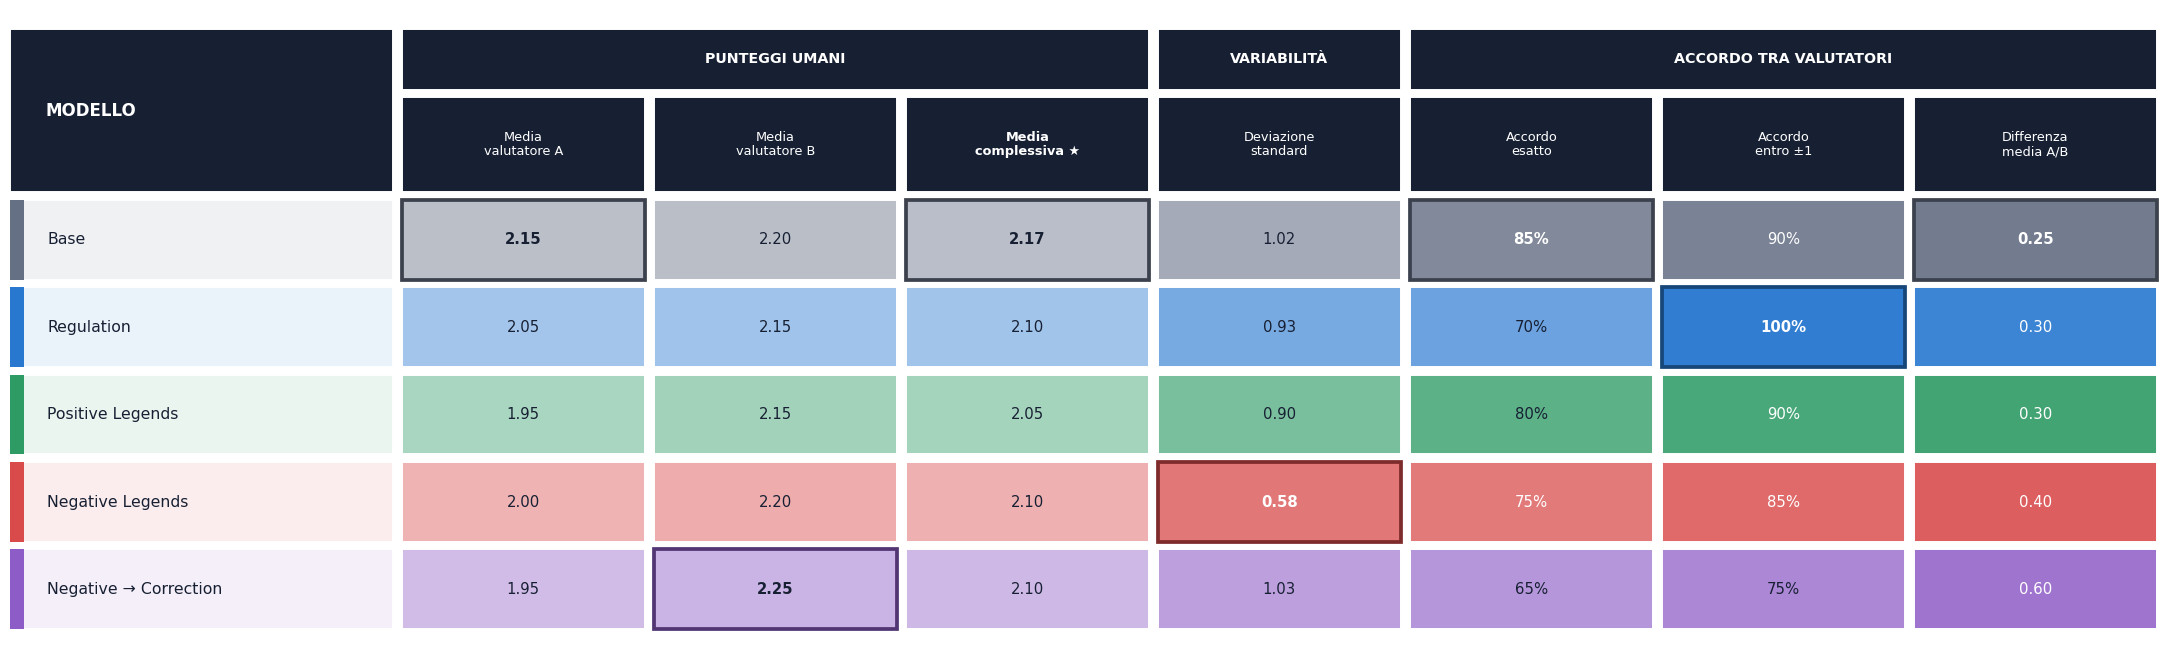

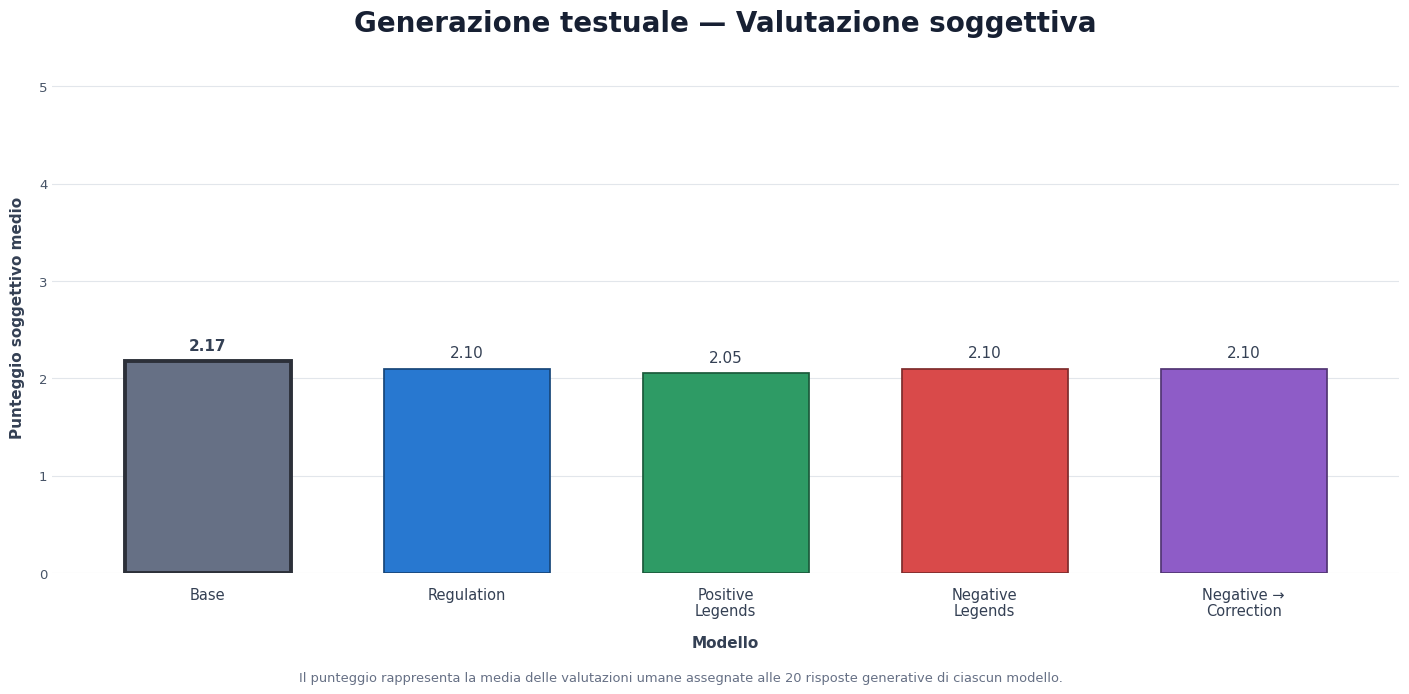

In [622]:
# CELLA 37 — Valutazione soggettiva della generazione.
#
# Produce:
# 1. matrice standard delle statistiche soggettive, senza mediana;
# 2. istogramma semplice del punteggio soggettivo medio per modello;
# 3. CSV delle statistiche soggettive.
#
# Il grafico non confronta Valutatore A e Valutatore B:
# mostra soltanto la qualità complessiva attribuita alle risposte
# generative dei cinque modelli.

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import colors as mcolors
from matplotlib.patches import Rectangle


# =====================================================================
# CONTROLLO DISPONIBILITÀ
# =====================================================================

if not subjective_available:
    warnings.warn(
        "La valutazione soggettiva non è disponibile o non è completa. "
        "La Cella 37 non produrrà output."
    )

else:

    # =================================================================
    # PREPARAZIONE E VALIDAZIONE
    # =================================================================

    required_subjective_columns = {
        "model_name",
        "mean_evaluation_A",
        "mean_evaluation_B",
        "mean_subjective_score",
        "std_subjective_score",
        "exact_agreement_rate",
        "within_one_point_rate",
        "mean_absolute_difference",
    }


    missing_subjective_columns = (
        required_subjective_columns
        - set(
            subjective_by_model_df.columns
        )
    )


    if missing_subjective_columns:
        raise RuntimeError(
            "Nella sintesi soggettiva mancano le colonne: "
            f"{sorted(missing_subjective_columns)}"
        )


    # La mediana viene esclusa intenzionalmente.
    subjective_table_columns = [
        "model_name",
        "mean_evaluation_A",
        "mean_evaluation_B",
        "mean_subjective_score",
        "std_subjective_score",
        "exact_agreement_rate",
        "within_one_point_rate",
        "mean_absolute_difference",
    ]


    subjective_table_df = (
        subjective_by_model_df[
            subjective_table_columns
        ]
        .copy()
        .set_index(
            "model_name"
        )
        .reindex(
            MODEL_ORDER
        )
        .reset_index()
    )


    numeric_subjective_columns = [
        column_name
        for column_name
        in subjective_table_columns
        if column_name != "model_name"
    ]


    for column_name in numeric_subjective_columns:
        subjective_table_df[
            column_name
        ] = pd.to_numeric(
            subjective_table_df[
                column_name
            ],
            errors="raise",
        )


    if subjective_table_df.isna().any().any():
        raise RuntimeError(
            "La tabella della valutazione soggettiva "
            "contiene valori mancanti."
        )


    subjective_table_df.to_csv(
        BLOCK_2_TABLES_DIR
        / "generation_subjective_metrics.csv",
        index=False,
        encoding="utf-8-sig",
    )


    display(
        subjective_table_df.round(
            4
        )
    )


    # =================================================================
    # FUNZIONI GRAFICHE LOCALI
    # =================================================================

    def subjective_blend_colors(
        background_color: str,
        foreground_color: str,
        amount: float,
    ) -> tuple[float, float, float]:
        """
        Miscela il colore del modello con il colore di sfondo.
        """

        amount = float(
            np.clip(
                amount,
                0.0,
                1.0,
            )
        )


        background_rgb = np.asarray(
            mcolors.to_rgb(
                background_color
            )
        )


        foreground_rgb = np.asarray(
            mcolors.to_rgb(
                foreground_color
            )
        )


        return tuple(
            background_rgb
            * (
                1.0
                - amount
            )
            + foreground_rgb
            * amount
        )


    def subjective_contrast_text_color(
        background_color,
    ) -> str:
        """
        Restituisce testo bianco oppure blu scuro
        in funzione della luminosità della cella.
        """

        red, green, blue = mcolors.to_rgb(
            background_color
        )


        luminance = (
            0.2126
            * red
            + 0.7152
            * green
            + 0.0722
            * blue
        )


        if luminance >= 0.58:
            return "#172033"

        return "white"


    def normalize_subjective_metric(
        value: float,
        lower_limit: float,
        upper_limit: float,
        direction: str,
    ) -> float:
        """
        Normalizza una metrica sulla relativa scala assoluta.
        """

        if pd.isna(
            value
        ):
            return np.nan


        if upper_limit <= lower_limit:
            raise ValueError(
                "upper_limit deve essere maggiore di lower_limit."
            )


        normalized_value = (
            float(
                value
            )
            - lower_limit
        ) / (
            upper_limit
            - lower_limit
        )


        normalized_value = float(
            np.clip(
                normalized_value,
                0.0,
                1.0,
            )
        )


        if direction == "higher":
            return normalized_value


        if direction == "lower":
            return (
                1.0
                - normalized_value
            )


        raise ValueError(
            f"Direzione non supportata: {direction}"
        )


    # =================================================================
    # MATRICE STANDARD
    # =================================================================

    def plot_standard_subjective_matrix(
        dataframe: pd.DataFrame,
        output_path,
    ):
        """
        Genera la matrice standard della valutazione soggettiva.

        La mediana non viene inclusa.
        """

        matrix_columns = [
            "mean_evaluation_A",
            "mean_evaluation_B",
            "mean_subjective_score",
            "std_subjective_score",
            "exact_agreement_rate",
            "within_one_point_rate",
            "mean_absolute_difference",
        ]


        matrix_dataframe = (
            dataframe
            .set_index(
                "model_name"
            )
            .reindex(
                MODEL_ORDER
            )[
                matrix_columns
            ]
            .copy()
        )


        metric_configuration = {
            "mean_evaluation_A": {
                "label": (
                    "Media\nvalutatore A"
                ),
                "direction": "higher",
                "limits": (
                    0.0,
                    5.0,
                ),
                "formatter": (
                    lambda value:
                    f"{value:.2f}"
                ),
            },

            "mean_evaluation_B": {
                "label": (
                    "Media\nvalutatore B"
                ),
                "direction": "higher",
                "limits": (
                    0.0,
                    5.0,
                ),
                "formatter": (
                    lambda value:
                    f"{value:.2f}"
                ),
            },

            "mean_subjective_score": {
                "label": (
                    "Media\ncomplessiva ★"
                ),
                "direction": "higher",
                "limits": (
                    0.0,
                    5.0,
                ),
                "formatter": (
                    lambda value:
                    f"{value:.2f}"
                ),
            },

            "std_subjective_score": {
                "label": (
                    "Deviazione\nstandard"
                ),
                "direction": "lower",
                "limits": (
                    0.0,
                    2.5,
                ),
                "formatter": (
                    lambda value:
                    f"{value:.2f}"
                ),
            },

            "exact_agreement_rate": {
                "label": (
                    "Accordo\nesatto"
                ),
                "direction": "higher",
                "limits": (
                    0.0,
                    1.0,
                ),
                "formatter": (
                    lambda value:
                    f"{value * 100:.0f}%"
                ),
            },

            "within_one_point_rate": {
                "label": (
                    "Accordo\nentro ±1"
                ),
                "direction": "higher",
                "limits": (
                    0.0,
                    1.0,
                ),
                "formatter": (
                    lambda value:
                    f"{value * 100:.0f}%"
                ),
            },

            "mean_absolute_difference": {
                "label": (
                    "Differenza\nmedia A/B"
                ),
                "direction": "lower",
                "limits": (
                    0.0,
                    5.0,
                ),
                "formatter": (
                    lambda value:
                    f"{value:.2f}"
                ),
            },
        }


        metric_groups = [
            {
                "label": "PUNTEGGI UMANI",
                "start_index": 0,
                "number_of_columns": 3,
            },

            {
                "label": "VARIABILITÀ",
                "start_index": 3,
                "number_of_columns": 1,
            },

            {
                "label": "ACCORDO TRA VALUTATORI",
                "start_index": 4,
                "number_of_columns": 3,
            },
        ]


        raw_values = (
            matrix_dataframe
            .to_numpy(
                dtype=float
            )
        )


        number_of_models = len(
            matrix_dataframe.index
        )


        number_of_metrics = len(
            matrix_dataframe.columns
        )


        normalized_values = np.full_like(
            raw_values,
            np.nan,
            dtype=float,
        )


        for column_index, column_name in enumerate(
            matrix_dataframe.columns
        ):
            configuration = metric_configuration[
                column_name
            ]


            lower_limit, upper_limit = configuration[
                "limits"
            ]


            for row_index in range(
                number_of_models
            ):
                normalized_values[
                    row_index,
                    column_index,
                ] = normalize_subjective_metric(
                    value=raw_values[
                        row_index,
                        column_index,
                    ],
                    lower_limit=lower_limit,
                    upper_limit=upper_limit,
                    direction=configuration[
                        "direction"
                    ],
                )


        # =============================================================
        # DIMENSIONI
        # =============================================================

        model_column_width = 4.20

        metric_column_width = 2.70

        horizontal_gap = 0.10
        vertical_gap = 0.08

        row_height = 0.92

        group_header_height = 0.72
        metric_header_height = 1.08

        complete_header_height = (
            group_header_height
            + metric_header_height
        )

        bottom_margin = 0.22
        top_margin = 0.12


        total_width = (
            model_column_width
            + number_of_metrics
            * metric_column_width
        )


        total_height = (
            bottom_margin
            + number_of_models
            * row_height
            + complete_header_height
            + top_margin
        )


        figure, axis = plt.subplots(
            figsize=(
                21.8,
                6.6,
            )
        )


        figure.patch.set_facecolor(
            "white"
        )


        axis.set_facecolor(
            "white"
        )


        axis.set_xlim(
            0,
            total_width,
        )


        axis.set_ylim(
            0,
            total_height,
        )


        axis.axis(
            "off"
        )


        rows_bottom = bottom_margin


        header_bottom = (
            rows_bottom
            + number_of_models
            * row_height
        )


        metric_header_bottom = (
            header_bottom
        )


        group_header_bottom = (
            metric_header_bottom
            + metric_header_height
        )


        header_color = "#172033"


        # =============================================================
        # HEADER MODELLO
        # =============================================================

        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    header_bottom,
                ),
                width=(
                    model_column_width
                    - horizontal_gap
                ),
                height=(
                    complete_header_height
                    - vertical_gap
                ),
                facecolor=header_color,
                edgecolor="white",
                linewidth=1.4,
            )
        )


        axis.text(
            0.38,
            header_bottom
            + (
                complete_header_height
                - vertical_gap
            )
            / 2,
            "MODELLO",
            ha="left",
            va="center",
            fontsize=12,
            fontweight="bold",
            color="white",
        )


        # =============================================================
        # HEADER RAGGRUPPATI
        # =============================================================

        for metric_group in metric_groups:
            group_x = (
                model_column_width
                + metric_group[
                    "start_index"
                ]
                * metric_column_width
            )


            group_width = (
                metric_group[
                    "number_of_columns"
                ]
                * metric_column_width
                - horizontal_gap
            )


            axis.add_patch(
                Rectangle(
                    xy=(
                        group_x,
                        group_header_bottom,
                    ),
                    width=group_width,
                    height=(
                        group_header_height
                        - vertical_gap
                    ),
                    facecolor=header_color,
                    edgecolor="white",
                    linewidth=1.4,
                )
            )


            axis.text(
                group_x
                + group_width
                / 2,
                group_header_bottom
                + (
                    group_header_height
                    - vertical_gap
                )
                / 2,
                metric_group[
                    "label"
                ],
                ha="center",
                va="center",
                fontsize=10.3,
                fontweight="bold",
                color="white",
            )


        # =============================================================
        # HEADER DELLE METRICHE
        # =============================================================

        for column_index, column_name in enumerate(
            matrix_dataframe.columns
        ):
            cell_x = (
                model_column_width
                + column_index
                * metric_column_width
            )


            cell_width = (
                metric_column_width
                - horizontal_gap
            )


            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        metric_header_bottom,
                    ),
                    width=cell_width,
                    height=(
                        metric_header_height
                        - vertical_gap
                    ),
                    facecolor=header_color,
                    edgecolor="white",
                    linewidth=1.4,
                )
            )


            axis.text(
                cell_x
                + cell_width
                / 2,
                metric_header_bottom
                + (
                    metric_header_height
                    - vertical_gap
                )
                / 2,
                metric_configuration[
                    column_name
                ][
                    "label"
                ],
                ha="center",
                va="center",
                fontsize=9.3,
                fontweight=(
                    "bold"
                    if column_name
                    == "mean_subjective_score"
                    else "medium"
                ),
                color="white",
                linespacing=1.08,
                multialignment="center",
            )


        # =============================================================
        # RIGHE DEI MODELLI
        # =============================================================

        for row_index, model_name in enumerate(
            matrix_dataframe.index
        ):
            row_bottom = (
                rows_bottom
                + (
                    number_of_models
                    - 1
                    - row_index
                )
                * row_height
            )


            model_color = MODEL_COLORS[
                model_name
            ]


            model_background = (
                subjective_blend_colors(
                    background_color="#FFFFFF",
                    foreground_color=model_color,
                    amount=0.10,
                )
            )


            axis.add_patch(
                Rectangle(
                    xy=(
                        0,
                        row_bottom,
                    ),
                    width=(
                        model_column_width
                        - horizontal_gap
                    ),
                    height=(
                        row_height
                        - vertical_gap
                    ),
                    facecolor=model_background,
                    edgecolor="white",
                    linewidth=1.4,
                )
            )


            axis.add_patch(
                Rectangle(
                    xy=(
                        0,
                        row_bottom,
                    ),
                    width=0.15,
                    height=(
                        row_height
                        - vertical_gap
                    ),
                    facecolor=model_color,
                    edgecolor="none",
                )
            )


            axis.text(
                0.40,
                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                / 2,
                MODEL_DISPLAY_NAMES[
                    model_name
                ],
                ha="left",
                va="center",
                fontsize=11.3,
                fontweight="medium",
                color="#172033",
            )


            # ---------------------------------------------------------
            # CELLE NUMERICHE
            # ---------------------------------------------------------

            for column_index, column_name in enumerate(
                matrix_dataframe.columns
            ):
                cell_x = (
                    model_column_width
                    + column_index
                    * metric_column_width
                )


                cell_width = (
                    metric_column_width
                    - horizontal_gap
                )


                raw_value = float(
                    raw_values[
                        row_index,
                        column_index,
                    ]
                )


                normalized_value = float(
                    normalized_values[
                        row_index,
                        column_index,
                    ]
                )


                configuration = metric_configuration[
                    column_name
                ]


                color_strength = (
                    0.06
                    + 0.90
                    * normalized_value
                )


                cell_facecolor = (
                    subjective_blend_colors(
                        background_color="#FFFFFF",
                        foreground_color=model_color,
                        amount=color_strength,
                    )
                )


                best_models = get_best_models(
                    matrix_dataframe[
                        column_name
                    ],
                    configuration[
                        "direction"
                    ],
                )


                is_best_model = (
                    model_name
                    in best_models
                )


                if is_best_model:
                    cell_edgecolor = darken_color(
                        model_color,
                        0.42,
                    )

                    cell_linewidth = 2.7

                else:
                    cell_edgecolor = "white"
                    cell_linewidth = 1.4


                axis.add_patch(
                    Rectangle(
                        xy=(
                            cell_x,
                            row_bottom,
                        ),
                        width=cell_width,
                        height=(
                            row_height
                            - vertical_gap
                        ),
                        facecolor=cell_facecolor,
                        edgecolor=cell_edgecolor,
                        linewidth=cell_linewidth,
                    )
                )


                axis.text(
                    cell_x
                    + cell_width
                    / 2,
                    row_bottom
                    + (
                        row_height
                        - vertical_gap
                    )
                    / 2,
                    configuration[
                        "formatter"
                    ](
                        raw_value
                    ),
                    ha="center",
                    va="center",
                    fontsize=10.7,
                    fontweight=(
                        "bold"
                        if is_best_model
                        else "normal"
                    ),
                    color=(
                        subjective_contrast_text_color(
                            cell_facecolor
                        )
                    ),
                )


        figure.subplots_adjust(
            left=0.008,
            right=0.997,
            top=0.985,
            bottom=0.015,
        )


        save_figure(
            figure=figure,
            output_path=output_path,
        )


    plot_standard_subjective_matrix(
        dataframe=subjective_table_df,
        output_path=(
            GENERATION_PLOTS_DIR
            / "04_generation_subjective_matrix.png"
        ),
    )


    # =================================================================
    # ISTOGRAMMA SEMPLICE DELLA VALUTAZIONE SOGGETTIVA
    # =================================================================

    subjective_plot_df = (
        subjective_table_df
        .set_index(
            "model_name"
        )
        .reindex(
            MODEL_ORDER
        )
    )


    subjective_mean_values = (
        subjective_plot_df[
            "mean_subjective_score"
        ]
        .to_numpy(
            dtype=float
        )
    )


    best_subjective_models = get_best_models(
        subjective_plot_df[
            "mean_subjective_score"
        ],
        "higher",
    )


    model_axis_labels = {
        "base": "Base",

        "regulation": "Regulation",

        "positive_legends": (
            "Positive\nLegends"
        ),

        "negative_legends": (
            "Negative\nLegends"
        ),

        "negative_to_correction": (
            "Negative →\nCorrection"
        ),
    }


    x_positions = np.arange(
        len(
            MODEL_ORDER
        )
    )


    figure, axis = plt.subplots(
        figsize=(
            14.8,
            7.2,
        )
    )


    figure.patch.set_facecolor(
        "white"
    )


    axis.set_facecolor(
        "white"
    )


    bars = axis.bar(
        x_positions,
        subjective_mean_values,

        width=0.64,

        color=[
            MODEL_COLORS[
                model_name
            ]
            for model_name
            in MODEL_ORDER
        ],

        edgecolor=[
            darken_color(
                MODEL_COLORS[
                    model_name
                ],
                0.42,
            )
            for model_name
            in MODEL_ORDER
        ],

        linewidth=1.25,

        zorder=3,
    )


    for (
        bar,
        model_name,
        mean_value,
    ) in zip(
        bars,
        MODEL_ORDER,
        subjective_mean_values,
    ):
        is_best_model = (
            model_name
            in best_subjective_models
        )


        if is_best_model:
            bar.set_linewidth(
                2.8
            )


            bar.set_edgecolor(
                darken_color(
                    MODEL_COLORS[
                        model_name
                    ],
                    0.57,
                )
            )


        axis.text(
            bar.get_x()
            + bar.get_width()
            / 2,

            mean_value
            + 0.08,

            f"{mean_value:.2f}",

            ha="center",

            va="bottom",

            fontsize=11,

            fontweight=(
                "bold"
                if is_best_model
                else "normal"
            ),

            color="#344054",

            zorder=5,
        )


    axis.set_xticks(
        x_positions
    )


    axis.set_xticklabels(
        [
            model_axis_labels[
                model_name
            ]
            for model_name
            in MODEL_ORDER
        ],

        rotation=0,

        ha="center",

        fontsize=10.5,

        fontweight="medium",

        color="#344054",

        linespacing=1.10,
    )


    axis.set_xlim(
        -0.60,
        len(
            MODEL_ORDER
        )
        - 0.40,
    )


    # Scala completa prevista dalla valutazione.
    axis.set_ylim(
        0.0,
        5.25,
    )


    axis.set_yticks(
        [
            0,
            1,
            2,
            3,
            4,
            5,
        ]
    )


    axis.set_xlabel(
        "Modello",

        fontsize=11,

        fontweight="bold",

        color="#344054",

        labelpad=12,
    )


    axis.set_ylabel(
        "Punteggio soggettivo medio",

        fontsize=11,

        fontweight="bold",

        color="#344054",

        labelpad=10,
    )


    axis.set_title(
        "Generazione testuale — Valutazione soggettiva",

        fontsize=20,

        fontweight="bold",

        color="#172033",

        pad=22,
    )


    axis.grid(
        axis="y",

        color="#D9DEE5",

        linewidth=0.8,

        alpha=0.75,
    )


    axis.set_axisbelow(
        True
    )


    axis.tick_params(
        axis="x",

        length=0,

        pad=10,
    )


    axis.tick_params(
        axis="y",

        length=0,

        colors="#475467",
    )


    for spine in axis.spines.values():
        spine.set_visible(
            False
        )


    figure.text(
        0.5,
        0.025,

        (
            "Il punteggio rappresenta la media delle valutazioni umane "
            "assegnate alle 20 risposte generative di ciascun modello."
        ),

        ha="center",

        va="center",

        fontsize=9.4,

        color="#667085",
    )


    figure.subplots_adjust(
        left=0.075,
        right=0.985,
        top=0.88,
        bottom=0.17,
    )


    save_figure(
        figure=figure,

        output_path=(
            GENERATION_PLOTS_DIR
            / "04_generation_subjective_scores.png"
        ),
    )


    # =================================================================
    # RIMOZIONE DEI VECCHI GRAFICI
    # =================================================================

    legacy_plot_paths = [
        (
            GENERATION_PLOTS_DIR
            / "04_generation_subjective_AB.png"
        ),

        (
            GENERATION_PLOTS_DIR
            / "04_generation_subjective_comparison.png"
        ),
    ]


    for legacy_plot_path in legacy_plot_paths:
        if legacy_plot_path.exists():
            legacy_plot_path.unlink()

## Tentativi alternativi — Generazione

Le celle seguenti aggiungono viste sperimentali:

- matrice completa delle metriche automatiche;
- profilo dei rank ottenuti nelle diverse famiglie metriche;
- rapporto tra lunghezza delle risposte e BERTScore;
- distribuzione dei punteggi soggettivi.

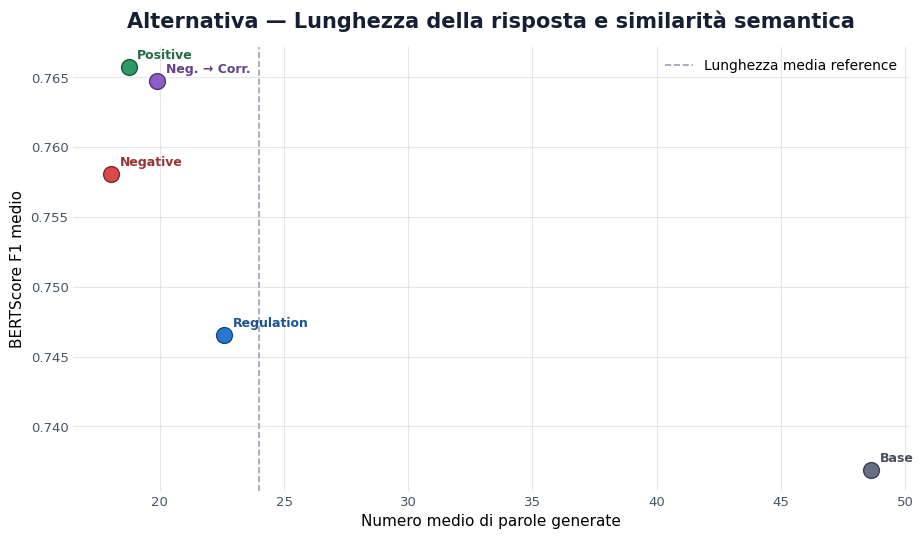

In [613]:
# CELLA 42 — ALTERNATIVA GENERAZIONE 3.
# Confronta lunghezza media generata e BERTScore F1
# quando le colonne di lunghezza sono disponibili.

length_columns_available = {
    "mean_generated_word_count",
    "mean_reference_word_count",
}.issubset(
    generation_metrics_table_df.columns
)


if length_columns_available:
    figure, axis = plt.subplots(
        figsize=(
            9.5,
            6.0,
        )
    )

    figure.patch.set_facecolor(
        "white"
    )

    for row in generation_metrics_table_df.itertuples(
        index=False
    ):
        model_name = (
            row.model_name
        )

        axis.scatter(
            row.mean_generated_word_count,
            row.mean_bertscore_f1,
            s=130,
            color=MODEL_COLORS[
                model_name
            ],
            edgecolor=darken_color(
                MODEL_COLORS[
                    model_name
                ],
                0.42,
            ),
            linewidth=1.0,
            zorder=4,
        )

        axis.annotate(
            MODEL_SHORT_NAMES[
                model_name
            ],
            (
                row.mean_generated_word_count,
                row.mean_bertscore_f1,
            ),
            xytext=(
                6,
                6,
            ),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            color=darken_color(
                MODEL_COLORS[
                    model_name
                ],
                0.30,
            ),
        )

    reference_mean = float(
        generation_metrics_table_df[
            "mean_reference_word_count"
        ].mean()
    )

    axis.axvline(
        reference_mean,
        color="#98A2B3",
        linestyle="--",
        linewidth=1.2,
        label="Lunghezza media reference",
    )

    axis.set_xlabel(
        "Numero medio di parole generate"
    )

    axis.set_ylabel(
        "BERTScore F1 medio"
    )

    axis.set_title(
        "Alternativa — Lunghezza della risposta "
        "e similarità semantica",
        color=TEXT_COLOR,
        pad=14,
    )

    axis.legend(
        frameon=False
    )

    style_axis(
        axis,
        grid_axis="both",
    )

    figure.subplots_adjust(
        left=0.10,
        right=0.98,
        top=0.88,
        bottom=0.14,
    )

    save_figure(
        figure,
        GENERATION_ALT_DIR
        / "ALT_GEN_03_length_vs_bertscore.png",
    )

else:
    print(
        "ALT_GEN_03 saltata: colonne di lunghezza "
        "non disponibili in generation_metrics_by_model.csv."
    )

# Sintesi finale del Blocco 2

La sintesi riporta le tre macro-capacità su una scala comune basata esclusivamente sui punti di ranking:

- classificazione: media dei punti sui sei task classificatori;
- similarità numerica: punti ottenuti su STS-B;
- generazione automatica: punti ottenuti tramite BERTScore F1;
- generazione soggettiva: punti ottenuti tramite media A/B, quando disponibile.

La tabella è descrittiva. Non rappresenta una media diretta tra metriche incompatibili.

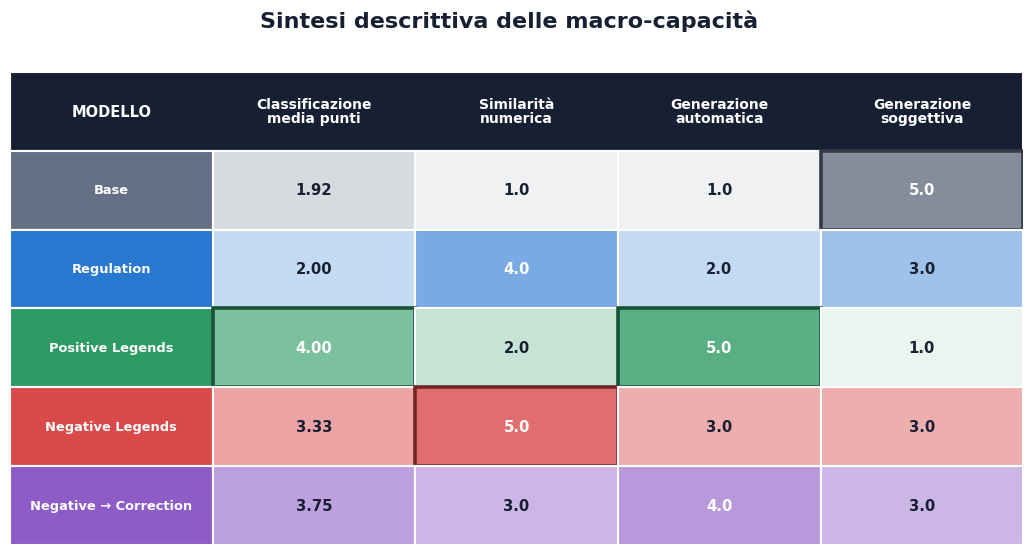

,model_name,classification,numeric,generation_automatic,generation_subjective
0,base,1.917,1.0,1.0,5.0
1,regulation,2.000,4.0,2.0,3.0
2,positive_legends,4.000,2.0,5.0,1.0
3,negative_legends,3.333,5.0,3.0,3.0
4,negative_to_correction,3.750,3.0,4.0,3.0


In [615]:
# CELLA 45 — Costruisce e visualizza
# la sintesi finale delle macro-capacità.

classification_capability_df = (
    classification_task_rankings_df
    .groupby(
        "model_name",
        as_index=False,
    )
    .agg(
        classification=(
            "points",
            "mean",
        )
    )
)


numeric_capability_df = (
    task_rankings_automatic_df[
        task_rankings_automatic_df[
            "task_name"
        ]
        == STSB_TASK
    ][
        [
            "model_name",
            "points",
        ]
    ]
    .rename(
        columns={
            "points": (
                "numeric"
            )
        }
    )
)


generation_automatic_capability_df = (
    task_rankings_automatic_df[
        task_rankings_automatic_df[
            "task_name"
        ]
        == GENERATION_TASK
    ][
        [
            "model_name",
            "points",
        ]
    ]
    .rename(
        columns={
            "points": (
                "generation_automatic"
            )
        }
    )
)


macro_capability_summary_df = (
    classification_capability_df
    .merge(
        numeric_capability_df,
        on="model_name",
        validate="one_to_one",
    )
    .merge(
        generation_automatic_capability_df,
        on="model_name",
        validate="one_to_one",
    )
)


if subjective_available:
    generation_subjective_capability_df = (
        subjective_generation_ranking_df[
            [
                "model_name",
                "points",
            ]
        ]
        .rename(
            columns={
                "points": (
                    "generation_subjective"
                )
            }
        )
    )

    macro_capability_summary_df = (
        macro_capability_summary_df
        .merge(
            generation_subjective_capability_df,
            on="model_name",
            validate="one_to_one",
        )
    )


macro_capability_summary_df = sort_models(
    macro_capability_summary_df
)


summary_metric_specs = [
    {
        "key": (
            "classification"
        ),

        "label": (
            "Classificazione\nmedia punti"
        ),

        "direction": (
            "higher"
        ),

        "formatter": (
            lambda value:
            f"{value:.2f}"
        ),
    },

    {
        "key": (
            "numeric"
        ),

        "label": (
            "Similarità\nnumerica"
        ),

        "direction": (
            "higher"
        ),

        "formatter": (
            lambda value:
            f"{value:.1f}"
        ),
    },

    {
        "key": (
            "generation_automatic"
        ),

        "label": (
            "Generazione\nautomatica"
        ),

        "direction": (
            "higher"
        ),

        "formatter": (
            lambda value:
            f"{value:.1f}"
        ),
    },
]


if subjective_available:
    summary_metric_specs.append({
        "key": (
            "generation_subjective"
        ),

        "label": (
            "Generazione\nsoggettiva"
        ),

        "direction": (
            "higher"
        ),

        "formatter": (
            lambda value:
            f"{value:.1f}"
        ),
    })


plot_metric_matrix(
    dataframe=(
        macro_capability_summary_df
    ),

    metric_specs=(
        summary_metric_specs
    ),

    title=(
        "Sintesi descrittiva delle macro-capacità"
    ),

    output_path=(
        SUMMARY_PLOTS_DIR
        / "01_macro_capabilities_summary.png"
    ),

    fixed_limits=(
        1.0,
        5.0,
    ),
)


display(
    macro_capability_summary_df
    .round(
        3
    )
)

In [616]:
# CELLA 46 — Esporta le tabelle del Blocco 2
# e salva i criteri metodologici.

OUTPUT_TABLES = {
    "task_rankings_automatic": (
        BLOCK_2_TABLES_DIR
        / "task_rankings_automatic.csv"
    ),

    "classification_summary": (
        BLOCK_2_TABLES_DIR
        / "classification_summary.csv"
    ),

    "classification_dominance": (
        BLOCK_2_TABLES_DIR
        / "classification_dominance_matrix.csv"
    ),

    "classification_ties": (
        BLOCK_2_TABLES_DIR
        / "classification_tie_matrix.csv"
    ),

    "stsb_summary": (
        BLOCK_2_TABLES_DIR
        / "stsb_summary.csv"
    ),

    "stsb_mae_by_true_score": (
        BLOCK_2_TABLES_DIR
        / "stsb_mae_by_true_score.csv"
    ),

    "generation_metrics": (
        BLOCK_2_TABLES_DIR
        / "generation_metrics.csv"
    ),

    "macro_capability_summary": (
        BLOCK_2_TABLES_DIR
        / "macro_capability_summary.csv"
    ),
}


task_rankings_automatic_df.to_csv(
    OUTPUT_TABLES[
        "task_rankings_automatic"
    ],
    index=False,
    encoding="utf-8-sig",
)


classification_summary_df.to_csv(
    OUTPUT_TABLES[
        "classification_summary"
    ],
    index=False,
    encoding="utf-8-sig",
)


classification_dominance_matrix_df.to_csv(
    OUTPUT_TABLES[
        "classification_dominance"
    ],
    encoding="utf-8-sig",
)


classification_tie_matrix_df.to_csv(
    OUTPUT_TABLES[
        "classification_ties"
    ],
    encoding="utf-8-sig",
)


stsb_summary_df.to_csv(
    OUTPUT_TABLES[
        "stsb_summary"
    ],
    index=False,
    encoding="utf-8-sig",
)


stsb_mae_by_true_score_df.to_csv(
    OUTPUT_TABLES[
        "stsb_mae_by_true_score"
    ],
    index=False,
    encoding="utf-8-sig",
)


generation_metrics_table_df.to_csv(
    OUTPUT_TABLES[
        "generation_metrics"
    ],
    index=False,
    encoding="utf-8-sig",
)


macro_capability_summary_df.to_csv(
    OUTPUT_TABLES[
        "macro_capability_summary"
    ],
    index=False,
    encoding="utf-8-sig",
)


if subjective_available:
    subjective_by_example_df.to_csv(
        BLOCK_2_TABLES_DIR
        / "subjective_by_example.csv",
        index=False,
        encoding="utf-8-sig",
    )

    subjective_by_model_df.to_csv(
        BLOCK_2_TABLES_DIR
        / "subjective_by_model.csv",
        index=False,
        encoding="utf-8-sig",
    )

    subjective_agreement_df.to_csv(
        BLOCK_2_TABLES_DIR
        / "subjective_agreement.csv",
        index=False,
        encoding="utf-8-sig",
    )

    automatic_vs_subjective_by_example_df.to_csv(
        BLOCK_2_TABLES_DIR
        / "automatic_vs_subjective_by_example.csv",
        index=False,
        encoding="utf-8-sig",
    )

    automatic_vs_subjective_by_model_df.to_csv(
        BLOCK_2_TABLES_DIR
        / "automatic_vs_subjective_by_model.csv",
        index=False,
        encoding="utf-8-sig",
    )


metadata = {
    "notebook": (
        "08B_block_2_macro_capabilities"
    ),

    "models": (
        MODEL_ORDER
    ),

    "classification_tasks": (
        CLASSIFICATION_TASKS
    ),

    "numeric_task": (
        STSB_TASK
    ),

    "generation_task": (
        GENERATION_TASK
    ),

    "subjective_available": (
        subjective_available
    ),

    "ranking": {
        "points": [
            5,
            4,
            3,
            2,
            1,
        ],

        "tie_management": (
            "Average points of occupied positions"
        ),

        "tolerance": (
            RANKING_TOLERANCE
        ),
    },

    "macro_capabilities": {
        "classification": (
            "Mean ranking points over six classification tasks"
        ),

        "numeric": (
            "STS-B ranking points"
        ),

        "generation_automatic": (
            "BERTScore F1 ranking points"
        ),

        "generation_subjective": (
            "Mean A/B ranking points"
            if subjective_available
            else None
        ),
    },

    "generated_figures": [
        str(
            path
        )
        for path in GENERATED_FIGURES
    ],
}


metadata_path = (
    BLOCK_2_TABLES_DIR
    / "block_2_metadata.json"
)


with metadata_path.open(
    "w",
    encoding="utf-8",
) as metadata_file:
    json.dump(
        metadata,
        metadata_file,
        ensure_ascii=False,
        indent=2,
    )


print(
    "Tabelle salvate in:",
    BLOCK_2_TABLES_DIR,
)

print(
    "Metadati salvati in:",
    metadata_path,
)

Tabelle salvate in: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\final_tables\block_2
Metadati salvati in: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\final_tables\block_2\block_2_metadata.json


In [617]:
# CELLA 47 — Esegue i controlli finali
# su righe, ranking, tabelle e grafici.

if len(
    classification_summary_df
) != len(
    MODEL_ORDER
):
    raise RuntimeError(
        "La sintesi classificatoria "
        "non contiene cinque modelli."
    )


if len(
    stsb_summary_df
) != len(
    MODEL_ORDER
):
    raise RuntimeError(
        "La sintesi STS-B "
        "non contiene cinque modelli."
    )


if len(
    generation_metrics_table_df
) != len(
    MODEL_ORDER
):
    raise RuntimeError(
        "La tabella generativa "
        "non contiene cinque modelli."
    )


if len(
    macro_capability_summary_df
) != len(
    MODEL_ORDER
):
    raise RuntimeError(
        "La sintesi delle macro-capacità "
        "non contiene cinque modelli."
    )


if not (
    classification_summary_df[
        "total_examples"
    ]
    == (
        len(
            CLASSIFICATION_TASKS
        )
        * EXPECTED_EXAMPLES_PER_TASK
    )
).all():
    raise RuntimeError(
        "La sintesi classificatoria "
        "non contiene 120 esempi per modello."
    )


if (
    stsb_summary_df[
        [
            "pearson",
            "spearman",
            "primary_score",
            "mae",
            "rmse",
        ]
    ]
    .isna()
    .any()
    .any()
):
    raise RuntimeError(
        "La sintesi STS-B contiene valori mancanti."
    )


missing_table_files = [
    str(
        path
    )
    for path in OUTPUT_TABLES.values()
    if not path.exists()
]


if missing_table_files:
    raise RuntimeError(
        "Tabelle mancanti:\n- "
        + "\n- ".join(
            missing_table_files
        )
    )


missing_generated_figures = [
    str(
        path
    )
    for path in GENERATED_FIGURES
    if not Path(
        path
    ).exists()
]


if missing_generated_figures:
    raise RuntimeError(
        "Grafici dichiarati ma non presenti:\n- "
        + "\n- ".join(
            missing_generated_figures
        )
    )


print(
    "\n"
    + "="
    * 96
)

print(
    "BLOCCO 2 COMPLETATO CORRETTAMENTE"
)

print(
    "="
    * 96
)

print(
    "Grafici generati:",
    len(
        GENERATED_FIGURES
    ),
)

print(
    "Valutazione soggettiva disponibile:",
    subjective_available,
)

print(
    "Cartella grafici:",
    BLOCK_2_PLOTS_DIR,
)

print(
    "Cartella tabelle:",
    BLOCK_2_TABLES_DIR,
)

print(
    "="
    * 96
)


BLOCCO 2 COMPLETATO CORRETTAMENTE
Grafici generati: 23
Valutazione soggettiva disponibile: True
Cartella grafici: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_2
Cartella tabelle: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\final_tables\block_2
